> **Routine workflow:** use [01_explore.ipynb](01_explore.ipynb), [02_train.ipynb](02_train.ipynb) and [03_evaluate.ipynb](03_evaluate.ipynb). This notebook retains the full technical/mathematical checks and historical demonstrations. Its training switches remain disabled by default.

# PDE inverse reconstruction research

**Stages01–15 complete: reference physics, independent A/C/B0/B1, exact D, reliable training, matched evaluation and portable artifacts/resume.** Run All keeps full training, tiny-overfit and historical optimizer preflights disabled. It reloads compatible checkpoint/verification evidence and executes bounded mathematical/inference demonstrations. No test-split selection, flow matching or new PDE families.

## 01. Environment

Required state: complete project directory and editable installation.
Cost: seconds; safe to rerun. Output: dependency versions and source identity.
Locally use `python -m pip install -e .`. On Colab, set PROJECT_DIR to the available
project path to explicitly enable installation into the kernel. No Drive mounting,
data downloads or training. Set this path only when installation is desired.
Installation requires both INSTALL_PROJECT=True and a valid PROJECT_DIR; verified local runs use the existing editable installation.

In [1]:
from pathlib import Path
import json

PROJECT_DIR = "/Users/nicolasackermann/Documents/ChatGPT/PDEep"  # Colab example: "/content/PDEep"; use your actual directory.
INSTALL_PROJECT = False  # Set True only when installation is needed.
if INSTALL_PROJECT and PROJECT_DIR is not None:
    project_path = Path(PROJECT_DIR).expanduser().resolve()
    if not (project_path / "pyproject.toml").is_file():
        raise RuntimeError("PROJECT_DIR must contain pyproject.toml")
    get_ipython().run_line_magic("pip", f'install -e "{project_path}"')

import pdeep
from pdeep.core import canonical_json, require
from pdeep.runtime import environment_report
from pdeep.diagnostics import source_identity
from IPython.display import display, Markdown, Math

ROOT = Path(pdeep.__file__).resolve().parents[2]
require((ROOT / "docs/scientific_contract_v1.md").is_file(), "editable project root unavailable")
SOURCE = source_identity(ROOT)
SOURCE_ID = SOURCE["sha256"]
def assert_sources_current():
    require(source_identity(ROOT)["sha256"] == SOURCE_ID, "source changed: rerun section 01")
print(json.dumps(environment_report(), indent=2))
print("Source SHA256:", SOURCE_ID)
print("Git revision:", SOURCE["git_revision"] or "unavailable (no git repository)")

# Legacy scientific sections retain computations and plots. Detailed stdout is
# persisted instead of flooding the normal notebook. New engine uses one live view.
from contextlib import contextmanager,redirect_stdout
import io
DETAILED_LEGACY=False
@contextmanager
def legacy_output(label):
    if DETAILED_LEGACY:
        yield
    else:
        buffer=io.StringIO()
        with redirect_stdout(buffer):
            yield
        directory=ROOT/"reports/notebook_legacy"/SOURCE_ID
        directory.mkdir(parents=True,exist_ok=True)
        path=directory/(label+".txt")
        path.write_text(buffer.getvalue())
        print(label+": completed; detailed output saved to "+str(path.relative_to(ROOT)))

# A source/configuration ledger is visible and recreated by section01.
from pdeep.notebook_state import NotebookLedger,TRACKED
for _name in TRACKED:
    globals().pop(_name,None)
NOTEBOOK_LEDGER=NotebookLedger(ROOT,SOURCE_ID,('pdeep-04', 'pdeep-06', 'pdeep-08', 'pdeep-09', 'pdeep-10', 'pdeep-11', 'pdeep-13', 'pdeep-15', 'pdeep-17', 'pdeep-19', 'pdeep-21', 'pdeep-23', '1689b69f', 'a285a87e', '6426e6ec', '98c696c3', 'pdeep-25', '7464c91b', '1db26b24', 'c2e34e17', '8b2eb55e', '5c130ba0', '5bd38782', '430c939e', '48e0662e', '9e890fc3', 'b89772a8', '2b44d25f', 'db89beec', 'f0e5f0e4', 'a9b48fef', 'bd11965a', '67643dbb', 'd34a0139', '625a3343', '6a35df7d', 'd8a7cf1b'))
print("Notebook state ledger initialized; rerunning a cell invalidates downstream acceptance stamps.")


{
  "python": "3.12.3 (v3.12.3:f6650f9ad7, Apr  9 2024, 08:18:47) [Clang 13.0.0 (clang-1300.0.29.30)]",
  "executable": "/Users/nicolasackermann/Documents/ChatGPT/PDEep/.venv/bin/python",
  "platform": "macOS-15.2-arm64-arm-64bit",
  "dependencies": {
    "pdeep-research": "0.1.0",
    "torch": "2.15.0",
    "numpy": "2.5.4",
    "scipy": "1.18.1",
    "matplotlib": "3.11.2",
    "pytest": "9.2.0",
    "notebook": "7.6.5",
    "nbformat": "5.11.1",
    "nbclient": "0.11.0",
    "ipykernel": "7.4.0",
    "setuptools": "84.2.1"
  },
  "torch_cuda_build": null,
  "mps_built": true,
  "mps_fallback_env": "unset"
}
Source SHA256: 13899bca08f8d78462aebbce8ba5a4d255172b2ac9d113861ba0a897187d6370
Git revision: unavailable (no git repository)
Notebook state ledger initialized; rerunning a cell invalidates downstream acceptance stamps.


## 02. Device and precision

Required state: section 01. Choices remain explicit in section 03.
Cost: capability inspection only. Output: CPU/MPS/CUDA and precision policy.
Reference policy: CPU float64. Neural policy: explicit float32.
No allocation-time transfer, automatic device selection or dtype fallback.

In [2]:
with NOTEBOOK_LEDGER.cell('pdeep-04',globals()):
    with legacy_output("legacy-pdeep-04"):
        from dataclasses import asdict
        from pdeep.runtime import capabilities, resolve_device
        assert_sources_current()
        print(json.dumps([asdict(c) for c in capabilities()], indent=2))
        reference_device, reference_dtype = resolve_device("cpu", "float64", reference=True)
        print("Reference policy:", reference_device, reference_dtype)
        print("MPS float64 unsupported; unavailable device requests fail explicitly.")
print("Section 02 accepted | source",SOURCE_ID[:12],"| active configuration identities",NOTEBOOK_LEDGER.snapshot()["bindings"])


legacy-pdeep-04: completed; detailed output saved to reports/notebook_legacy/13899bca08f8d78462aebbce8ba5a4d255172b2ac9d113861ba0a897187d6370/legacy-pdeep-04.txt
Section 02 accepted | source 13899bca08f8 | active configuration identities {}


## 03. Resolved immutable configuration

Required state: sections 01–02. Edit constructor settings, then rerun this section
and every following implemented section. Cost: negligible. Output: immutable
stage config, identity, and independent stream seed example (no generated cases).
CPU is an explicit default selection.

In [3]:
with NOTEBOOK_LEDGER.cell('pdeep-06',globals()):
    with legacy_output("legacy-pdeep-06"):
        from pdeep.diagnostics import ExperimentConfig, RandomStreams
        assert_sources_current()
        CONFIG = ExperimentConfig(stage="training_engine", architecture="A", device="cpu", dtype="float32", root_seed=20261108)
        CONFIG_ID = CONFIG.identity
        STREAMS = RandomStreams(CONFIG.root_seed)
        print(json.dumps(asdict(CONFIG), indent=2))
        print("Config SHA256:", CONFIG_ID)
        print("Monitoring seed (no samples generated):", STREAMS.seed("monitoring", "foundations"))
        print("Distinct axes: physical time t; flow time tau; numerical step n; inverse iteration k; optimizer update s.")
        print("Only physical time occurs in present contracts. Poisson has no physical time.")
print("Section 03 accepted | source",SOURCE_ID[:12],"| active configuration identities",NOTEBOOK_LEDGER.snapshot()["bindings"])


legacy-pdeep-06: completed; detailed output saved to reports/notebook_legacy/13899bca08f8d78462aebbce8ba5a4d255172b2ac9d113861ba0a897187d6370/legacy-pdeep-06.txt
Section 03 accepted | source 13899bca08f8 | active configuration identities {'CONFIG': {'owner': 'pdeep-06', 'identity': '74e91dcccf787d28570975ff97a25bed227e606de04b6dc64b4bc0319a1047ce'}}


## 04. Mathematics, equation graphs and contracts

Required state: sections 01–03. Settings: fixed T1 Poisson, heat and wave declarations.
Cost: milliseconds for validation; no reference physics. Output: readable equations,
typed DAGs, known/unknown information, tensor contracts and pass/fail reports.
Benchmark types are dimensionless; integer unit powers support later extensions.
Graph validity does not establish solver support or learned generalization.

In [4]:
with NOTEBOOK_LEDGER.cell('pdeep-08',globals()):
    with legacy_output("legacy-pdeep-08"):
        from pdeep.benchmarks import benchmark, EQUATIONS
        assert_sources_current()
        require(CONFIG.identity == CONFIG_ID, "config changed: rerun section 03")
        SPECS = tuple(benchmark(name) for name in ("poisson", "heat", "wave"))
        display(Math(r"P=(\mathcal E,\Omega,\mathcal C),\quad u=S_P(\xi;\kappa),\quad y_i=H_i(u,\xi;\kappa)+\epsilon_i"))
        display(Math(r"\Omega=(0,1)^2,\quad u|_{\partial\Omega}=0"))
        for spec in SPECS:
            display(Markdown(f"**{spec.name.title()}**"))
            display(Math(EQUATIONS[spec.name]))
            print("physical_time:", spec.physical_time)
        display(Markdown("Wave also has $u(0)=u_0$, $v(0)=v_0$ and $v=0$ on the boundary. First/second order descriptions agree for sufficiently regular solutions and consistent constraints."))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

**Poisson**

<IPython.core.display.Math object>

**Heat**

<IPython.core.display.Math object>

**Wave**

<IPython.core.display.Math object>

Wave also has $u(0)=u_0$, $v(0)=v_0$ and $v=0$ on the boundary. First/second order descriptions agree for sufficiently regular solutions and consistent constraints.

legacy-pdeep-08: completed; detailed output saved to reports/notebook_legacy/13899bca08f8d78462aebbce8ba5a4d255172b2ac9d113861ba0a897187d6370/legacy-pdeep-08.txt


In [5]:
with NOTEBOOK_LEDGER.cell('pdeep-09',globals()):
    with legacy_output("legacy-pdeep-09"):
        from pdeep.graph import graph_table
        assert_sources_current()
        require(CONFIG.identity == CONFIG_ID, "config changed: rerun section 03")
        for spec in SPECS:
            rows = graph_table(spec.graph)
            headers = ("id", "op", "quantity", "shape", "units", "status", "derivative", "operands")
            table = "| " + " | ".join(headers) + " |\n|" + "|".join(["---"]*len(headers)) + "|\n"
            table += "\n".join("| " + " | ".join(str(row[h]) for h in headers) + " |" for row in rows)
            display(Markdown(f"**{spec.name}: {len(rows)} typed nodes**\n\n" + table))
            print("Problem SHA256:", spec.identity)
            print("Ordered edges (source, destination, operand_index):", len(spec.graph.edges()))
        print("Symbolic equation DAGs only. Spatial neighborhood/learned attention graphs are unimplemented.")


**poisson: 7 typed nodes**

| id | op | quantity | shape | units | status | derivative | operands |
|---|---|---|---|---|---|---|---|
| 13e27917b5 | FIELD | solution.u | () | (0, 0, 0) | unknown | None | [] |
| 1a6953fef3 | ADD | None | () | (0, 0, 0) | None | None | ['2e5f7368e3', 'e47423410b'] |
| 27a9681286 | LAPLACIAN | solution.u | () | (0, 0, 0) | None | ('space', 2) | ['13e27917b5'] |
| 2e5f7368e3 | NEG | solution.u | () | (0, 0, 0) | None | None | ['27a9681286'] |
| 664ad91059 | FIELD | input.f | () | (0, 0, 0) | unknown | None | [] |
| e47423410b | NEG | input.f | () | (0, 0, 0) | None | None | ['664ad91059'] |
| ecad8079d7 | EQUATION | None | () | (0, 0, 0) | None | None | ['1a6953fef3'] |

**heat: 8 typed nodes**

| id | op | quantity | shape | units | status | derivative | operands |
|---|---|---|---|---|---|---|---|
| 13e27917b5 | FIELD | solution.u | () | (0, 0, 0) | unknown | None | [] |
| 27a9681286 | LAPLACIAN | solution.u | () | (0, 0, 0) | None | ('space', 2) | ['13e27917b5'] |
| 2cb6982cd2 | MULTIPLY | None | () | (0, 0, 0) | None | None | ['27a9681286', '527d8955c5'] |
| 527d8955c5 | PARAMETER | physics.diffusivity | () | (0, 0, 0) | known | None | [] |
| 6ab3a273f1 | ADD | None | () | (0, 0, 0) | None | None | ['768dc783c5', 'df273e6983'] |
| 768dc783c5 | NEG | None | () | (0, 0, 0) | None | None | ['2cb6982cd2'] |
| df273e6983 | TIME_D1 | solution.u | () | (0, 0, 0) | None | ('physical_time', 1) | ['13e27917b5'] |
| e2dcb4674a | EQUATION | None | () | (0, 0, 0) | None | None | ['6ab3a273f1'] |

**wave: 15 typed nodes**

| id | op | quantity | shape | units | status | derivative | operands |
|---|---|---|---|---|---|---|---|
| 13e27917b5 | FIELD | solution.u | () | (0, 0, 0) | unknown | None | [] |
| 279bbf29bf | POWER | None | () | (0, 0, 0) | None | None | ['e0e86033b2', 'ce36f41980'] |
| 27a9681286 | LAPLACIAN | solution.u | () | (0, 0, 0) | None | ('space', 2) | ['13e27917b5'] |
| 339cd4a0ea | MULTIPLY | None | () | (0, 0, 0) | None | None | ['279bbf29bf', '27a9681286'] |
| 694867ce18 | ADD | None | () | (0, 0, 0) | None | None | ['7641903c51', 'f1effa8a5c'] |
| 6cd663e15a | EQUATION | None | () | (0, 0, 0) | None | None | ['c0e9e20078'] |
| 6ce404275c | EQUATION | None | () | (0, 0, 0) | None | None | ['694867ce18'] |
| 7641903c51 | TIME_D1 | solution.v | () | (0, 0, 0) | None | ('physical_time', 1) | ['d8e5cc9218'] |
| 7cdbfbd82d | NEG | solution.v | () | (0, 0, 0) | None | None | ['d8e5cc9218'] |
| c0e9e20078 | ADD | None | () | (0, 0, 0) | None | None | ['7cdbfbd82d', 'df273e6983'] |
| ce36f41980 | CONSTANT | None | () | (0, 0, 0) | None | None | [] |
| d8e5cc9218 | FIELD | solution.v | () | (0, 0, 0) | unknown | None | [] |
| df273e6983 | TIME_D1 | solution.u | () | (0, 0, 0) | None | ('physical_time', 1) | ['13e27917b5'] |
| e0e86033b2 | PARAMETER | physics.speed | () | (0, 0, 0) | known | None | [] |
| f1effa8a5c | NEG | None | () | (0, 0, 0) | None | None | ['339cd4a0ea'] |

legacy-pdeep-09: completed; detailed output saved to reports/notebook_legacy/13899bca08f8d78462aebbce8ba5a4d255172b2ac9d113861ba0a897187d6370/legacy-pdeep-09.txt


In [6]:
with NOTEBOOK_LEDGER.cell('pdeep-10',globals()):
    with legacy_output("legacy-pdeep-10"):
        assert_sources_current()
        require(CONFIG.identity == CONFIG_ID, "config changed: rerun section 03")
        for spec in SPECS:
            display(Markdown(f"**{spec.name}: known kappa and unknown input xi**"))
            print(json.dumps(json.loads(canonical_json(spec.information())), indent=2))
            print("Boundary constraints:", canonical_json(spec.boundaries))
            print("Initial constraints:", canonical_json(spec.initials))
            print("Observation declarations:", canonical_json(spec.observations))
        print("Unknown is null, not zero. An explicit known zero is retained.")
        print("Shapes: position[B,N,2], physical_time[B,N,1], time_present[B,N] bool,")
        print("quantity_id[B,N] int64, value[B,N,1], sigma[B,N,1]>0, valid[B,N] bool.")
        print("Queries omit value/sigma; predictions[B,Q,1]. Coefficients[B,18], active[B,18] bool.")
        print("Poisson/heat first nine active, wave eighteen. Mask padding and absent storage time.")


**poisson: known kappa and unknown input xi**

**heat: known kappa and unknown input xi**

**wave: known kappa and unknown input xi**

legacy-pdeep-10: completed; detailed output saved to reports/notebook_legacy/13899bca08f8d78462aebbce8ba5a4d255172b2ac9d113861ba0a897187d6370/legacy-pdeep-10.txt


In [7]:
with NOTEBOOK_LEDGER.cell('pdeep-11',globals()):
    with legacy_output("legacy-pdeep-11"):
        from pdeep.diagnostics import compact_report
        from pdeep.graph import GraphBuilder, Op
        from pdeep.core import ValidationError
        assert_sources_current()
        require(CONFIG.identity == CONFIG_ID, "config changed: rerun section 03")
        REPORT = compact_report(CONFIG, SPECS, ROOT)
        require(all(c["passed"] for c in REPORT["validation"]), "foundations validation failed")
        negative_checks = []
        for label, action in (
            ("unsupported operator rejected", lambda: GraphBuilder().make("EVAL")),
            ("stationary time derivative rejected", lambda: (lambda g: g.make(Op.TIME_D1, g.make(Op.FIELD, binding="u")))(GraphBuilder(SPECS[0].bindings))),
        ):
            try:
                action()
            except ValidationError as error:
                negative_checks.append({"name": label, "passed": True, "detail": str(error)})
            else:
                raise AssertionError(label)
        REPORT["negative_validation"] = negative_checks
        (ROOT / "reports").mkdir(exist_ok=True)
        (ROOT / "reports/foundations.json").write_text(json.dumps(REPORT, indent=2) + "\n")
        print(json.dumps({"validation": REPORT["validation"], "negative_validation": negative_checks,
                          "source_sha256": REPORT["source"]["sha256"], "config_sha256": CONFIG_ID,
                          "not_implemented": REPORT["not_implemented"]}, indent=2))
        print("PASS: scientific declarations and stable round trips.")
        print("Equation declarations validated; independent numerical physics checks follow in section 05.")
        print("Reference/data and exact Gaussian D precede A. Section 12 runs three explicit smoke updates.")
print("Section 04 accepted | source",SOURCE_ID[:12],"| active configuration identities",NOTEBOOK_LEDGER.snapshot()["bindings"])


legacy-pdeep-11: completed; detailed output saved to reports/notebook_legacy/13899bca08f8d78462aebbce8ba5a4d255172b2ac9d113861ba0a897187d6370/legacy-pdeep-11.txt
Section 04 accepted | source 13899bca08f8 | active configuration identities {'CONFIG': {'owner': 'pdeep-06', 'identity': '74e91dcccf787d28570975ff97a25bed227e606de04b6dc64b4bc0319a1047ce'}}


## 05. Verified reference physics

Required state: validated T1 specs and config from 01–04. Settings: 31 independent
check points, three training cases/PDE, 64×64 display/evaluation grids. Cost:
bounded mathematical checks and reference plots, normally seconds. CPU float64.

$\phi_{mn}=2\sin(m\pi x)\sin(n\pi y)$, $\lambda_{mn}=\pi^2(m^2+n^2)$;
$\tau_j=0.5(\lambda_{11}/\lambda_j)^{3/4}$ in lexicographic mode order.

Poisson: $u=\sum a_j\phi_j$, $f=\sum\lambda_j a_j\phi_j$; no physical time.
Heat: $u=\sum a_j e^{-0.02\lambda_jt}\phi_j$, $u(0)=u_0$.
Wave: $u=\sum[a_j\cos(\omega_jt)+(b_j/\omega_j)\sin(\omega_jt)]\phi_j$,
$v=u_t$, $\omega_j=0.7\sqrt{\lambda_j}$. Smooth sine fields meet homogeneous
Dirichlet constraints. Priors are exactly those declared in section 04.

Outputs: all independent mathematical checks with actual errors, source/initial
fields and u/v plots, followed by every prescribed physical evaluation time.
64×64 is an evaluation/display grid, never a simulation or time discretization.
Rerun safely with the same source/config; changed source/config requires 01–04.

Matplotlib is building the font cache; this may take a moment.


| Check | Maximum absolute error | Physical term scale | Tolerance | Pass |
|---|---:|---:|---:|---|
| basis_eigenvalue_identity | 5.684e-14 | 3.237e+02 | 3.237e-08 | True |
| basis_gradient_vs_autograd | 3.553e-15 | 1.827e+01 | 1.828e-09 | True |
| basis_laplacian_vs_autograd | 5.684e-14 | 3.237e+02 | 3.237e-08 | True |
| poisson/case0/continuous_numpy_oracle | 2.220e-16 | 1.090e+00 | 1.100e-10 | True |
| poisson/case0/spatial_second_derivatives | 2.842e-14 | 1.264e+02 | 1.264e-08 | True |
| poisson/case0/boundary_u | 4.140e-16 | 1.000e+00 | 1.000e-12 | True |
| poisson/case0/poisson_pde | 3.553e-14 | 1.264e+02 | 1.264e-08 | True |
| poisson/case1/continuous_numpy_oracle | 2.220e-16 | 1.759e+00 | 1.769e-10 | True |
| poisson/case1/spatial_second_derivatives | 1.066e-14 | 9.265e+01 | 9.266e-09 | True |
| poisson/case1/boundary_u | 4.204e-16 | 1.000e+00 | 1.000e-12 | True |
| poisson/case1/poisson_pde | 1.421e-14 | 9.265e+01 | 9.266e-09 | True |
| poisson/case2/continuous_numpy_oracle | 4.441e-16 | 2.390e+00 | 2.400e-10 | True |
| poisson/case2/spatial_second_derivatives | 2.842e-14 | 1.401e+02 | 1.401e-08 | True |
| poisson/case2/boundary_u | 5.833e-16 | 1.000e+00 | 1.000e-12 | True |
| poisson/case2/poisson_pde | 2.842e-14 | 1.401e+02 | 1.401e-08 | True |
| heat/case0/continuous_numpy_oracle | 3.331e-16 | 9.950e-01 | 1.005e-10 | True |
| heat/case0/spatial_second_derivatives | 7.105e-15 | 5.070e+01 | 5.071e-09 | True |
| heat/case0/boundary_u | 2.048e-16 | 1.000e+00 | 1.000e-12 | True |
| heat/case0/analytic_dt_vs_autograd | 1.110e-16 | 1.014e+00 | 1.024e-10 | True |
| heat/case0/initial_u | 0.000e+00 | 1.506e+00 | 1.516e-10 | True |
| heat/case0/heat_pde | 2.220e-16 | 1.014e+00 | 1.024e-10 | True |
| heat/case1/continuous_numpy_oracle | 1.110e-16 | 1.188e+00 | 1.198e-10 | True |
| heat/case1/spatial_second_derivatives | 1.421e-14 | 5.591e+01 | 5.592e-09 | True |
| heat/case1/boundary_u | 2.931e-16 | 1.000e+00 | 1.000e-12 | True |
| heat/case1/analytic_dt_vs_autograd | 4.441e-16 | 1.118e+00 | 1.128e-10 | True |
| heat/case1/initial_u | 0.000e+00 | 2.168e+00 | 2.178e-10 | True |
| heat/case1/heat_pde | 5.343e-16 | 1.118e+00 | 1.128e-10 | True |
| heat/case2/continuous_numpy_oracle | 6.661e-16 | 2.256e+00 | 2.266e-10 | True |
| heat/case2/spatial_second_derivatives | 7.105e-15 | 6.588e+01 | 6.589e-09 | True |
| heat/case2/boundary_u | 4.050e-16 | 1.000e+00 | 1.000e-12 | True |
| heat/case2/analytic_dt_vs_autograd | 3.886e-16 | 1.318e+00 | 1.328e-10 | True |
| heat/case2/initial_u | 0.000e+00 | 2.743e+00 | 2.753e-10 | True |
| heat/case2/heat_pde | 2.637e-16 | 1.318e+00 | 1.328e-10 | True |
| wave/case0/continuous_numpy_oracle | 4.441e-16 | 1.920e+00 | 1.930e-10 | True |
| wave/case0/spatial_second_derivatives | 1.776e-14 | 9.781e+01 | 9.782e-09 | True |
| wave/case0/boundary_u | 3.745e-16 | 1.000e+00 | 1.000e-12 | True |
| wave/case0/analytic_dt_vs_autograd | 1.776e-15 | 6.989e+00 | 6.999e-10 | True |
| wave/case0/initial_u | 0.000e+00 | 2.369e+00 | 2.379e-10 | True |
| wave/case0/wave_pde | 1.066e-14 | 4.793e+01 | 4.794e-09 | True |
| wave/case0/wave_first_order | 7.105e-15 | 4.793e+01 | 4.794e-09 | True |
| wave/case0/velocity_equals_dt_u | 1.776e-15 | 6.989e+00 | 6.999e-10 | True |
| wave/case0/analytic_dtt_vs_autograd | 7.105e-15 | 4.793e+01 | 4.794e-09 | True |
| wave/case0/velocity_numpy_oracle | 1.776e-15 | 6.989e+00 | 6.999e-10 | True |
| wave/case0/initial_v | 0.000e+00 | 4.203e+00 | 4.213e-10 | True |
| wave/case0/boundary_v | 2.427e-15 | 1.000e+00 | 1.000e-12 | True |
| wave/case1/continuous_numpy_oracle | 4.441e-16 | 2.186e+00 | 2.196e-10 | True |
| wave/case1/spatial_second_derivatives | 2.842e-14 | 1.492e+02 | 1.492e-08 | True |
| wave/case1/boundary_u | 3.637e-16 | 1.000e+00 | 1.000e-12 | True |
| wave/case1/analytic_dt_vs_autograd | 8.882e-16 | 8.573e+00 | 8.583e-10 | True |
| wave/case1/initial_u | 0.000e+00 | 2.073e+00 | 2.083e-10 | True |
| wave/case1/wave_pde | 1.421e-14 | 7.311e+01 | 7.312e-09 | True |
| wave/case1/wave_first_order | 1.421e-14 | 7.311e+01 | 7.312e-09 | True |
| wave/case1/velocity_equals_dt_u | 8.882e-16 | 8.573e+00 | 8.583e-10 | True |
| wave/case1/analytic_dtt_vs_autograd | 1.421e-14 | 7.311e+01 | 7.312e-09 | True |
| wave/case1/velocity_numpy_oracle | 1.776e-15 | 8.573e+00 | 8.583e-10 | True |
| wave/case1/initial_v | 0.000e+00 | 4.254e+00 | 4.264e-10 | True |
| wave/case1/boundary_v | 2.468e-15 | 1.000e+00 | 1.000e-12 | True |
| wave/case2/continuous_numpy_oracle | 4.441e-16 | 1.953e+00 | 1.963e-10 | True |
| wave/case2/spatial_second_derivatives | 1.421e-14 | 1.201e+02 | 1.201e-08 | True |
| wave/case2/boundary_u | 1.902e-16 | 1.000e+00 | 1.000e-12 | True |
| wave/case2/analytic_dt_vs_autograd | 2.665e-15 | 7.318e+00 | 7.328e-10 | True |
| wave/case2/initial_u | 0.000e+00 | 2.026e+00 | 2.036e-10 | True |
| wave/case2/wave_pde | 1.421e-14 | 5.883e+01 | 5.884e-09 | True |
| wave/case2/wave_first_order | 1.066e-14 | 5.883e+01 | 5.884e-09 | True |
| wave/case2/velocity_equals_dt_u | 2.665e-15 | 7.318e+00 | 7.328e-10 | True |
| wave/case2/analytic_dtt_vs_autograd | 1.421e-14 | 5.883e+01 | 5.884e-09 | True |
| wave/case2/velocity_numpy_oracle | 1.776e-15 | 7.318e+00 | 7.328e-10 | True |
| wave/case2/initial_v | 0.000e+00 | 2.724e+00 | 2.734e-10 | True |
| wave/case2/boundary_v | 2.072e-15 | 1.000e+00 | 1.000e-12 | True |

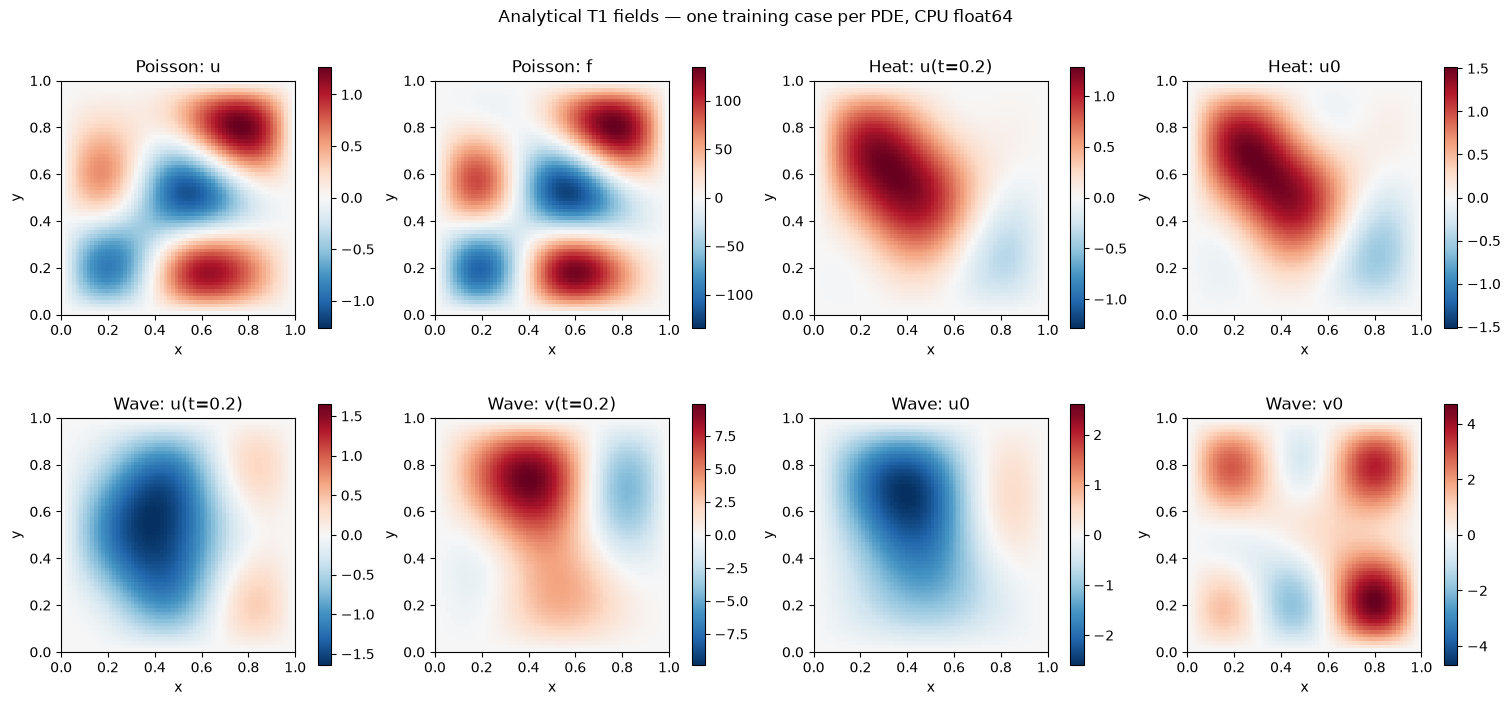

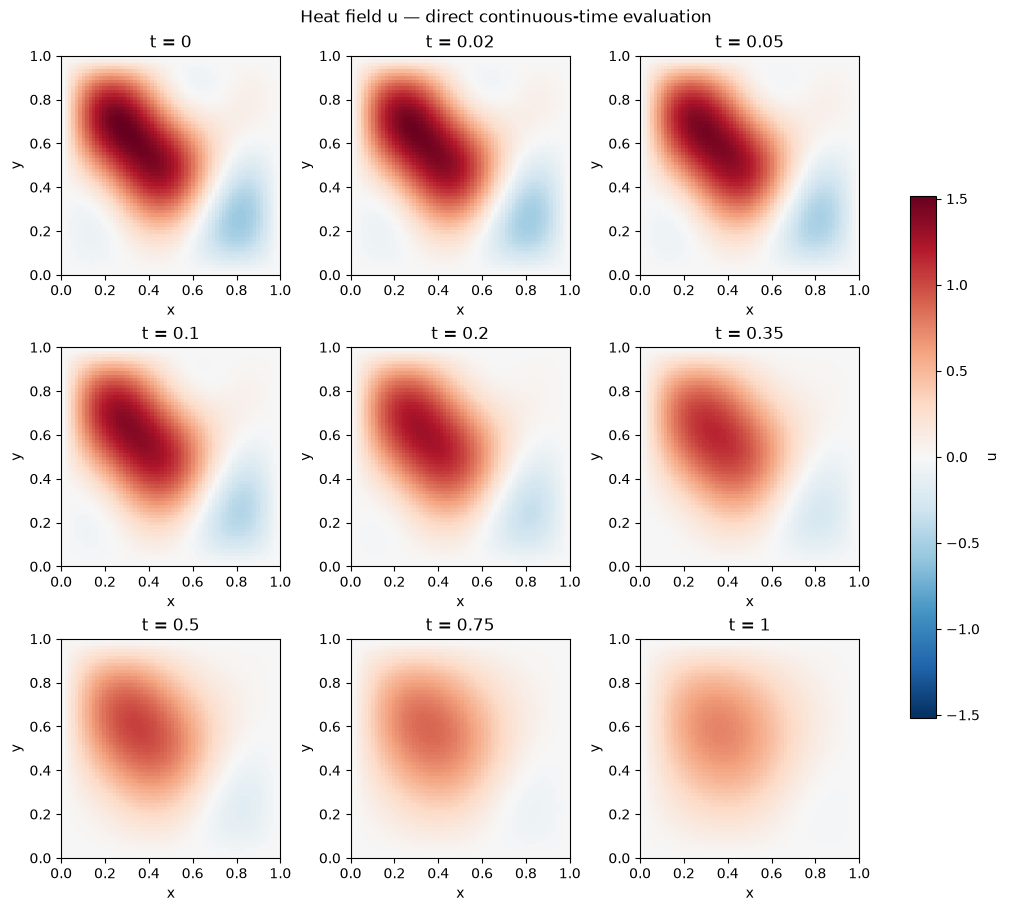

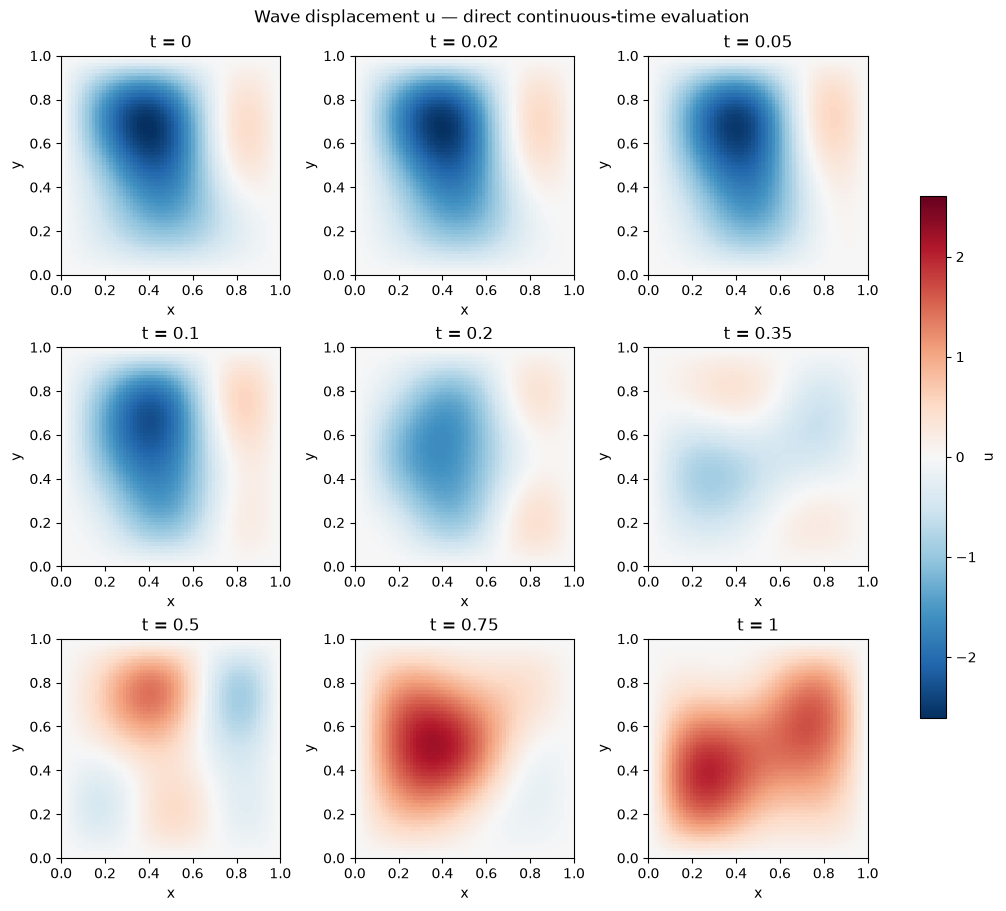

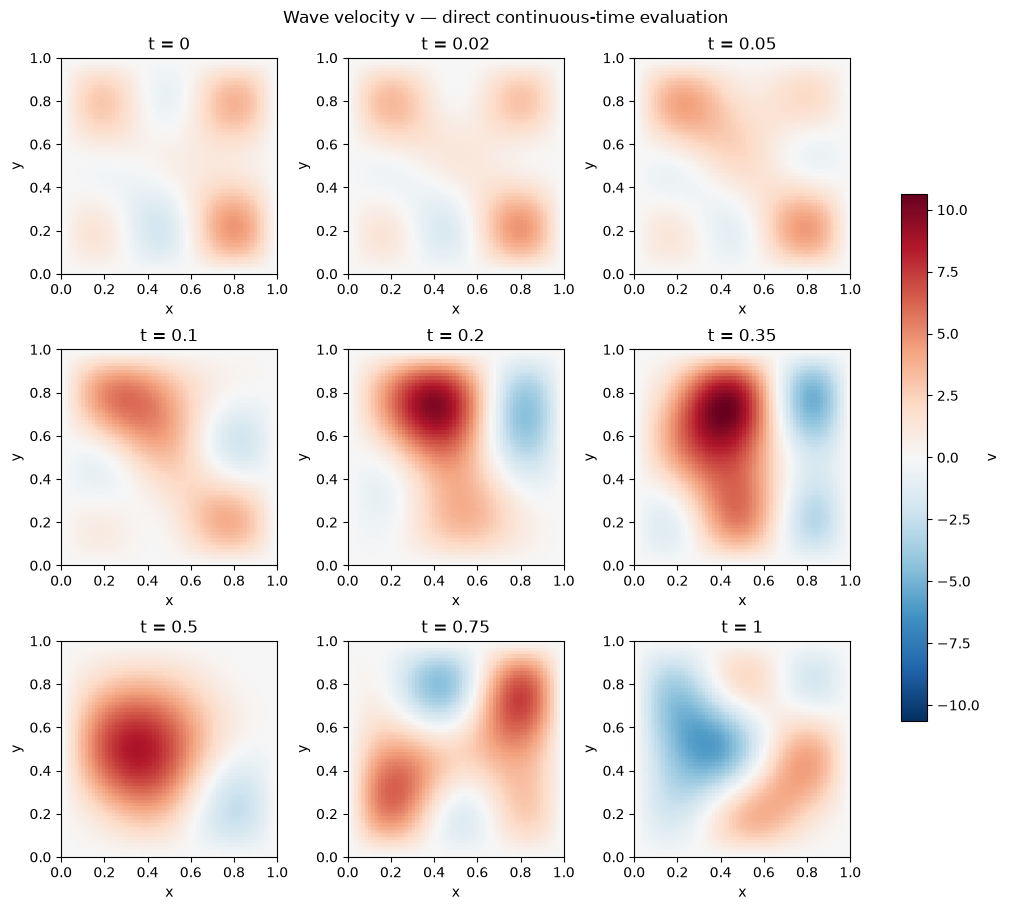

legacy-pdeep-13: completed; detailed output saved to reports/notebook_legacy/13899bca08f8d78462aebbce8ba5a4d255172b2ac9d113861ba0a897187d6370/legacy-pdeep-13.txt
Section 05 accepted | source 13899bca08f8 | active configuration identities {'CONFIG': {'owner': 'pdeep-06', 'identity': '74e91dcccf787d28570975ff97a25bed227e606de04b6dc64b4bc0319a1047ce'}}


In [8]:
with NOTEBOOK_LEDGER.cell('pdeep-13',globals()):
    with legacy_output("legacy-pdeep-13"):
        import time
        import matplotlib.pyplot as plt
        from pdeep.core import digest
        from pdeep.data import CaseDataset, SENSOR_COUNTS, persist_json
        from pdeep.reference_checks import mathematical_checks
        from pdeep.plotting import reference_fields, time_slices
        
        assert_sources_current()
        require(CONFIG.identity == CONFIG_ID, "configuration changed: rerun section 03")
        DATASET = CaseDataset(CONFIG.root_seed)
        RUN_ID = digest({"source": SOURCE_ID, "config": CONFIG_ID, "dataset": DATASET.identity})
        RUN_DIR = ROOT / "reports/reference" / RUN_ID
        RUN_DIR.mkdir(parents=True, exist_ok=True)
        REF_CASES = tuple(DATASET.case("train", p, 0) for p in SENSOR_COUNTS)
        MATH_CHECKS = mathematical_checks(CONFIG.root_seed)
        require(MATH_CHECKS["passed"], "reference mathematical checks failed")
        (RUN_DIR / "mathematics.json").write_text(json.dumps(MATH_CHECKS, indent=2) + "\n")
        print(json.dumps({k:v for k,v in MATH_CHECKS.items() if k != "checks"}, indent=2))
        display(Markdown("| Check | Maximum absolute error | Physical term scale | Tolerance | Pass |\n|---|---:|---:|---:|---|\n" +
            "\n".join(f"| {c['name']} | {c['max_abs_error']:.3e} | {c['physical_term_scale']:.3e} | {c['tolerance']:.3e} | {c['passed']} |" for c in MATH_CHECKS["checks"])))
        PLOT_PATHS = []
        def save_show(figure, filename):
            path = RUN_DIR / filename
            figure.savefig(path, dpi=120)
            PLOT_PATHS.append(str(path.relative_to(ROOT)))
            display(figure)
            plt.close(figure)
        save_show(reference_fields(REF_CASES), "reference_fields.png")
        save_show(time_slices(REF_CASES[1]), "heat_times.png")
        save_show(time_slices(REF_CASES[2]), "wave_u_times.png")
        save_show(time_slices(REF_CASES[2], quantity_id=1), "wave_v_times.png")
        print("PASS: CPU float64 analytical identities, independent autograd derivatives and NumPy mode-loop oracle.")
        print("Run:", RUN_ID, "Config:", CONFIG_ID, "Source:", SOURCE_ID)
print("Section 05 accepted | source",SOURCE_ID[:12],"| active configuration identities",NOTEBOOK_LEDGER.snapshot()["bindings"])


## 06. Case generation and splits

Required state: passing section 05 reference checks. Settings: fixed contract
12,000/1,024/1,024 cases/PDE; lazy coefficient generation. Calibration budget:
512 independent training-prior draws × 128 full-interior training-risk coordinates
per PDE, using a separate calibration stream. No held-out case enters calibration.
Dynamic calibration/query times use 12.5% zero, 12.5% early, 75% uniform [0,1].
Both wave quantities use the same calibration coordinates/times.

Outputs: disjoint case-ID ranges, dataset/split identities, coefficient histograms,
RMS quantity scales and exact prior coefficient scales. RMS is a finite Monte Carlo
estimate; it is persisted with its budget/provenance. Histogram cases are training
cases. Cost: bounded calibration and 256 prior cases/PDE; no dense field dataset.
Reruns are idempotent for a fixed source/config and preserve prior run directories.

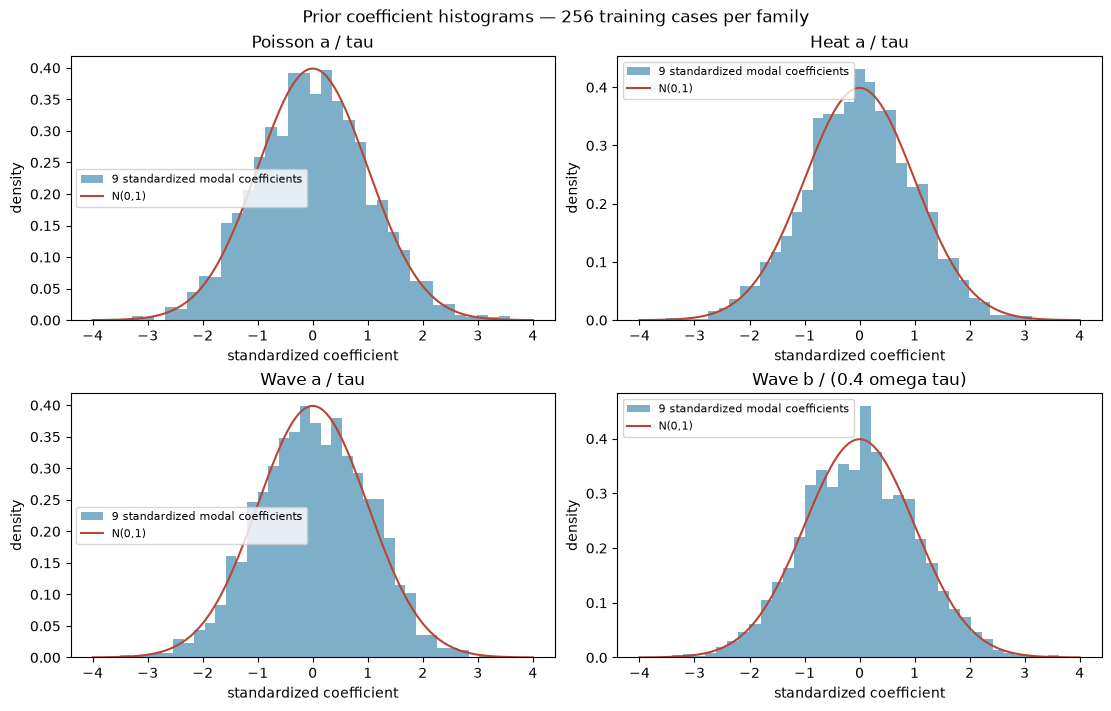

legacy-pdeep-15: completed; detailed output saved to reports/notebook_legacy/13899bca08f8d78462aebbce8ba5a4d255172b2ac9d113861ba0a897187d6370/legacy-pdeep-15.txt
Section 06 accepted | source 13899bca08f8 | active configuration identities {'CONFIG': {'owner': 'pdeep-06', 'identity': '74e91dcccf787d28570975ff97a25bed227e606de04b6dc64b4bc0319a1047ce'}, 'NORMALIZERS': {'owner': 'pdeep-15', 'identity': 'b08242e6946c4612b24523bf27dc087f2f4e38d0de758555d1775b8b0bc377a2'}}


In [9]:
with NOTEBOOK_LEDGER.cell('pdeep-15',globals()):
    with legacy_output("legacy-pdeep-15"):
        from pdeep.data import calibrate, Normalizers
        from pdeep.plotting import prior_histograms
        assert_sources_current()
        require(CONFIG.identity == CONFIG_ID and DATASET.root_seed == CONFIG.root_seed, "stale config/data")
        CALIBRATION_STARTED = time.perf_counter()
        NORMALIZERS = calibrate(CONFIG.root_seed, cases=512, points_per_case=128)
        CALIBRATION_SECONDS = time.perf_counter() - CALIBRATION_STARTED
        NORMALIZER_PATH = NORMALIZERS.save(RUN_DIR / "normalizers")
        require(Normalizers.load(NORMALIZER_PATH) == NORMALIZERS, "normalizer serialization mismatch")
        persist_json(RUN_DIR / "dataset.json", DATASET.summary())
        print(json.dumps(DATASET.summary(), indent=2))
        print("Training-only RMS normalizers:", canonical_json(NORMALIZERS))
        print("Normalizer ID:", NORMALIZERS.identity, "Calibration seconds:", CALIBRATION_SECONDS)
        save_show(prior_histograms(DATASET, cases=256), "prior_histograms.png")
        print("PASS: lazy case generation; disjoint split ordinal ranges; persisted training-only calibration.")
        print("Run:", RUN_ID, "Config:", CONFIG_ID, "Source:", SOURCE_ID)
print("Section 06 accepted | source",SOURCE_ID[:12],"| active configuration identities",NOTEBOOK_LEDGER.snapshot()["bindings"])


## 07. Observation generation and plots

Required state: cases and persisted training-only normalizers. Settings: 32/48/64
sensors for Poisson/heat/wave. Positions uniform [0.05,0.95]² independently of
hidden field values; times 10% zero, 30% strictly (0,0.1), 60% [0.1,1], with
largest-remainder rounding and guaranteed zero/early coverage. Wave u/v balanced.
$\eta_i\sim\operatorname{logUniform}[0.02,0.08]$,
$\sigma_i=\eta_i s_q$, $y_i=H_i(u)+\sigma_i z_i$, $z_i\sim N(0,1)$ independent.

Outputs: scalar measurements, sensor overlays and time coverage; 128 supervised
queries/case with the 12.5/12.5/75 training-risk time mixture; 64×64 evaluation at
all nine specified times; query/observation IDs and compact shape/noise/timing
reports. Wave query labels are balanced; evaluation covers each quantity fully.
Clean values/noise/eta remain metadata outside the model input contract.
Cost: three example cases plus plots; no full dataset materialization.
Rerun: named observation sets regenerate exactly, including validation/test sets.

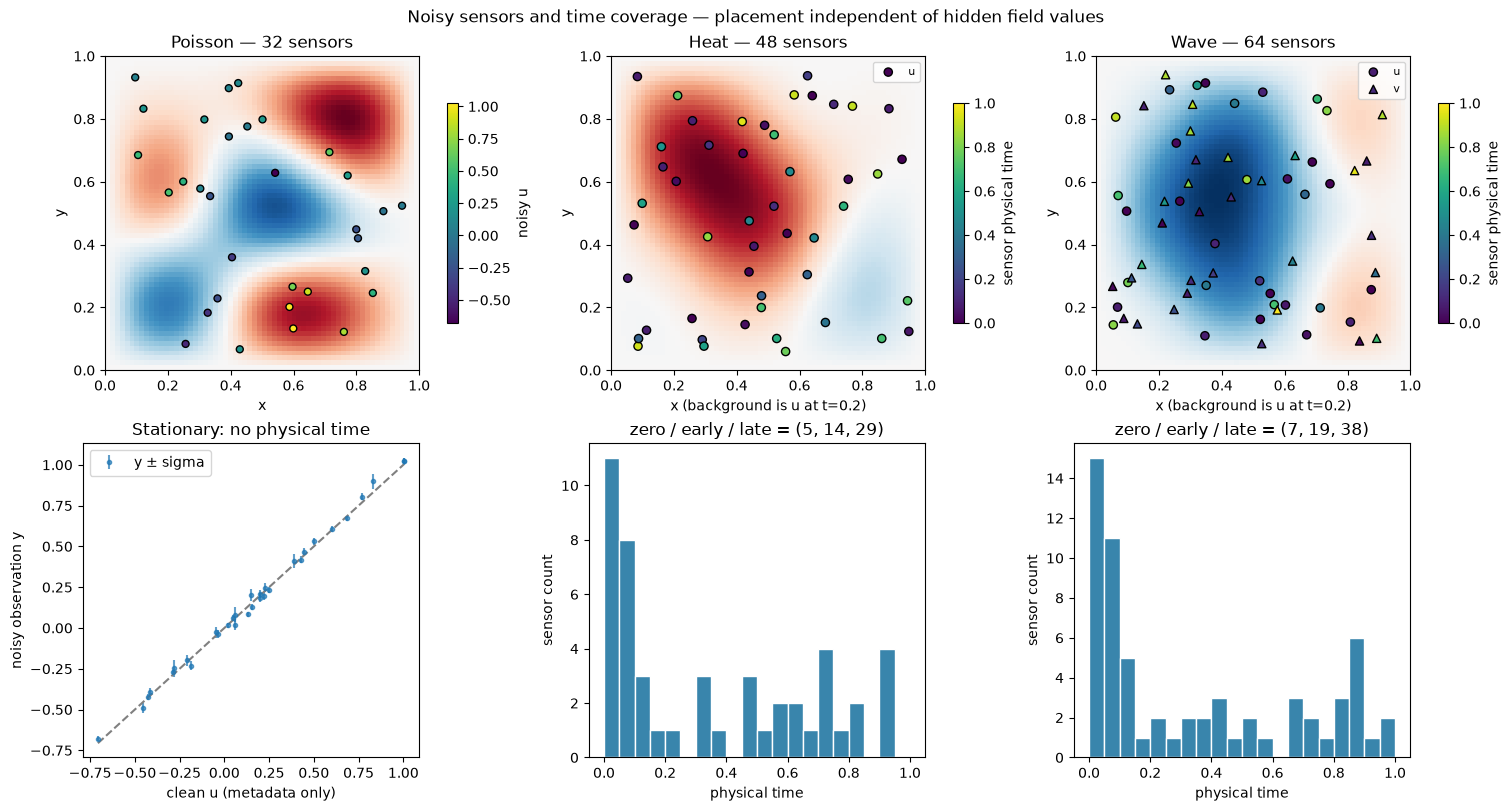

legacy-pdeep-17: completed; detailed output saved to reports/notebook_legacy/13899bca08f8d78462aebbce8ba5a4d255172b2ac9d113861ba0a897187d6370/legacy-pdeep-17.txt
Section 07 accepted | source 13899bca08f8 | active configuration identities {'CONFIG': {'owner': 'pdeep-06', 'identity': '74e91dcccf787d28570975ff97a25bed227e606de04b6dc64b4bc0319a1047ce'}, 'NORMALIZERS': {'owner': 'pdeep-15', 'identity': 'b08242e6946c4612b24523bf27dc087f2f4e38d0de758555d1775b8b0bc377a2'}}


In [10]:
with NOTEBOOK_LEDGER.cell('pdeep-17',globals()):
    with legacy_output("legacy-pdeep-17"):
        from pdeep.data import (observations, training_queries, reload_observations,
                                case_coefficients, collate_inputs, evaluation_grid)
        from pdeep.reference import evaluate_batch
        from pdeep.plotting import sensor_coverage
        assert_sources_current()
        require(CONFIG.identity == CONFIG_ID and NORMALIZERS.root_seed == CONFIG.root_seed, "stale configuration/calibration")
        DATA_STARTED = time.perf_counter()
        OBSERVATIONS = tuple(observations(DATASET, c, NORMALIZERS) for c in REF_CASES)
        QUERIES = tuple(training_queries(DATASET, c) for c in REF_CASES)
        RECORDS = []
        for case, obs, queries in zip(REF_CASES, OBSERVATIONS, QUERIES):
            path = obs.save(RUN_DIR / "observations")
            regenerated = reload_observations(path, DATASET, NORMALIZERS)
            require(regenerated.metadata.identity == obs.metadata.identity, "observation recipe mismatch")
            require(bool((obs.inputs.value == obs.metadata.clean + obs.metadata.noise).all()), "measurement identity failed")
            RECORDS.append({"pde": case.key.pde, "physical_case_id": case.key.physical_id,
                            "case_identity": case.identity, "observation_identity": obs.metadata.identity,
                            "query_identity": queries.identity, "observation_shape": list(obs.inputs.value.shape),
                            "query_shape": list(queries.target.shape), "time_counts": obs.metadata.time_counts,
                            "query_mixture_counts": queries.time_counts,
                            "sigma_range": [float(obs.inputs.sigma.min()), float(obs.inputs.sigma.max())],
                            "valid_count": int(obs.inputs.valid.sum()),
                            "noise_identity_max_error": float((obs.inputs.value-(obs.metadata.clean+obs.metadata.noise)).abs().max())})
        PACKED = collate_inputs([o.inputs for o in OBSERVATIONS])
        PACKED.validate(SPECS)
        PACKED_COEFFICIENTS = case_coefficients(REF_CASES)
        PACKED_PREDICTION = evaluate_batch(SPECS, PACKED_COEFFICIENTS, PACKED)
        DATA_SECONDS = time.perf_counter() - DATA_STARTED
        print(json.dumps(RECORDS, indent=2))
        print("Packed shapes:", tuple(PACKED.position.shape), tuple(PACKED.value.shape), tuple(PACKED_COEFFICIENTS.xi.shape))
        print("Active coefficient counts:", PACKED_COEFFICIENTS.active.sum(1).tolist())
        print("Tensor device/dtype:", PACKED.position.device, PACKED.position.dtype)
        save_show(sensor_coverage(REF_CASES, OBSERVATIONS), "sensor_coverage.png")
        STAGE_REPORT = {"run_id": RUN_ID, "source_sha256": SOURCE_ID, "config_sha256": CONFIG_ID,
                        "dataset_id": DATASET.identity, "normalizer_id": NORMALIZERS.identity,
                        "device": "cpu", "dtype": "float64", "mathematics": MATH_CHECKS,
                        "calibration_seconds": CALIBRATION_SECONDS, "data_seconds": DATA_SECONDS,
                        "records": RECORDS, "plots": PLOT_PATHS,
                        "unsupported": ["T2", "neural models", "training"]}
        (RUN_DIR / "reference_stage.json").write_text(json.dumps(STAGE_REPORT, indent=2) + "\n")
        (ROOT / "reports/latest_reference.json").write_text(json.dumps({"run_id": RUN_ID, "directory": str(RUN_DIR.relative_to(ROOT))}, indent=2)+"\n")
        print("PASS: reproducible scalar observations/queries, sigma/masks and persisted identities.")
        print("Data generation/reconstruction seconds:", DATA_SECONDS)
        print("Diagnostic bundle:", RUN_DIR)
        print("Reference/data verified. Continue with exact D in sections 08–09; no neural training.")
print("Section 07 accepted | source",SOURCE_ID[:12],"| active configuration identities",NOTEBOOK_LEDGER.snapshot()["bindings"])


## 08. Architecture selection and exact Gaussian D

Required state: verified T1 cases/operators and training-only normalizers from
01–07. Settings: D selected explicitly alongside CONFIG.architecture="A"; validation case 0/PDE;
default conditioning sensors and an independent named held-out sensor set.
No test cases select priors, ridge strengths or noise scales. Cost: millisecond
small-matrix conditioning. Zero trainable parameters. D has no neural weights; A is constructed below; B/C predictors are unsupported.

Let $\xi\sim N(m_0,C_0)$ and $y=H\xi+\epsilon$,
$\epsilon\sim N(0,R)$ with $R=\operatorname{diag}(\sigma_i^2)$ for valid rows.
Completing the square in the Gaussian prior and likelihood gives
$J=C_0^{-1}+H^TR^{-1}H$ and $h=C_0^{-1}m_0+H^TR^{-1}y$;
therefore $C_{post}=J^{-1}$, $m_{post}=C_{post}h$.

Numerically, use $C_0=L_0L_0^T$, $A=R^{-1/2}HL_0$,
$r=R^{-1/2}(y-Hm_0)$, and $K=I+A^TA=L_KL_K^T$.
Solve $K m_z=A^Tr$ and set $m_{post}=m_0+L_0m_z$,
$F=L_0L_K^{-T}$, $C_{post}=FF^T$. No inverse or jitter is formed.
Exactly noiseless valid measurements fail explicitly. Empty observations return
the prior exactly. Posterior mean and covariance are in physical modal units.

For query matrix $H_q$, mean is $H_qm_{post}$ and latent variance is
$\operatorname{diag}(H_qC_{post}H_q^T)$. A future noisy measurement adds
its own declared $\sigma_q^2$. Each posterior field sample uses one
$\xi^{(s)}=m_{post}+Fz^{(s)}$ across all coordinates, times and quantities.
No random posterior sample is called a posterior mean.

Outputs: selected architecture, analytical coefficient posterior and diagnostics.
Rerun under the same source/config; changes require rerunning upstream sections.

**poisson: exact coefficient posterior in physical units**

**heat: exact coefficient posterior in physical units**

**wave: exact coefficient posterior in physical units**

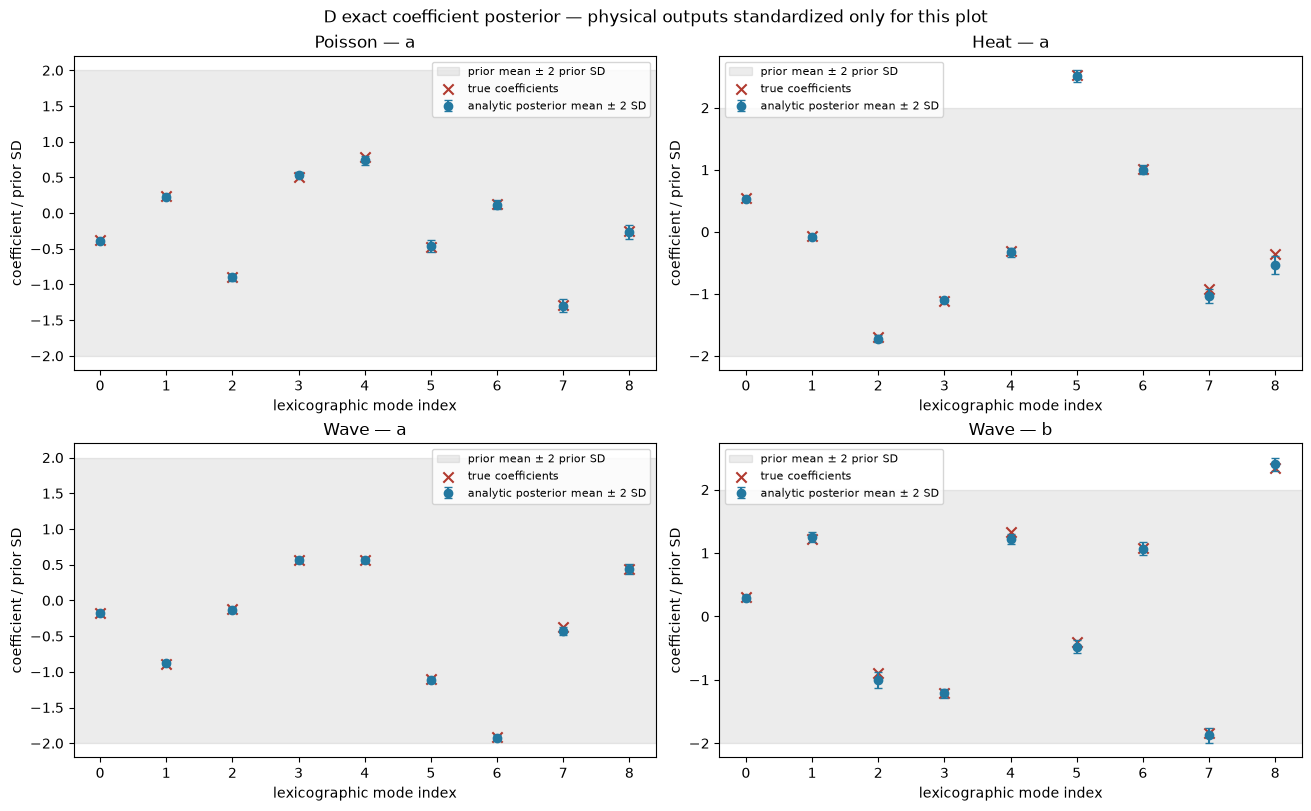

legacy-pdeep-19: completed; detailed output saved to reports/notebook_legacy/13899bca08f8d78462aebbce8ba5a4d255172b2ac9d113861ba0a897187d6370/legacy-pdeep-19.txt


In [11]:
with NOTEBOOK_LEDGER.cell('pdeep-19',globals()):
    with legacy_output("legacy-pdeep-19"):
        from pdeep.bayes import select_architecture
        from pdeep.bayes_plotting import coefficient_posteriors
        assert_sources_current()
        require(CONFIG.identity == CONFIG_ID, "stale configuration")
        D = select_architecture("D")
        print("Selected architecture:", D.architecture, "Trainable parameters:", D.trainable_parameters)
        D_CASES = tuple(DATASET.case("validation", spec.name, 0) for spec in SPECS)
        D_OBS = tuple(observations(DATASET, case, NORMALIZERS) for case in D_CASES)
        D_HELDOUT = tuple(observations(DATASET, case, NORMALIZERS, set_id="heldout") for case in D_CASES)
        D_FIT_STARTED = time.perf_counter()
        D_POST = tuple(D.fit(spec, obs.inputs) for spec,obs in zip(SPECS,D_OBS))
        D_FIT_SECONDS = time.perf_counter() - D_FIT_STARTED
        D_RUN_ID = digest({"source": SOURCE_ID, "config": CONFIG_ID, "dataset": DATASET.identity,
                           "normalizers": NORMALIZERS.identity})
        D_RUN_DIR = ROOT / "reports/bayes_D" / D_RUN_ID
        D_RUN_DIR.mkdir(parents=True, exist_ok=True)
        D_PLOT_PATHS = []
        def save_D(figure,filename):
            path = D_RUN_DIR / filename
            figure.savefig(path,dpi=120)
            D_PLOT_PATHS.append(str(path.relative_to(ROOT)))
            display(figure)
            plt.close(figure)
        for post in D_POST:
            display(Markdown(f"**{post.spec.name}: exact coefficient posterior in physical units**"))
            print("Posterior mean (not a draw):", post.mean.tolist())
            print("Posterior covariance:", post.covariance.tolist())
            print("Identifiability/conditioning:", json.dumps(post.diagnostics,indent=2))
        save_D(coefficient_posteriors(D_CASES,D_POST),"coefficient_posteriors.png")
        print("PASS: exact T1 Gaussian conditioning constructed for all PDEs.")
        print("Three fits, seconds:", D_FIT_SECONDS, "Run:", D_RUN_ID, "Config:", CONFIG_ID)


### Independent equation, observation, memory and query representations

Required state: validated SPECS, training-only NORMALIZERS and physical input
batches from sections 01–07. Settings: width 96, two typed message layers;
Fourier frequencies 1,2,4,8,16,32; two memory cross-attention layers, four heads;
16+64 geometry-owned interior anchors; all-anchor Gaussian retrieval, lengthscales 0.30 / 0.15. Device is explicitly
CONFIG.device, float32. Reference CPU float64 inputs are copied, not overwritten.
Cost: bounded forward/backward feature probes and three figures; no optimizer.

Each owner A/B/C has independently initialized parameter storage. These inventories
count Stage 3 feature utilities only. The complete Stage 4 A inventory follows separately. B and C allocate
no field memory by default. Coefficient tokens carry modes, xi, prior scales,
gradient/update attributes and active masks; diagnostic gradient/update attributes
are fixtures, not an implemented inverse refinement step.

Graph type/quantity/status/role embeddings and actual numerical coefficients feed
two bidirectional typed layers with ordered operands. Observation tokens use raw
coordinates/side distances, low/high Fourier features, normalized physical value,
normalized sigma and log sigma. Physical time is masked before and after its
Fourier encoding, with a distinct presence bit. Padding never conditions a token.

Memory uses geometric/known-field/equation context, masked observation attention
and cross-scale mixing. Global context is fixed across query chunks. Conditional
query features have no scalar output head. Coarse/fine Gaussian readouts are
separately normalized over every anchor and are smooth in query coordinates.
The memory-free coordinate path remains unchanged for future C.
Plots show untrained embeddings and attention, not scientific predictions.

Outputs: representation diagram, compact token statistics, anchor/attention views,
shapes, parameter counts, logical memory/MAC estimates and derivative-path checks.
Safe rerun under the same source/config. Any change requires upstream reruns.


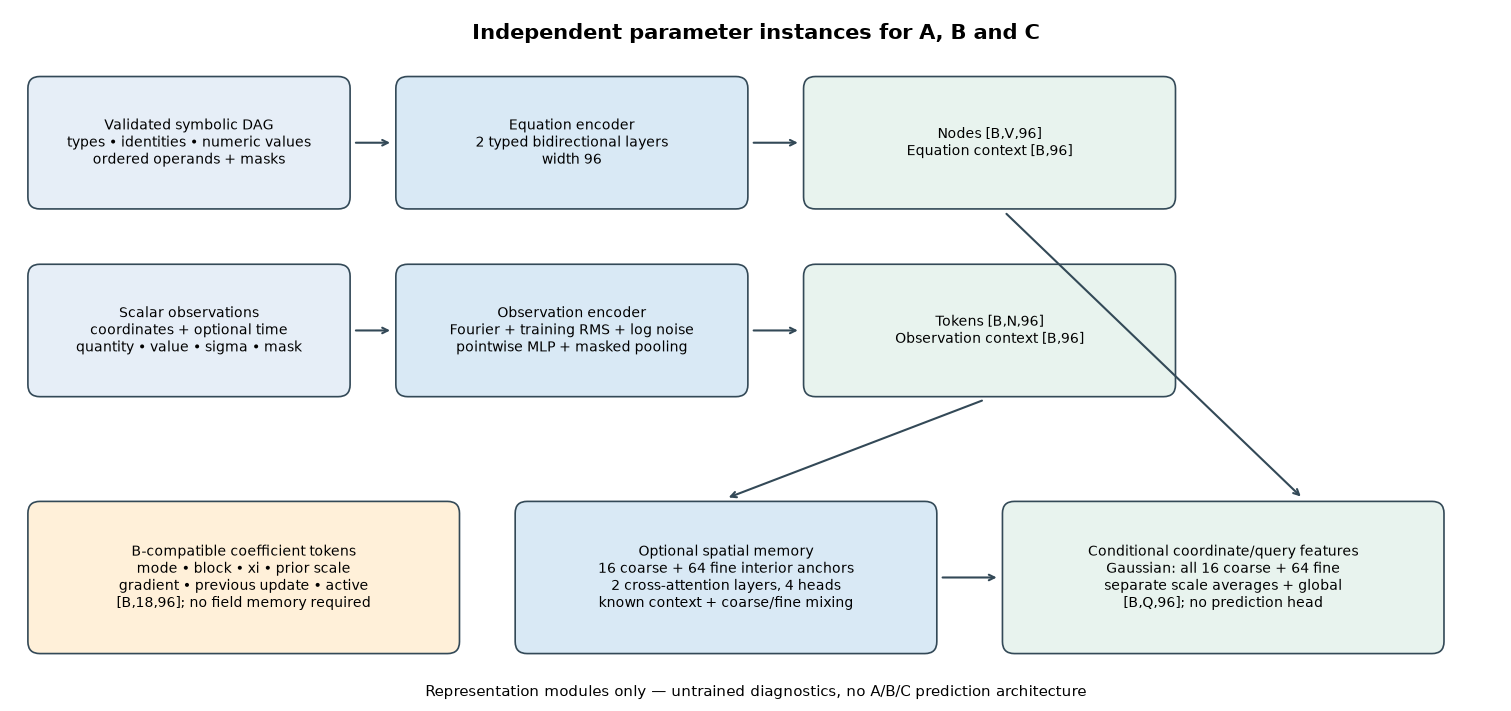

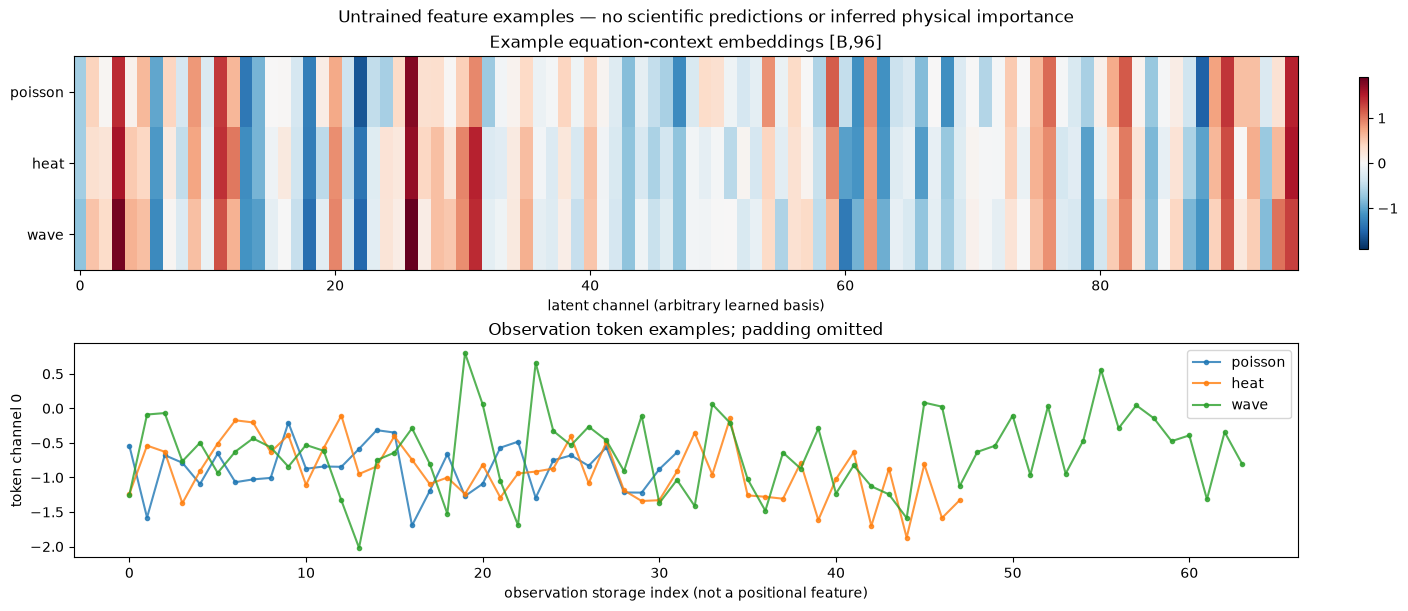

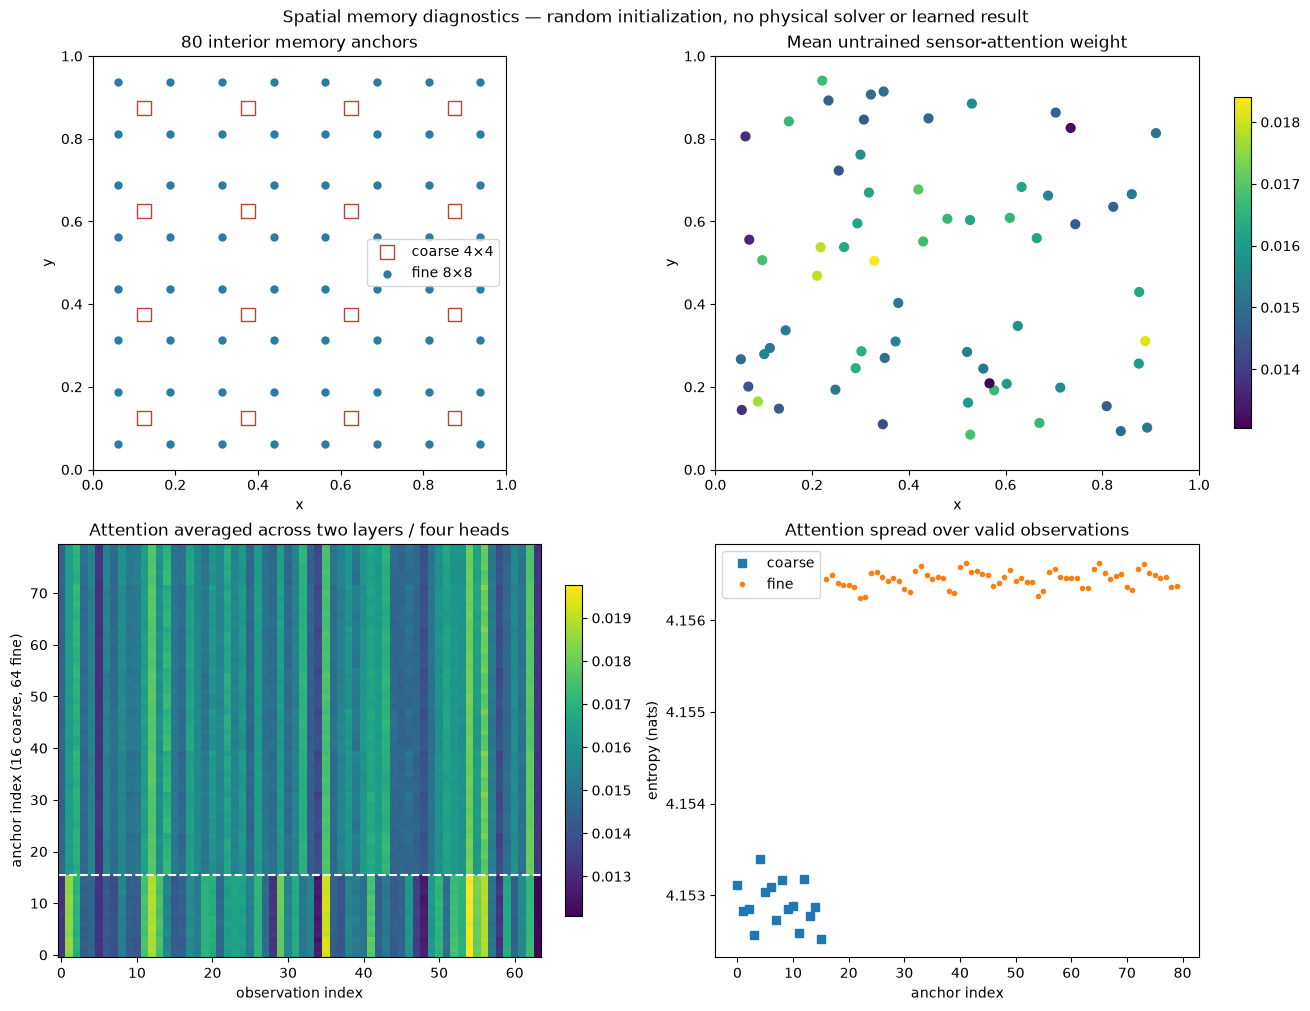

| Representation | Shape |
|---|---|
| graph_nodes | [3, 15, 96] |
| equation_context | [3, 96] |
| observation_tokens | [3, 64, 96] |
| observation_summary | [3, 96] |
| memory | [3, 80, 96] |
| attention | [3, 2, 4, 80, 64] |
| query | [3, 128, 96] |
| retrieval | [3, 128, 96] |
| coefficient_tokens | [3, 18, 96] |

| Owner inventory | Equation | Observation | Query | Coefficient | Optional memory | Retrieval | Total |
|---|---:|---:|---:|---:|---:|---:|---:|
| A | 156288 | 15680 | 52448 | 13712 | 247208 | 37152 | 522488 |
| B | 156288 | 15680 | 52448 | 13712 | 0 | 0 | 238128 |
| C | 156288 | 15680 | 52448 | 13712 | 0 | 0 | 238128 |

legacy-pdeep-21: completed; detailed output saved to reports/notebook_legacy/13899bca08f8d78462aebbce8ba5a4d255172b2ac9d113861ba0a897187d6370/legacy-pdeep-21.txt


In [12]:
with NOTEBOOK_LEDGER.cell('pdeep-21',globals()):
    with legacy_output("legacy-pdeep-21"):
        import torch
        from pdeep.encoding import EquationVocabulary,pack_graphs
        from pdeep.representations import build_representations,float32_batch
        from pdeep.representation_checks import representation_checks
        from pdeep.representation_plotting import representation_diagram,embedding_examples,memory_attention
        assert_sources_current()
        require(CONFIG.identity == CONFIG_ID, "stale representation configuration")
        REP_REPORT = representation_checks(device=CONFIG.device,root_seed=CONFIG.root_seed,normalizers=NORMALIZERS)
        require(REP_REPORT["passed"], "representation checks failed")
        REP_VOCABULARY = EquationVocabulary.from_specs(SPECS)
        REP_OWNERS = {owner:build_representations(owner,NORMALIZERS,REP_VOCABULARY,root_seed=CONFIG.root_seed).to(CONFIG.device).eval()
                      for owner in ("A","B","C")}
        MODEL_OBS = float32_batch(PACKED,device=CONFIG.device)
        MODEL_QUERIES = float32_batch(collate_inputs([q.inputs for q in QUERIES]),device=CONFIG.device)
        REP_GRAPH = pack_graphs(SPECS,REP_VOCABULARY).to(CONFIG.device)
        with torch.no_grad():
            REP_EQ = REP_OWNERS["A"].equation(REP_GRAPH)
            REP_OBS = REP_OWNERS["A"].observation(MODEL_OBS,SPECS)
            REP_MEMORY = REP_OWNERS["A"].memory(REP_OBS,REP_EQ.context,return_attention=True)
            REP_QUERY = REP_OWNERS["A"].query(MODEL_QUERIES,SPECS,REP_EQ.context,REP_OBS.summary)
            REP_RETRIEVED = REP_OWNERS["A"].retrieval(REP_MEMORY,MODEL_QUERIES,REP_QUERY,SPECS)
        REP_RUN_ID = digest({"source":SOURCE_ID,"vocabulary":REP_REPORT["vocabulary_id"],
                             "normalizers":NORMALIZERS.identity,"device":CONFIG.device})
        REP_RUN_DIR = ROOT / "reports/representations" / REP_RUN_ID
        REP_RUN_DIR.mkdir(parents=True,exist_ok=True)
        REP_PLOTS = []
        def save_representation(figure,filename):
            path = REP_RUN_DIR / filename
            figure.savefig(path,dpi=120)
            REP_PLOTS.append(str(path.relative_to(ROOT)))
            display(figure)
            plt.close(figure)
        save_representation(representation_diagram(),"representation_diagram.png")
        save_representation(embedding_examples(REP_EQ,REP_OBS,SPECS),"embedding_examples.png")
        save_representation(memory_attention(REP_MEMORY,REP_OBS),"memory_attention.png")
        display(Markdown("| Representation | Shape |\n|---|---|\n"+
            "\n".join(f"| {key} | {shape} |" for key,shape in REP_REPORT["shapes"].items())))
        display(Markdown("| Owner inventory | Equation | Observation | Query | Coefficient | Optional memory | Retrieval | Total |\n|---|---:|---:|---:|---:|---:|---:|---:|\n"+
            "\n".join(f"| {owner} | "+" | ".join(str(count) for count in counts.values())+f" | {sum(counts.values())} |"
                        for owner,counts in REP_REPORT["parameters"].items())))
        print("Compact token statistics:",json.dumps(REP_REPORT["statistics"],indent=2))
        print("Attention summaries (untrained):",json.dumps(REP_REPORT["attention_summary"],indent=2))
        print("Logical float32 memory and MAC estimates (not actual peak memory):",json.dumps(REP_REPORT["estimates"],indent=2))
        print("Derivative paths (feature probe only; no parameter updates):",json.dumps(REP_REPORT["derivative_paths"],indent=2))
        print("Masks/invariance checks:",json.dumps(REP_REPORT["checks"],indent=2))
        print("Numeric coefficient embedding change (alpha 0.02 -> 0.04, encoding diagnostic only):",REP_REPORT["numeric_coefficient_embedding_max_change"])
        print("Independent owner parameter storage:",REP_REPORT["independent_parameter_storage"])
        REP_REPORT.update(source_sha256=SOURCE_ID,config_sha256=CONFIG_ID,run_id=REP_RUN_ID,plots=REP_PLOTS)
        (REP_RUN_DIR/"notebook_representations.json").write_text(json.dumps(REP_REPORT,indent=2,allow_nan=False)+"\n")
        (ROOT/"reports/latest_representations.json").write_text(json.dumps({"run_id":REP_RUN_ID,"directory":str(REP_RUN_DIR.relative_to(ROOT))},indent=2)+"\n")
        print("PASS: representation feature contracts, invariances and derivatives; this cell runs feature utilities only; complete A follows.")
        print("Representation bundle:",REP_RUN_DIR)


### Stage 3 review: smooth A retrieval before Stage 4

**Historical Stage 3 prerequisite, retained and rechecked for Stage 4.** The earlier hard 4/8 nearest-anchor selection can
replace a finite-weight token abruptly. Its pre-change measured feature jumps
are preserved in `docs/retrieval_topk_audit_v1.json`.

The revised A representation reads **all 16 coarse and all 64 fine anchors**.
For each scale separately,
$w_j(x)=\exp(-\|x-a_j\|^2/(2\ell^2))/\sum_k\exp(-\|x-a_k\|^2/(2\ell^2))$
and $m_s(x)=\sum_j w_j(x)m_j$, with $\ell_c=0.30$, $\ell_f=0.15$.
Stable softmax implements this exact ratio, without content logits or top-k.
The two readouts are separately fused with query features and fixed global
context. The output stays [B,Q,96]; the diagnostic weight axis is now 80, with
each scale summing to one (concatenated weights sum to two).

Geometry owns anchor placement, level labels and boundary features through an
injectable provider. Default square geometry, B coefficient tokens, C's memory-free
coordinate math, graph/observation encoders, physical cases and exact D are
preserved. Parameter counts below are representation utilities only, not A/B/C
model counts. A's revised inventory is 522,488; B/C remain 238,128 each with
independent trainable storage and no field memory by default.

Bounded checks compare float64 kernels/derivatives against an independent formula,
cross former neighbor-switch regions, and compare float32 fused query batches,
individual points and chunks. Figures show arbitrary feature differences, not
PDE reconstruction errors; old/new fusion bases differ. No optimizer or training.


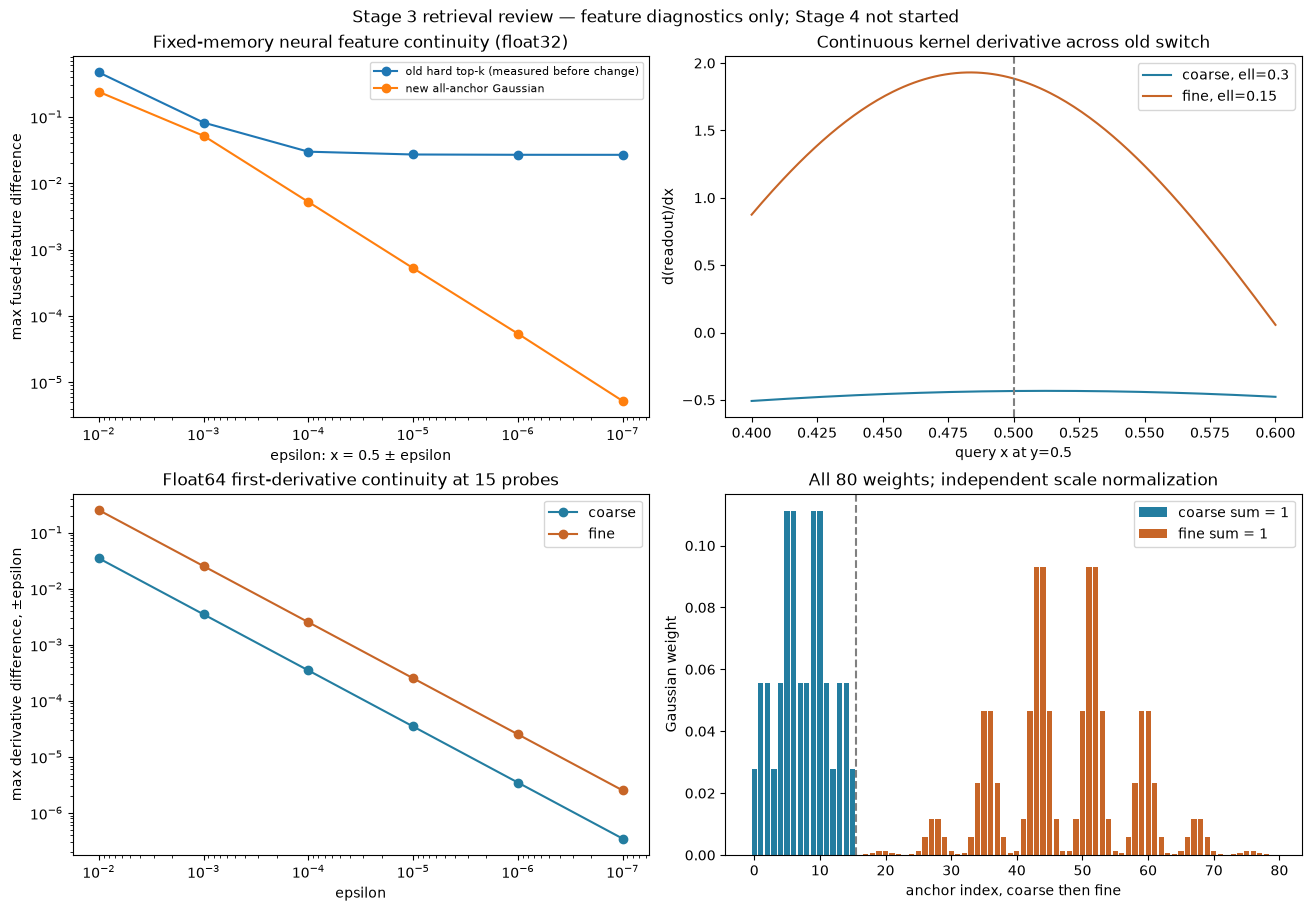

| Float64 kernel check | Max error | Tolerance |
|---|---:|---:|
| scale0/formula | 2.220e-16 | 2.000e-14 |
| scale0/weights | 2.776e-17 | 2.000e-14 |
| scale0/analytic_derivative | 2.609e-15 | 2.000e-13 |
| scale0/finite_difference_derivative | 2.865e-10 | 1.000e-07 |
| scale0/normalization | 2.220e-16 | 1.000e-14 |
| scale1/formula | 8.882e-16 | 2.000e-14 |
| scale1/weights | 6.939e-17 | 2.000e-14 |
| scale1/analytic_derivative | 2.665e-14 | 2.000e-13 |
| scale1/finite_difference_derivative | 5.446e-09 | 1.000e-07 |
| scale1/normalization | 5.551e-16 | 1.000e-14 |

legacy-pdeep-23: completed; detailed output saved to reports/notebook_legacy/13899bca08f8d78462aebbce8ba5a4d255172b2ac9d113861ba0a897187d6370/legacy-pdeep-23.txt


In [13]:
with NOTEBOOK_LEDGER.cell('pdeep-23',globals()):
    with legacy_output("legacy-pdeep-23"):
        from pdeep.retrieval_checks import kernel_checks,retrieval_checks
        from pdeep.retrieval_plotting import retrieval_review_figure
        assert_sources_current()
        require(CONFIG.identity == CONFIG_ID,"stale retrieval review configuration")
        REVIEW_KERNELS = kernel_checks()
        REVIEW_NEURAL = retrieval_checks(device=CONFIG.device,root_seed=CONFIG.root_seed)
        require(REVIEW_KERNELS["passed"] and REVIEW_NEURAL["passed"],"smooth retrieval verification failed")
        REVIEW_LEGACY = json.loads((ROOT/"docs/retrieval_topk_audit_v1.json").read_text())
        REVIEW_ID = digest({"source":SOURCE_ID,"device":CONFIG.device,"version":"gaussian-retrieval-v2"})
        REVIEW_DIR = ROOT/"reports/retrieval_review"/REVIEW_ID
        REVIEW_DIR.mkdir(parents=True,exist_ok=True)
        figure = retrieval_review_figure(REVIEW_KERNELS,REVIEW_NEURAL,REVIEW_LEGACY)
        figure.savefig(REVIEW_DIR/"retrieval_continuity.png",dpi=120)
        display(figure);plt.close(figure)
        display(Markdown("| Float64 kernel check | Max error | Tolerance |\n|---|---:|---:|\n"+
            "\n".join(f"| {c['name']} | {c['max_abs_error']:.3e} | {c['tolerance']:.3e} |" for c in REVIEW_KERNELS["checks"])))
        print("Fused float32 derivative and batching diagnostics:",json.dumps(REVIEW_NEURAL,indent=2))
        print("Kernel continuity convergence:",json.dumps(REVIEW_KERNELS["scales"],indent=2))
        REVIEW_REPORT = {"version":"gaussian-retrieval-v2","passed":True,"run_id":REVIEW_ID,
                         "source_sha256":SOURCE_ID,"config_sha256":CONFIG_ID,"kernels":REVIEW_KERNELS,
                         "neural":REVIEW_NEURAL,"legacy":REVIEW_LEGACY,"stage4_started":True,"training":False,
                         "plots":[str((REVIEW_DIR/"retrieval_continuity.png").relative_to(ROOT))]}
        (REVIEW_DIR/"notebook_retrieval_review.json").write_text(json.dumps(REVIEW_REPORT,indent=2,allow_nan=False)+"\n")
        (ROOT/"reports/latest_retrieval_review.json").write_text(json.dumps({"run_id":REVIEW_ID,"directory":str(REVIEW_DIR.relative_to(ROOT))},indent=2)+"\n")
        print("PASS: Gaussian all-anchor retrieval is ready as a Stage 4 prerequisite; complete A follows.")


### Complete Architecture A: independent direct inverse mapping

Required state: training-only NORMALIZERS, validated specs and explicit device.
A owns new independently seeded trainable modules; no B/C weights or optimizer
state is shared. The preceding A/B/C counts describe utilities, not full models.

$z_G=G_\theta(P,\kappa)$, $z_O=O_\theta(O)$,
$M=\operatorname{Mix}(\operatorname{CrossAttention}(M_0,z_O))$.
Two typed graph layers use operator/operand/field identities and actual known
numbers. A's observation tokenizer uses raw coordinates plus frequencies
$1,2,4,8$, quantity embeddings, $y/s_q$, $\sigma/s_q$, $\log(\sigma/s_q)$.
Stationary time is absent, including its Fourier cosines. N=0 has zero pooled
observation features and zero attention updates, with finite geometry/graph context.

The geometry provider supplies 16/64 cell-center anchors, four side features,
minimum external-boundary distance, nonperiodic fine axial neighbors, complete
coarse connectivity and four nearest coarse reads per fine anchor. Known scalar
values, their masks, known homogeneous boundary value and an unknown-field mask
initialize normalized memory; hidden source/initial fields never enter.

For each of two four-head blocks, $Q=M W_Q$, $K=O W_K$, $V=O W_V$,
$A=\operatorname{softmax}_{valid}(QK^T/\sqrt{24}+\beta)$.
Bias sees anchor-minus-sensor displacement, distance, masked time, quantity
embedding and log normalized sigma. Residual/LN and width-192 SiLU FFN follow.
A geometry local/global residual block then mixes spatial information once.
Attention weights are learned diagnostic weights, not physical influence.

All-anchor Gaussian retrieval uses the separately normalized coarse/fine formula
above. Four width-128 SiLU hidden layers have skips wherever dimensions agree;
independent u/v scalar heads share the trunk. Outputs are
$s_q x(1-x)y(1-y)\,raw_q$ via an explicit square Dirichlet boundary interface.
The auxiliary head predicts standardized xi and maps to physical prior units;
inactive slots are exactly zero. Neither xi_hat nor a solver produces A's field.
No PDE, initial condition or wave $v=u_t$ is enforced by A.


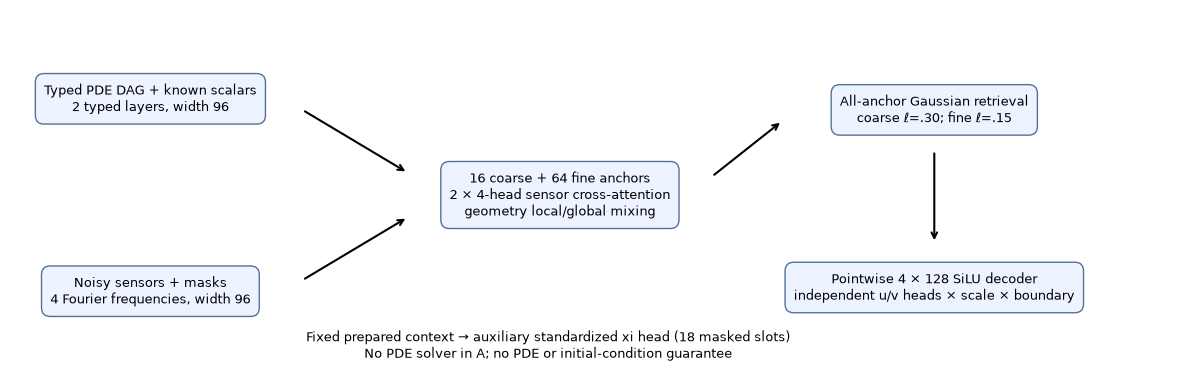

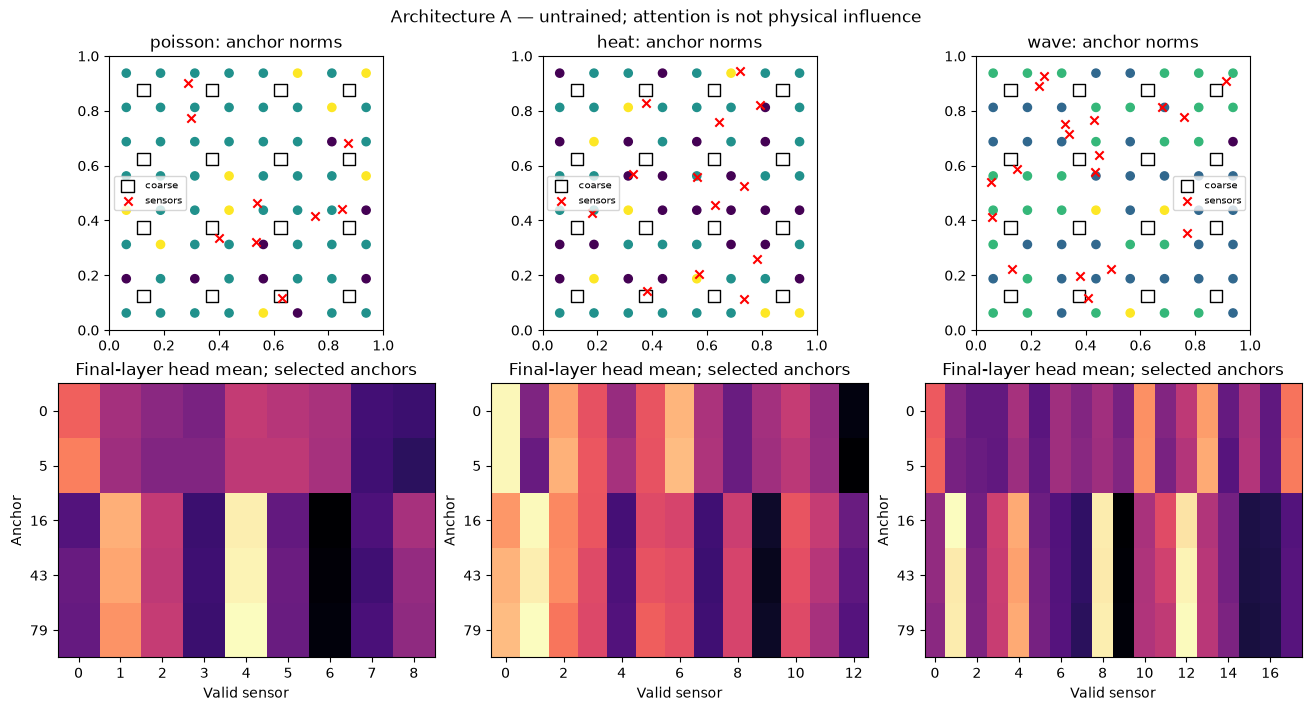

legacy-1689b69f: completed; detailed output saved to reports/notebook_legacy/13899bca08f8d78462aebbce8ba5a4d255172b2ac9d113861ba0a897187d6370/legacy-1689b69f.txt


In [14]:
with NOTEBOOK_LEDGER.cell('1689b69f',globals()):
    with legacy_output("legacy-1689b69f"):
        from pdeep.models import select_architecture as select_model
        from pdeep.a_checks import mixed_fixture, architecture_a_checks
        from pdeep.a_plotting import architecture_diagram, memory_summary, field_examples, training_curve
        assert_sources_current()
        A = select_model("A",normalizers=NORMALIZERS,root_seed=CONFIG.root_seed).to(CONFIG.device)
        A_CONFIG_ID = CONFIG_ID
        A_BATCH = mixed_fixture(NORMALIZERS,CONFIG.device)
        A_RUN_ID = digest({"source":SOURCE_ID,"config":CONFIG_ID,"normalizer":NORMALIZERS.identity,"stage":"A-direct-v1"})
        A_RUN_DIR = ROOT / "reports/architecture_A" / A_RUN_ID
        A_RUN_DIR.mkdir(parents=True,exist_ok=True)
        A_PLOTS = []
        def save_A(figure,filename):
            path=A_RUN_DIR/filename
            figure.savefig(path,dpi=110)
            A_PLOTS.append(str(path.relative_to(ROOT)))
            display(figure);plt.close(figure)
        print("Complete A learned parameters by component:",json.dumps(A.parameter_inventory(),indent=2))
        print("Complete A total:",sum(A.parameter_inventory().values()))
        print("A/B/C utility counts above are not full-model counts; all instances have independent storage.")
        save_A(architecture_diagram(),"architecture.png")
        save_A(memory_summary(A,NORMALIZERS,status="untrained"),"memory_untrained.png")


### C: observation-conditioned FiLM neural field, with physical constraints

Required state: verified scientific/reference inputs and training-only normalizers.
Cost: bounded CPU-float64 mathematical checks before any C optimizer update.
C has new graph/observation weights and **no 80-anchor memory**. Two masked
four-head observation self-attention blocks (96-wide, FFN192) interact over
sensors only. Masked pooling gives one observation summary. The global context is
$c=LN(W_Gz_G+W_Oz_O+W_\kappa\kappa+W_\Omega g_\Omega)\in\mathbb R^{96}$.
Neither source/initial realizations nor clean sensors enter this context.

The Stage 3 observation tokenizer remains six-frequency; C's coordinate features
use raw physical x/y and optional t with frequencies1,2,4,8. Time Fourier cosines
are masked too for Poisson. Each of four 128-wide smooth FiLM layers uses
$h^+=h+SiLU(LN(W_lh)(1+.1\tanh(W_{\gamma,l}c))+W_{\beta,l}c)$.
The u/v heads share this entire trunk and context. No query points interact.
Outputs multiply quantity RMS and the geometry-owned square Dirichlet factor.
This hard-enforces boundaries only. PDE, initial consistency and wave $u_t=v$
are soft penalties. Xi is an independent standardized head; its source/initial
fields are used in physical losses, never to generate the neural solution.


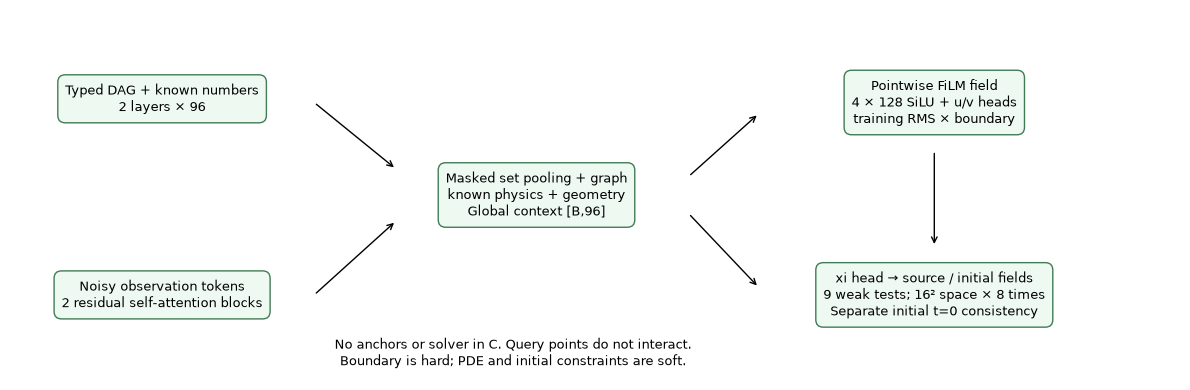

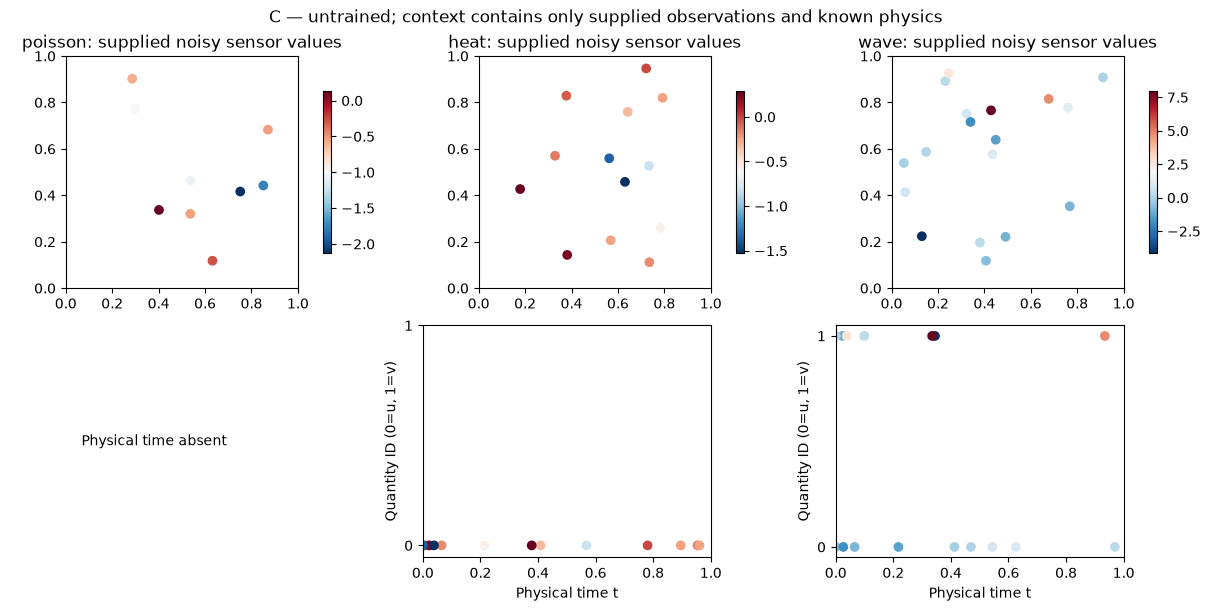

legacy-a285a87e: completed; detailed output saved to reports/notebook_legacy/13899bca08f8d78462aebbce8ba5a4d255172b2ac9d113861ba0a897187d6370/legacy-a285a87e.txt


In [15]:
with NOTEBOOK_LEDGER.cell('a285a87e',globals()):
    with legacy_output("legacy-a285a87e"):
        from pdeep.c_math_checks import mathematical_constraint_checks
        from pdeep.architecture_c import build_architecture_c
        from pdeep.c_plotting import architecture_diagram as C_diagram, observation_summary as C_sensors
        assert_sources_current()
        C_MATH=mathematical_constraint_checks()
        require(C_MATH["passed"],"C mandatory mathematical verification failed")
        C=select_model("C",normalizers=NORMALIZERS,root_seed=CONFIG.root_seed).to(CONFIG.device)
        C_BATCH=mixed_fixture(NORMALIZERS,CONFIG.device,queries=40)
        C_RUN_ID=digest({"source":SOURCE_ID,"config":CONFIG_ID,"normalizers":NORMALIZERS.identity,"stage":"C-field-weak-v1"})
        C_RUN_DIR=ROOT/"reports/architecture_C"/C_RUN_ID
        C_RUN_DIR.mkdir(parents=True,exist_ok=True)
        C_PLOTS=[]
        def save_C(figure,filename):
            path=C_RUN_DIR/filename
            figure.savefig(path,dpi=110);C_PLOTS.append(str(path.relative_to(ROOT)))
            display(figure);plt.close(figure)
        print("Independent complete C parameters:",json.dumps(C.parameter_inventory(),indent=2))
        print("Total:",sum(C.parameter_inventory().values()),"; global conditioning width96; no spatial memory")
        print("Exact initial RMS follows training-prior moments, not held-out calibration.")
        save_C(C_diagram(),"architecture.png")
        save_C(C_sensors(C,NORMALIZERS,status="untrained"),"sensors_times.png")
        print(json.dumps(C_MATH,indent=2))


### B0/B1: independently selectable learned inverse refinement

Both use $u_\xi=S_P(\xi;\kappa)$ and $\hat y=H\xi$ from the existing validated
physical operators, with three inverse steps. B0 has no spatial anchors. B1 adds
16 coarse/64 fine geometry-supplied anchors to the identical coefficient-state
architecture. New graph/observation/initializer/refiner weights belong to each
variant; no weights/optimizers are shared with each other or A/C.

Coefficient tokens encode xi, prior mean/scale, modal/a-b identity, current g,
previous update, equation and observation contexts. Two masked four-head96-wide
self-attention blocks with FFN192 predict a positive diagonal and step fraction.
B1 additionally injects candidate unknown fields and coefficient-gradient
projections, attends to sensors augmented with predicted/noise-standardized
residual values, and performs two geometry-local/coarse/global processing blocks
per inverse step. Spatial-to-coefficient attention supplies the SAME refiner.
Memory persists through k=0,1,2 for this case, resets for new inference, and never
replaces xi or directly decodes a solution.

Physics is explicitly CPU64; neural modules are selected-device32. Transfers and
casts retain autograd; no detach is used through the inverse path. B predictions
expose CPU64 physical values plus query-device/dtype values for the common tensor
contract. This is an explicit solver-device policy, not silent accelerator fallback.


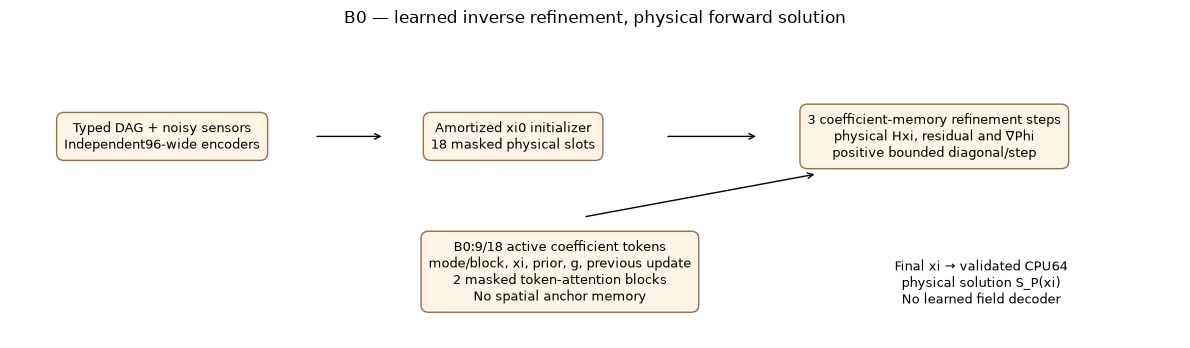

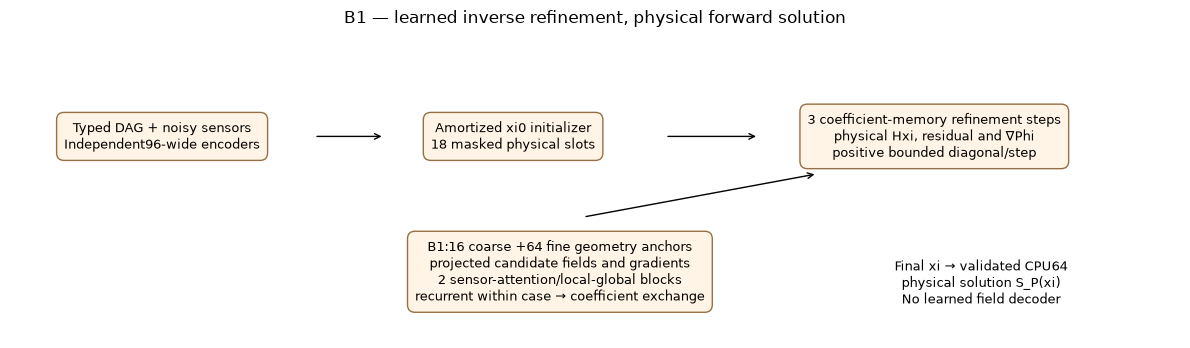

legacy-6426e6ec: completed; detailed output saved to reports/notebook_legacy/13899bca08f8d78462aebbce8ba5a4d255172b2ac9d113861ba0a897187d6370/legacy-6426e6ec.txt


In [16]:
with NOTEBOOK_LEDGER.cell('6426e6ec',globals()):
    with legacy_output("legacy-6426e6ec"):
        from pdeep.architecture_b import BAblation
        from pdeep.b_checks import inverse_math_checks,architecture_b_checks,estimate_summary
        from pdeep.b_plotting import (architecture_diagram as B_diagram,coefficient_trajectory as B_coefficients,
            sensor_iterations as B_sensors,objective_histories as B_objectives,spatial_fields as B_spatial_fields,
            spatial_attention as B_attention,field_comparison as B_fields,training_histories as B_training_curves)
        assert_sources_current()
        B_APPROACHES=("B0","B1")  # Explicit Stage6 comparison suite; or ("B0",) / ("B1",).
        require(bool(B_APPROACHES) and len(set(B_APPROACHES))==len(B_APPROACHES) and set(B_APPROACHES)<={"B0","B1"},"select B0/B1 explicitly")
        B_MATH=inverse_math_checks(NORMALIZERS)
        require(B_MATH["passed"],"B analytical inverse-gradient check failed")
        B_MODELS={name:select_model(name,normalizers=NORMALIZERS,root_seed=CONFIG.root_seed).to(CONFIG.device) for name in B_APPROACHES}
        B_BATCH=mixed_fixture(NORMALIZERS,CONFIG.device,queries=40)
        B_RUN_ID=digest({"source":SOURCE_ID,"config":CONFIG_ID,"approaches":B_APPROACHES,"normalizers":NORMALIZERS.identity,"stage":"B-inverse-v1"})
        B_RUN_DIR=ROOT/"reports/architecture_B"/B_RUN_ID
        B_RUN_DIR.mkdir(parents=True,exist_ok=True);B_PLOTS=[]
        def save_B(figure,filename):
            path=B_RUN_DIR/filename;figure.savefig(path,dpi=110);B_PLOTS.append(str(path.relative_to(ROOT)))
            display(figure);plt.close(figure)
        for name,model in B_MODELS.items():
            print(name,"learned parameters:",json.dumps(model.parameter_inventory()),"total",sum(model.parameter_inventory().values()))
            save_B(B_diagram(name),name+"_architecture.png")
        print(json.dumps(B_MATH,indent=2))


### Shared engine registry and fully resolved launch configuration

Exact IDs: A,C,B0,B1,D; D has no optimizer objective. Unsupported track, capacity,
precision, PDE, device or ambiguous B fails before neural initialization. The
actual scientific capability probe runs before each optimizer is created. C
exercises weak backward and strong spatial second derivatives; B declares its
existing differentiable CPU64 physical bridge explicitly.

One frozen configuration records source/run IDs, probabilities, batch/accumulation,
optimizer/schedule, successful-update budget and validation/checkpoint cadence.
The Stage7A small batch/query budget is explicit; C still uses all16×16×8 weak
quadrature and three-step B mechanisms remain intact. Run label affects artifact
paths only; named mathematical RNG keys exclude it and exclude monitoring cadence.


In [17]:
with NOTEBOOK_LEDGER.cell('98c696c3',globals()):
    from pdeep.train_types import ResolvedTrainConfig
    from pdeep.train_registry import REGISTRY
    from pdeep.training import TrainingEngine
    from pdeep.train_monitor import LiveMonitor
    from dataclasses import asdict
    import uuid
    assert_sources_current()
    TRAIN_APPROACHES=("A","C","B0","B1")  # Explicit Stage7A verification suite; select a singleton for one model.
    require(bool(TRAIN_APPROACHES) and len(set(TRAIN_APPROACHES))==len(TRAIN_APPROACHES) and set(TRAIN_APPROACHES)<={"A","C","B0","B1"},"neural selection must be explicit; D evaluation-only")
    RUN_LABEL="stage7A-"+uuid.uuid4().hex[:10]
    TRAIN_CONFIGS={name:ResolvedTrainConfig(name,device=CONFIG.device,root_seed=CONFIG.root_seed,source_id=SOURCE_ID,run_tag=RUN_LABEL,
        microbatch=1 if name=="C" else 2,accumulation=3 if name=="C" else 2,effective_batch=3,query_count=8,
        validation_cases_per_pde=1,validation_query_count=8,preset="smoke",updates=3,verbosity="normal") for name in TRAIN_APPROACHES}
    rows=list(asdict(next(iter(TRAIN_CONFIGS.values()))))
    display(Markdown("| Resolved setting | "+" | ".join(TRAIN_CONFIGS)+" |\n|---|"+"---|"*len(TRAIN_CONFIGS)+"\n"+
        "\n".join("| "+key+" | "+" | ".join(str(asdict(value)[key]) for value in TRAIN_CONFIGS.values())+" |" for key in rows)))
    display(Markdown("| ID | Trainable | Objective implementation | Derivatives | Checkpoint |\n|---|---|---|---|---|\n"+
        "\n".join(f"| {key} | {r.trainable} | {r.objective_implementation or 'exact Gaussian; no training'} | coordinate={r.coordinate_derivatives}, physical={r.physical_gradients} | {r.checkpoint_version} |" for key,r in REGISTRY.items())))
    print("Normal reports use one live display. Detailed/failure modes are available in ResolvedTrainConfig.")
print("Section 08 accepted | source",SOURCE_ID[:12],"| active configuration identities",NOTEBOOK_LEDGER.snapshot()["bindings"])


| Resolved setting | A | C | B0 | B1 |
|---|---|---|---|---|
| architecture | A | C | B0 | B1 |
| preset | smoke | smoke | smoke | smoke |
| pdes | ('poisson', 'heat', 'wave') | ('poisson', 'heat', 'wave') | ('poisson', 'heat', 'wave') | ('poisson', 'heat', 'wave') |
| probabilities | (0.3333333333333333, 0.3333333333333333, 0.3333333333333333) | (0.3333333333333333, 0.3333333333333333, 0.3333333333333333) | (0.3333333333333333, 0.3333333333333333, 0.3333333333333333) | (0.3333333333333333, 0.3333333333333333, 0.3333333333333333) |
| benchmark | unit_square_modal_v1 | unit_square_modal_v1 | unit_square_modal_v1 | unit_square_modal_v1 |
| inverse_track | T1 | T1 | T1 | T1 |
| capacity | canonical_v1 | canonical_v1 | canonical_v1 | canonical_v1 |
| device | cpu | cpu | cpu | cpu |
| precision | float32 | float32 | float32 | float32 |
| microbatch | 2 | 1 | 2 | 2 |
| accumulation | 2 | 3 | 2 | 2 |
| effective_batch | 3 | 3 | 3 | 3 |
| query_count | 8 | 8 | 8 | 8 |
| training_case_ids | None | None | None | None |
| learning_rate | 0.0003 | 0.0003 | 0.0003 | 0.0003 |
| weight_decay | 0.0001 | 0.0001 | 0.0001 | 0.0001 |
| grad_clip_norm | 1.0 | 1.0 | 1.0 | 1.0 |
| scheduler | constant | constant | constant | constant |
| warmup_updates | 250 | 250 | 250 | 250 |
| minimum_lr_fraction | 0.1 | 0.1 | 0.1 | 0.1 |
| updates | 3 | 3 | 3 | 3 |
| validation_every | 250 | 250 | 250 | 250 |
| checkpoint_every | 250 | 250 | 250 | 250 |
| validation_cases_per_pde | 1 | 1 | 1 | 1 |
| validation_query_count | 8 | 8 | 8 | 8 |
| validation_name | validation-v1 | validation-v1 | validation-v1 | validation-v1 |
| root_seed | 20261108 | 20261108 | 20261108 | 20261108 |
| verbosity | normal | normal | normal | normal |
| rolling_window | 50 | 50 | 50 | 50 |
| source_id | 13899bca08f8d78462aebbce8ba5a4d255172b2ac9d113861ba0a897187d6370 | 13899bca08f8d78462aebbce8ba5a4d255172b2ac9d113861ba0a897187d6370 | 13899bca08f8d78462aebbce8ba5a4d255172b2ac9d113861ba0a897187d6370 | 13899bca08f8d78462aebbce8ba5a4d255172b2ac9d113861ba0a897187d6370 |
| run_tag | stage7A-c9cc54ef1a | stage7A-c9cc54ef1a | stage7A-c9cc54ef1a | stage7A-c9cc54ef1a |
| full_training_enabled | False | False | False | False |
| overwrite_checkpoint | False | False | False | False |

| ID | Trainable | Objective implementation | Derivatives | Checkpoint |
|---|---|---|---|---|
| A | True | pdeep.a_training.objective | coordinate=False, physical=False | pdeep-artifact-v2/training_checkpoint |
| C | True | pdeep.c_training.objective | coordinate=True, physical=False | pdeep-artifact-v2/training_checkpoint |
| B0 | True | pdeep.b_training.coefficient_loss | coordinate=False, physical=True | pdeep-artifact-v2/training_checkpoint |
| B1 | True | pdeep.b_training.coefficient_loss | coordinate=False, physical=True | pdeep-artifact-v2/training_checkpoint |
| D | False | exact Gaussian; no training | coordinate=False, physical=False | exact-Gaussian-D-v1 |

Normal reports use one live display. Detailed/failure modes are available in ResolvedTrainConfig.
Section 08 accepted | source 13899bca08f8 | active configuration identities {'CONFIG': {'owner': 'pdeep-06', 'identity': '74e91dcccf787d28570975ff97a25bed227e606de04b6dc64b4bc0319a1047ce'}, 'NORMALIZERS': {'owner': 'pdeep-15', 'identity': 'b08242e6946c4612b24523bf27dc087f2f4e38d0de758555d1775b8b0bc377a2'}, 'TRAIN_CONFIGS': {'owner': '98c696c3', 'identity': 'd7d6f9d6827a2d9cb529d61266d7e5f197954f70b06b931e1cb6cfbe9f361ae9'}}


## 09. D prediction, independent checks and uncertainty

Required state: exact posteriors from 08. Settings: 20,000 bounded verification
draws/PDE, eight displayed coherent draws, 64×64 field slices at t=0.2 for
dynamic examples, same physical case and independent held-out sensors.
Cost: bounded verification and plots; no training or parameter fitting by SGD.

Check information-form conditioning against the independent covariance-form
formula $m_0+C_0H^T(HC_0H^T+R)^{-1}(y-Hm_0)$ and
$C_0-C_0H^T(HC_0H^T+R)^{-1}HC_0$ on tiny systems, using solves only.
Tests include empty/prior return, covariance symmetry/positivity/contraction,
operator checks and query/sample coherence. Monte Carlo empirical averages are
labeled as empirical checks, not exact posterior means; errors are compared to
their analytical Gaussian standard errors with a fixed six-SE bound.

Prior-only, ridge-regularized WLS and unregularized WLS use identical data and
coordinates. WLS in standardized $z$ solves $\|Az-r\|^2+\lambda\|z\|^2$.
At $\lambda=1$ its estimate equals the Gaussian MAP/posterior mean; that
equivalence is independently checked, not treated as a different estimator.

Plots show truth/sparse sensor positions, posterior mean, latent SD, held-out
noisy predictions, coherent sample traces and singular values. Displayed latent
intervals are pointwise, not simultaneous bands. Future measurement intervals
include declared noise. Conditioning-set scores are in-sample replicate
diagnostics; held-out scores use independent sensors. Marginal log-score sums
are distinct from the correlated joint log predictive density.
Outputs: pass/fail with maximum discrepancies, coefficient/field metrics, scores,
matrix conditioning and content-addressed diagnostics. Complete A checks follow; B/C remain unimplemented.

| Check | Error | Tolerance | Pass |
|---|---:|---:|---|
| correlated_prior/mean_forms | 9.992e-16 | 1.000e-11 | True |
| correlated_prior/covariance_forms | 4.441e-16 | 1.000e-12 | True |
| poisson/sensor_operator | 1.110e-16 | 1.000e-12 | True |
| poisson/mean_forms | 2.026e-14 | 1.000e-11 | True |
| poisson/covariance_forms | 9.159e-16 | 1.000e-11 | True |
| poisson/symmetry | 0.000e+00 | 1.000e-14 | True |
| poisson/positive_covariance | 0.000e+00 | 0.000e+00 | True |
| poisson/contraction_psd | 0.000e+00 | 1.000e-12 | True |
| poisson/MC_mean_standard_errors | 1.515e+00 | 6.000e+00 | True |
| poisson/MC_covariance_standard_errors | 2.229e+00 | 6.000e+00 | True |
| poisson/query_mean_chunks | 0.000e+00 | 1.000e-12 | True |
| poisson/query_variance_chunks | 1.084e-19 | 1.000e-12 | True |
| poisson/coherent_sample_chunks | 0.000e+00 | 1.000e-12 | True |
| poisson/augmented_LS_MAP | 1.665e-16 | 1.000e-11 | True |
| heat/sensor_operator | 2.220e-16 | 1.000e-12 | True |
| heat/mean_forms | 2.198e-14 | 1.000e-11 | True |
| heat/covariance_forms | 1.034e-15 | 1.000e-11 | True |
| heat/symmetry | 0.000e+00 | 1.000e-14 | True |
| heat/positive_covariance | 0.000e+00 | 0.000e+00 | True |
| heat/contraction_psd | 0.000e+00 | 1.000e-12 | True |
| heat/MC_mean_standard_errors | 1.103e+00 | 6.000e+00 | True |
| heat/MC_covariance_standard_errors | 3.218e+00 | 6.000e+00 | True |
| heat/query_mean_chunks | 0.000e+00 | 1.000e-12 | True |
| heat/query_variance_chunks | 1.084e-19 | 1.000e-12 | True |
| heat/coherent_sample_chunks | 0.000e+00 | 1.000e-12 | True |
| heat/augmented_LS_MAP | 4.441e-16 | 1.000e-11 | True |
| wave/sensor_operator | 1.110e-15 | 1.000e-12 | True |
| wave/mean_forms | 5.893e-14 | 1.000e-11 | True |
| wave/covariance_forms | 2.311e-15 | 1.000e-11 | True |
| wave/symmetry | 0.000e+00 | 1.000e-14 | True |
| wave/positive_covariance | 0.000e+00 | 0.000e+00 | True |
| wave/contraction_psd | 0.000e+00 | 1.000e-12 | True |
| wave/MC_mean_standard_errors | 1.476e+00 | 6.000e+00 | True |
| wave/MC_covariance_standard_errors | 2.667e+00 | 6.000e+00 | True |
| wave/query_mean_chunks | 0.000e+00 | 1.000e-12 | True |
| wave/query_variance_chunks | 0.000e+00 | 1.000e-12 | True |
| wave/coherent_sample_chunks | 0.000e+00 | 1.000e-12 | True |
| wave/augmented_LS_MAP | 1.249e-15 | 1.000e-11 | True |

| PDE | Estimate | Standardized coefficient RMSE | Query field RMSE |
|---|---|---:|---:|
| poisson | exact posterior mean | 0.02173 | 0.01457 |
| poisson | prior only | 0.6544 | 0.4011 |
| poisson | ridge=1 (same MAP) | 0.02173 | 0.01457 |
| poisson | unregularized WLS | 0.0216 | 0.01455 |
| heat | exact posterior mean | 0.06898 | 0.014 |
| heat | prior only | 1.198 | 0.3884 |
| heat | ridge=1 (same MAP) | 0.06898 | 0.014 |
| heat | unregularized WLS | 0.0702 | 0.01425 |
| wave | exact posterior mean | 0.04539 | 0.04917 |
| wave | prior only | 1.117 | 1.418 |
| wave | ridge=1 (same MAP) | 0.04539 | 0.04917 |
| wave | unregularized WLS | 0.04779 | 0.05091 |

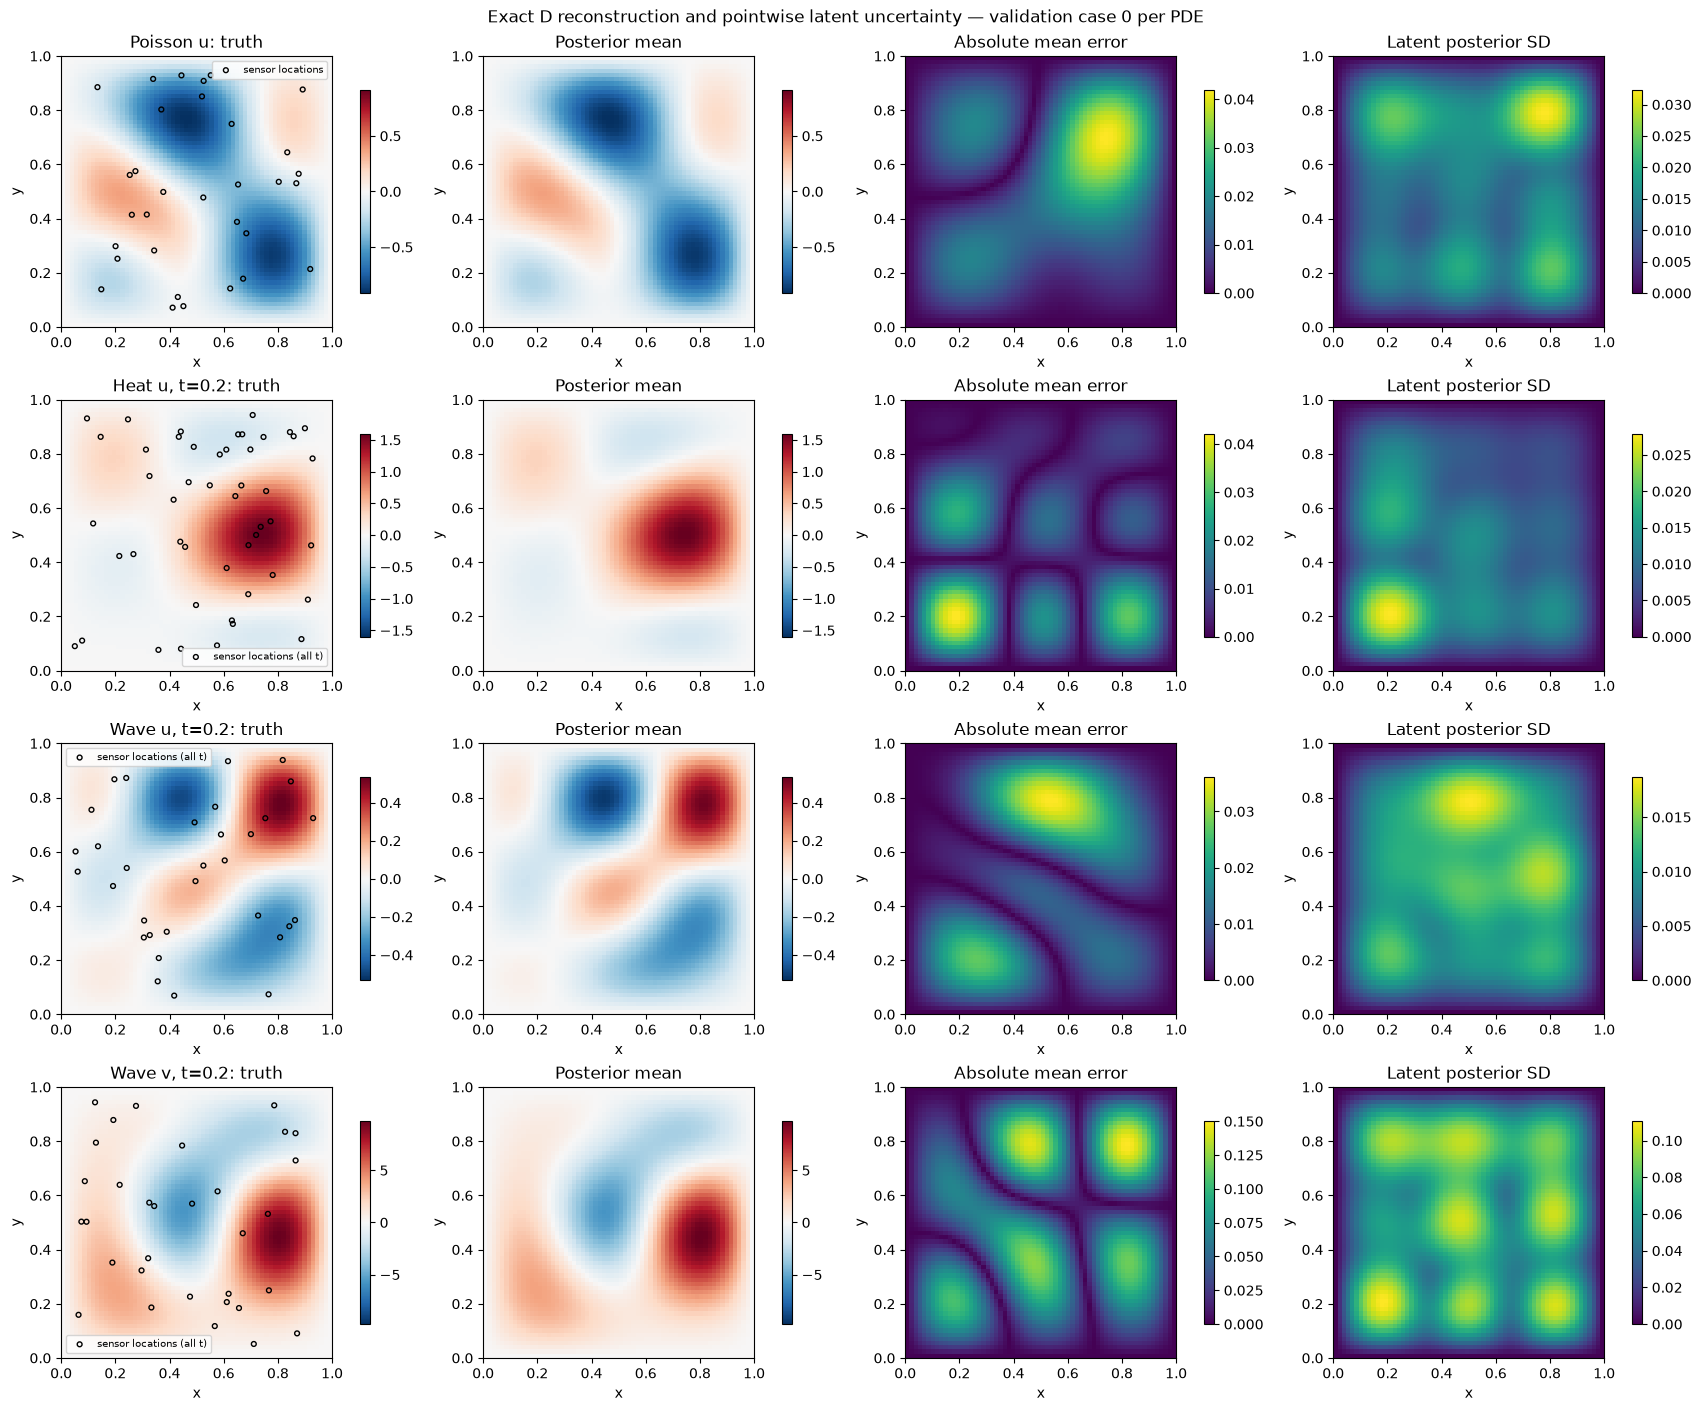

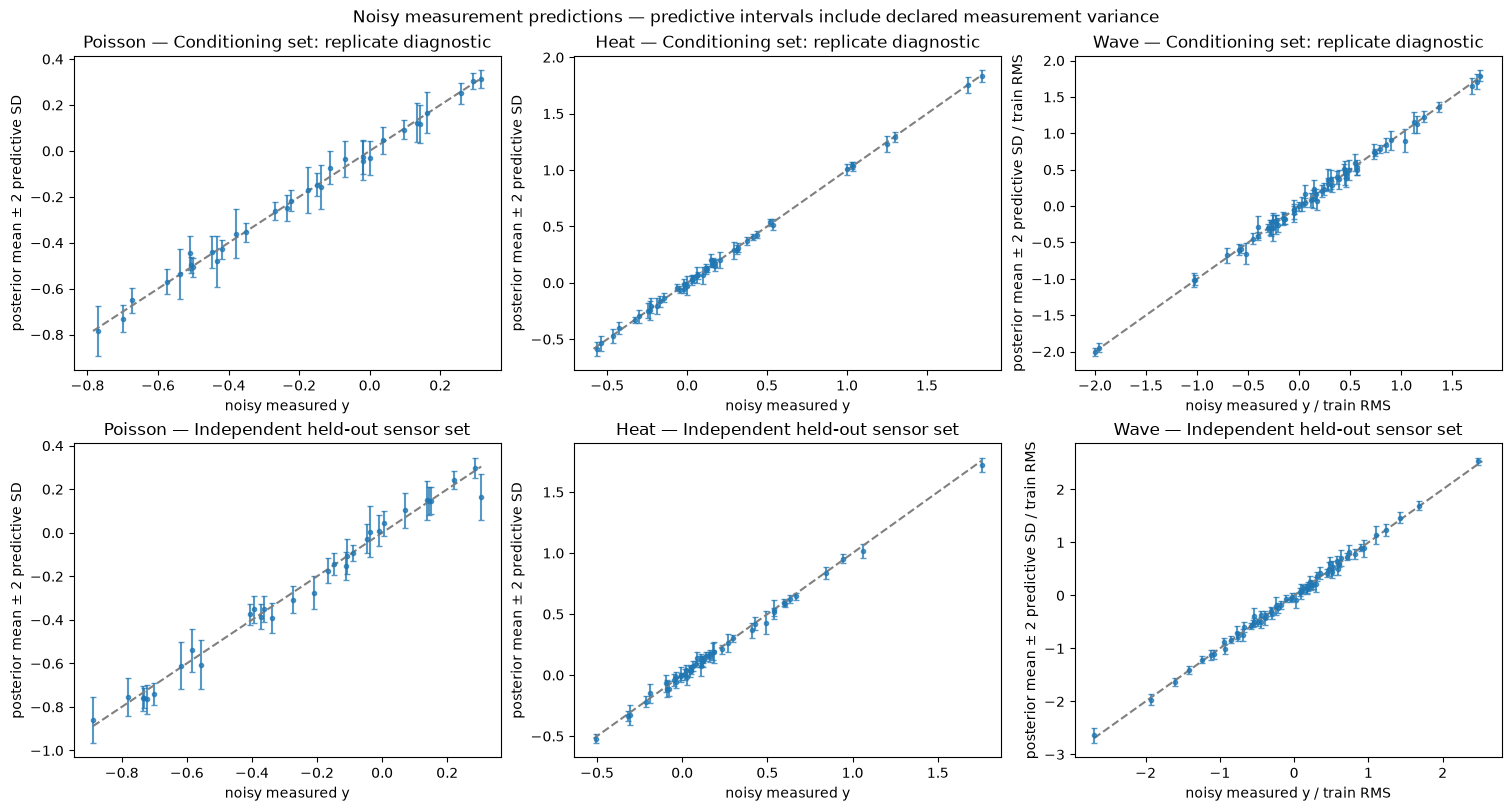

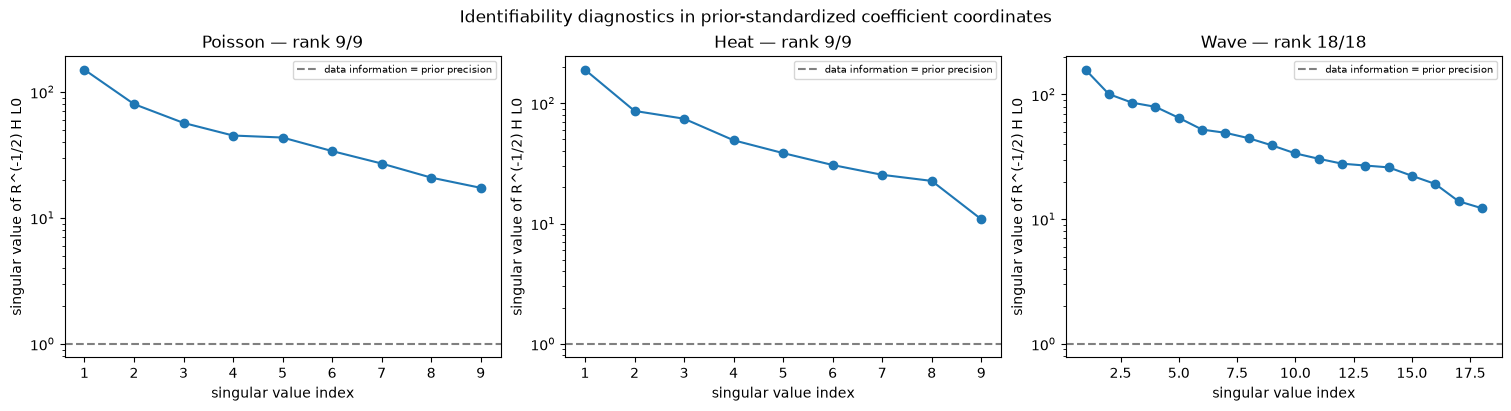

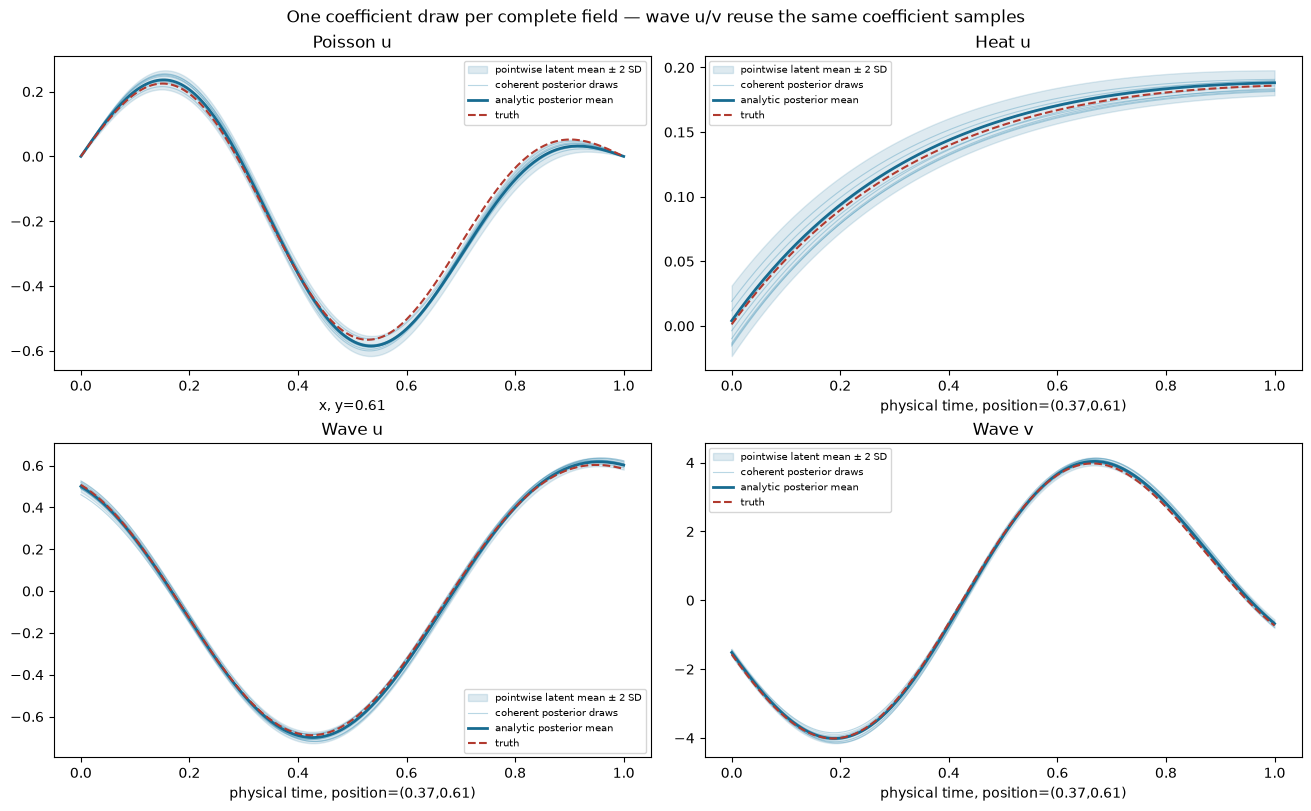

legacy-pdeep-25: completed; detailed output saved to reports/notebook_legacy/13899bca08f8d78462aebbce8ba5a4d255172b2ac9d113861ba0a897187d6370/legacy-pdeep-25.txt


In [18]:
with NOTEBOOK_LEDGER.cell('pdeep-25',globals()):
    with legacy_output("legacy-pdeep-25"):
        from pdeep.bayes_checks import bayesian_checks
        from pdeep.bayes_plotting import reconstructed_fields,heldout_predictions,identifiability,coherent_sample_traces
        assert_sources_current()
        require(CONFIG.identity == CONFIG_ID, "stale configuration")
        D_CHECKS = bayesian_checks(CONFIG.root_seed,draws=20000,normalizers=NORMALIZERS)
        require(D_CHECKS["passed"], "D independent verification failed")
        print(json.dumps({k:v for k,v in D_CHECKS.items() if k not in ("checks","examples")},indent=2))
        display(Markdown("| Check | Error | Tolerance | Pass |\n|---|---:|---:|---|\n" +
            "\n".join(f"| {c['name']} | {c['max_error']:.3e} | {c['tolerance']:.3e} | {c['passed']} |" for c in D_CHECKS["checks"])))
        display(Markdown("| PDE | Estimate | Standardized coefficient RMSE | Query field RMSE |\n|---|---|---:|---:|\n" +
            "\n".join(f"| {e['pde']} | {label} | {e[key]['standardized_rmse']:.4g} | {e['query_field_rmse'][field]:.4g} |"
            for e in D_CHECKS["examples"] for label,key,field in (
                ("exact posterior mean","posterior_mean_recovery","posterior_mean"),
                ("prior only","prior_only_recovery","prior_only"),
                ("ridge=1 (same MAP)","ridge_1_MAP_recovery","ridge_1_MAP"),
                ("unregularized WLS","unregularized_WLS_recovery","unregularized_WLS")))))
        for e in D_CHECKS["examples"]:
            print(e["pde"], "HELD-OUT sensor predictive scores:", e["heldout_scores"])
            print(e["pde"], "Conditioning replicate scores (in-sample):", e["conditioning_replicate_scores"])
            print(e["pde"], "Empirical sample mean/covariance checks:",
                  {k:v for k,v in e.items() if k.startswith("MC_")})
        D_BANKS = tuple(post.sample(8,generator=STREAMS.torch("posterior_samples",case.identity,"notebook"))
                        for case,post in zip(D_CASES,D_POST))
        save_D(reconstructed_fields(D_CASES,D_POST,[o.inputs for o in D_OBS]),"reconstruction_uncertainty.png")
        save_D(heldout_predictions(D_CASES,D_POST,D_OBS,D_HELDOUT,NORMALIZERS),"heldout_predictions.png")
        save_D(identifiability(D_POST),"identifiability.png")
        save_D(coherent_sample_traces(D_CASES,D_POST,D_BANKS),"coherent_samples.png")
        D_REPORT = {"run_id":D_RUN_ID,"source_sha256":SOURCE_ID,"config_sha256":CONFIG_ID,
                    "dataset_id":DATASET.identity,"normalizer_id":NORMALIZERS.identity,
                    "checks":D_CHECKS,"plots":D_PLOT_PATHS,"three_fits_seconds":D_FIT_SECONDS,
                    "device":"cpu","dtype":"float64","unsupported":["B","T2","research training"]}
        (D_RUN_DIR/"notebook_D.json").write_text(json.dumps(D_REPORT,indent=2,allow_nan=False)+"\n")
        (ROOT/"reports/latest_bayes_D.json").write_text(json.dumps({"run_id":D_RUN_ID,"directory":str(D_RUN_DIR.relative_to(ROOT))},indent=2)+"\n")
        print("PASS: exact Gaussian D verified, prior/noisy predictions and coherent samples available.")
        print("Diagnostic bundle:",D_RUN_DIR)
        print("Exact D verification complete. Continue to A forward, objective and bounded smoke checks.")


### A forward checks and untrained field examples

Required state: complete A and fixed training-only structural examples from 08.
Cost: bounded CPU/accelerator forward/backward checks; no optimizer. Reports
A1–A10, B=2 unequal sensor counts, empty observations, masks, chunk/individual
queries, actual observation sensitivities, known-number changes and gradients.
Untrained fields are execution examples, with no reconstruction-quality claim.


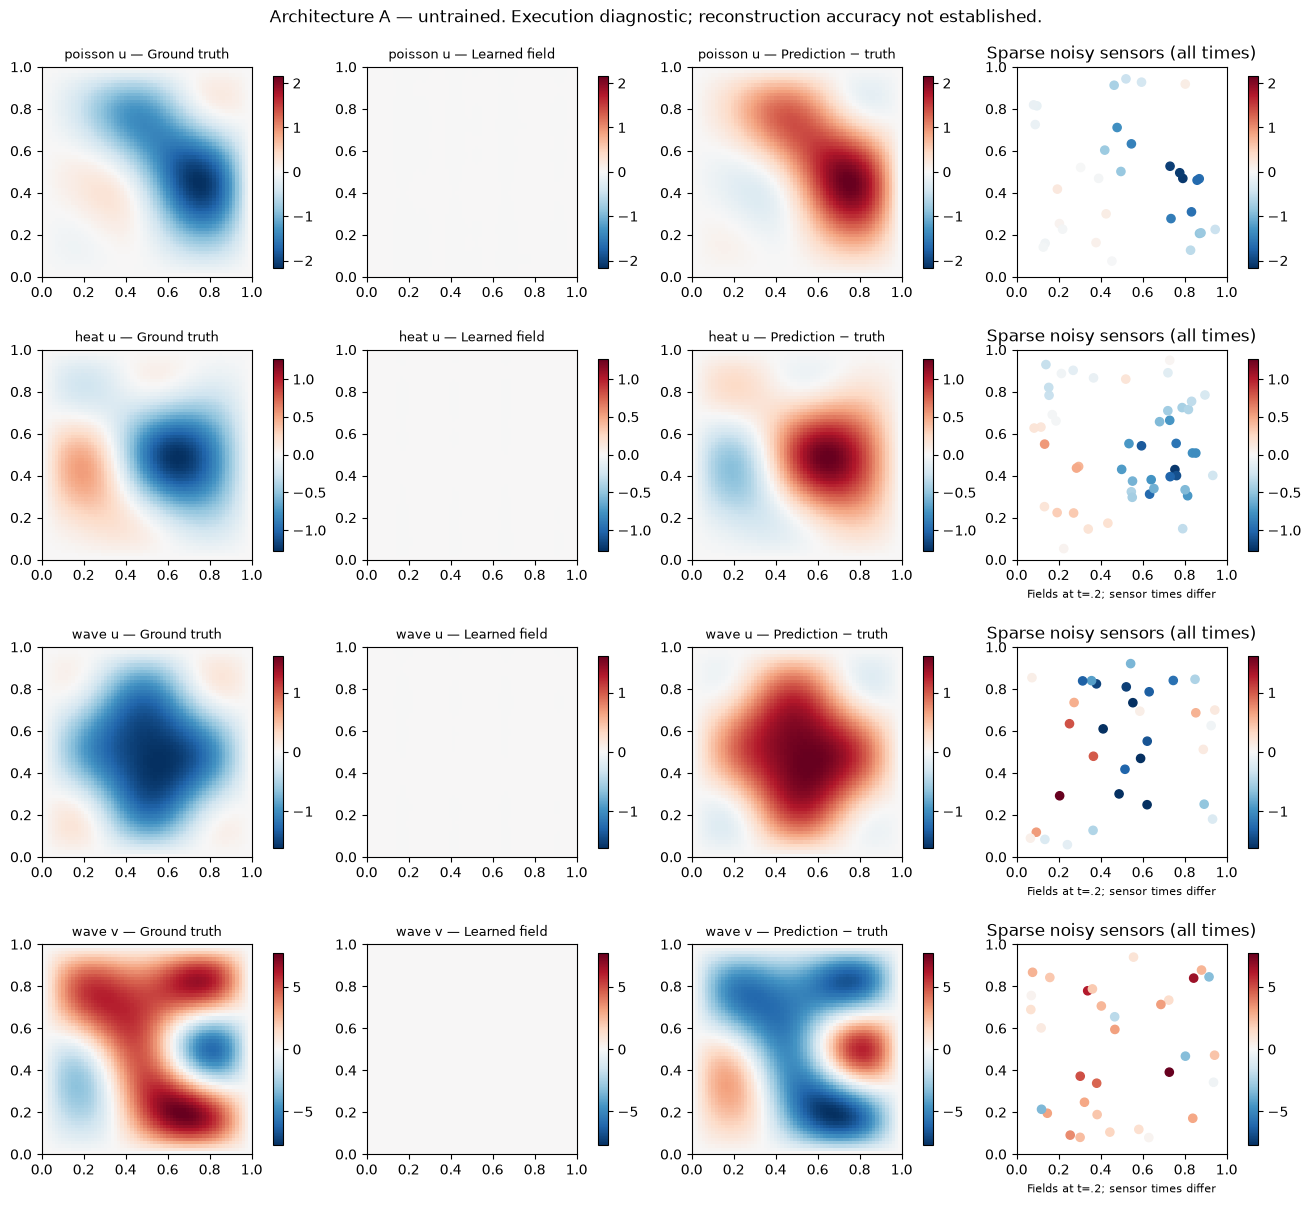

legacy-7464c91b: completed; detailed output saved to reports/notebook_legacy/13899bca08f8d78462aebbce8ba5a4d255172b2ac9d113861ba0a897187d6370/legacy-7464c91b.txt


In [19]:
with NOTEBOOK_LEDGER.cell('7464c91b',globals()):
    with legacy_output("legacy-7464c91b"):
        assert_sources_current()
        require(CONFIG.identity == A_CONFIG_ID,"stale A configuration")
        A_CHECKS = architecture_a_checks(NORMALIZERS,device=CONFIG.device)
        require(A_CHECKS["passed"],"Architecture A structural checks failed")
        A.eval()
        with torch.no_grad():
            A_OUTPUT=A(A_BATCH.specs,A_BATCH.observations,A_BATCH.queries,return_attention=True)
        print(json.dumps({"shapes":A_CHECKS["shapes"],"device":A_CHECKS["device"],"dtype":A_CHECKS["dtype"],
                          "checks":A_CHECKS["checks"],"sensitivity":A_CHECKS["sensitivities"],
                          "empty_observations":A_CHECKS["empty_observation_cases"]},indent=2))
        print("Anchor feature norms min/max:",float(A_OUTPUT.context.memory.tokens.norm(dim=-1).min()),float(A_OUTPUT.context.memory.tokens.norm(dim=-1).max()))
        save_A(field_examples(A,NORMALIZERS,status="untrained"),"fields_untrained.png")


### C forward, coordinate derivatives and independent strong diagnostics

Required state: passing exact weak-form checks. Cost: bounded full neural checks,
including five objective gradient paths and16/32 quadrature comparison, no updates.
Autograd differentiates physical x/y/t; the pointwise sum-gradient trick is checked
against individual queries. Neural derivatives remain on the selected device.
Strong diagnostic points are independent of spatial/time quadrature and training
queries. Strong forms $-\Delta u-f$, $u_t-\alpha\Delta u$, $u_t-v$ and
$v_t-c^2\Delta u$ are reported in physical and prior-normalized units, never added
to the default loss. Finite nine-mode weak projections cannot certify the PDE.


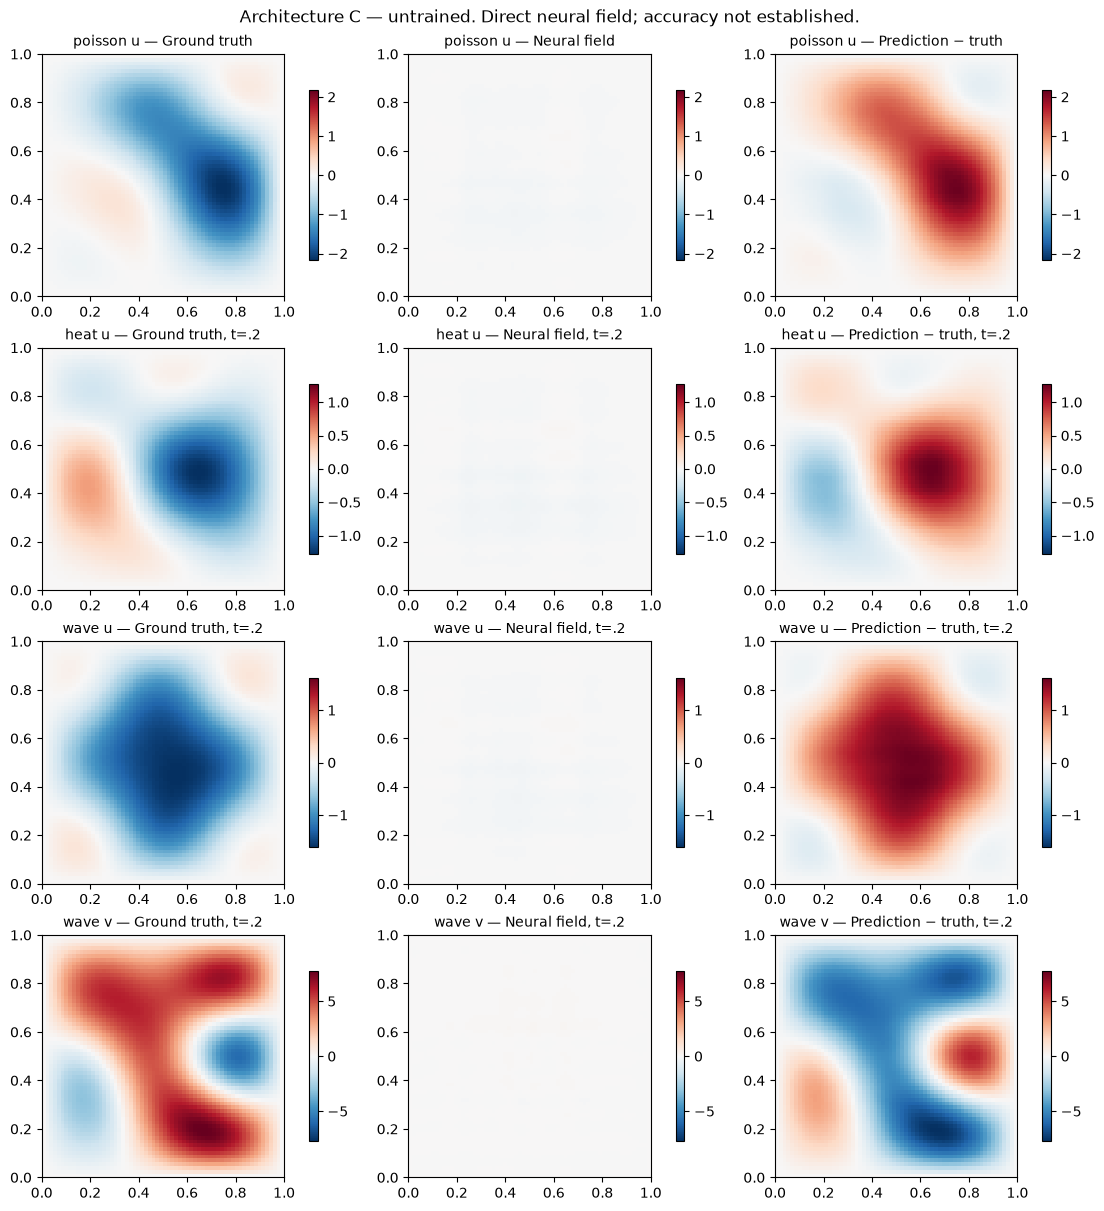

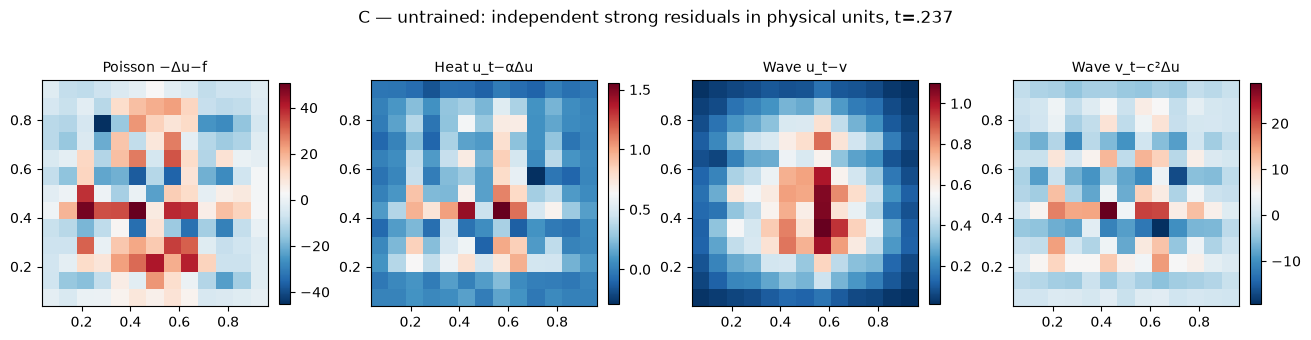

legacy-1db26b24: completed; detailed output saved to reports/notebook_legacy/13899bca08f8d78462aebbce8ba5a4d255172b2ac9d113861ba0a897187d6370/legacy-1db26b24.txt


In [20]:
with NOTEBOOK_LEDGER.cell('1db26b24',globals()):
    with legacy_output("legacy-1db26b24"):
        from pdeep.c_checks import architecture_c_checks
        from pdeep.c_plotting import field_examples as C_fields, strong_maps as C_strong_maps, constraint_summary as C_constraints
        assert_sources_current()
        C_CHECKS=architecture_c_checks(NORMALIZERS,device=CONFIG.device)
        require(C_CHECKS["passed"],"C structural/derivative checks failed")
        print(json.dumps({k:C_CHECKS[k] for k in ("shapes","checks","sensor_path_changes","physical_values","quadrature_convergence","strong_diagnostics")},indent=2))
        print("16/32 neural quadrature discrepancies are measurements, not guaranteed accuracy bounds.")
        save_C(C_fields(C,NORMALIZERS,status="untrained"),"fields_untrained.png")
        save_C(C_strong_maps(C,NORMALIZERS,status="untrained"),"strong_untrained.png")


### B forward, physical consistency and bounded path checks

Required state: inverse-gradient mathematics passes. Checks use the same three
training monitoring cases/sensors/queries for both variants. They include physical
solution consistency, padding/permutation, recurrence reset, gradient reachability,
query independence, empty data and positive bounded updates. Small ablation
forward/backward mask checks verify disabled paths; no ablation training suite.
D controls use exactly the same rounded neural-input observations, explicitly
cast to CPU64. Point estimates are not posterior samples or the exact D mean.


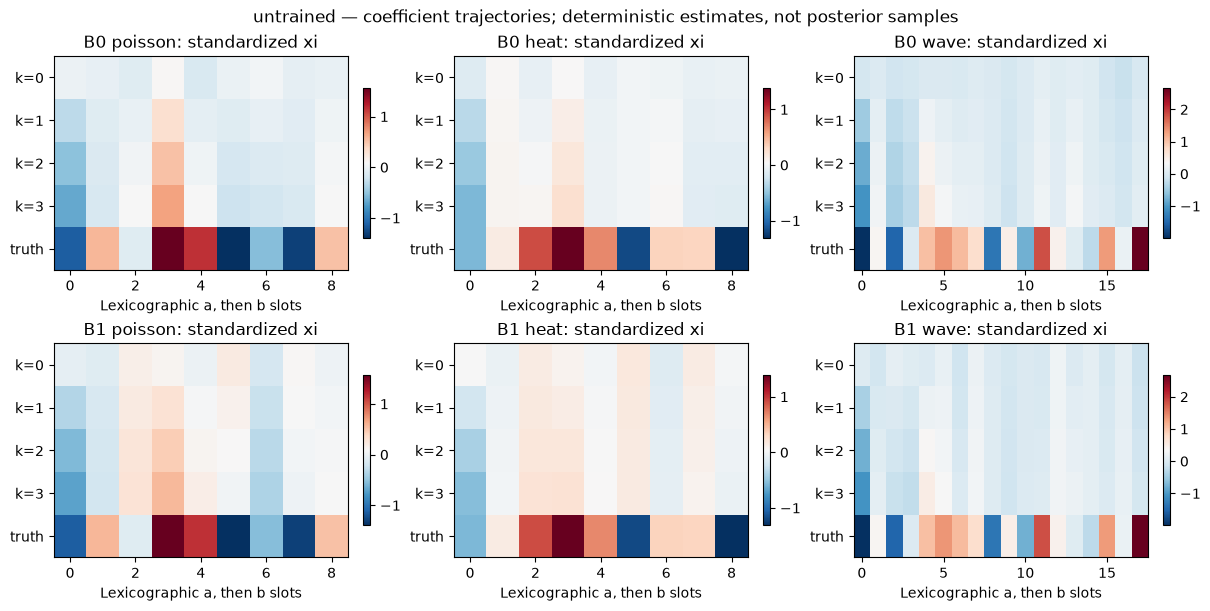

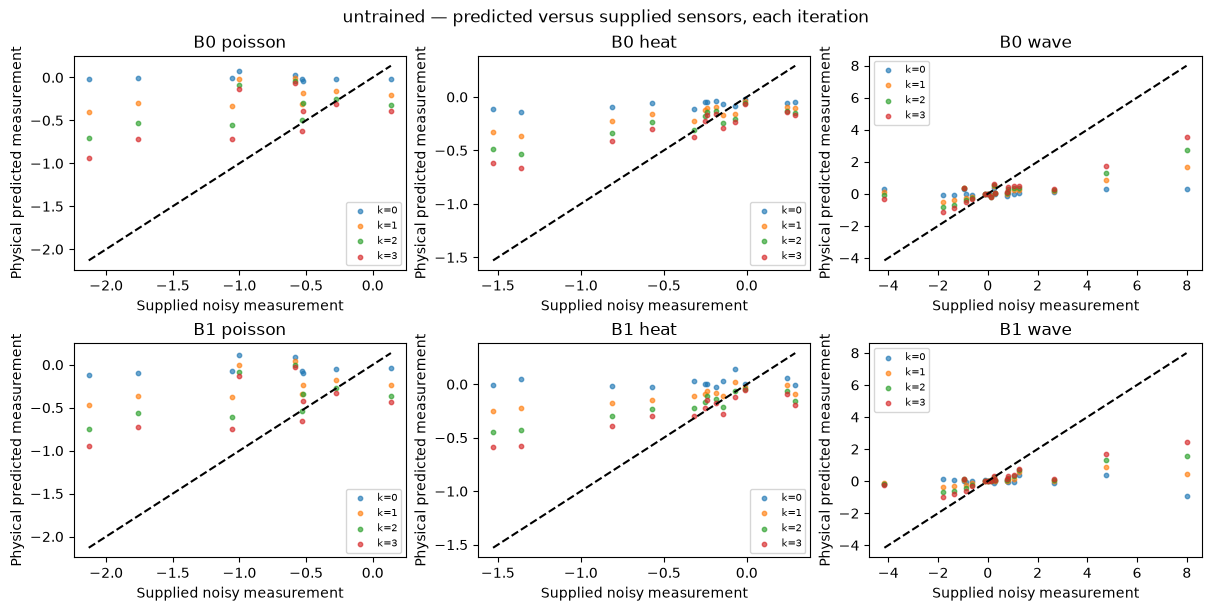

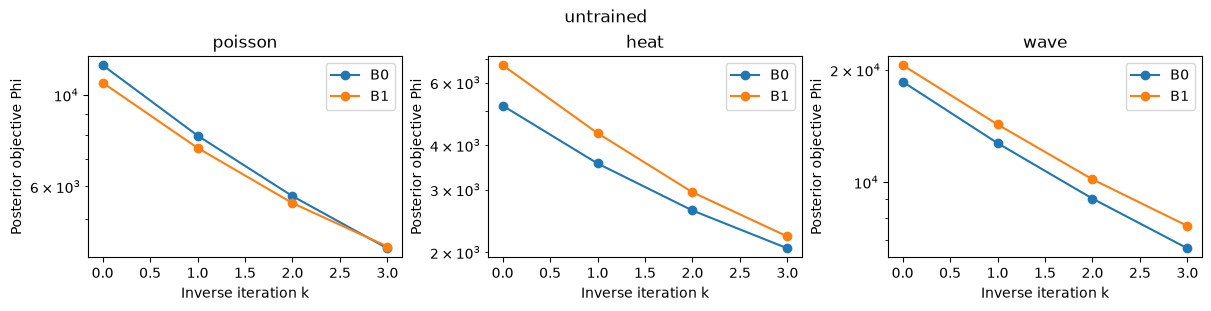

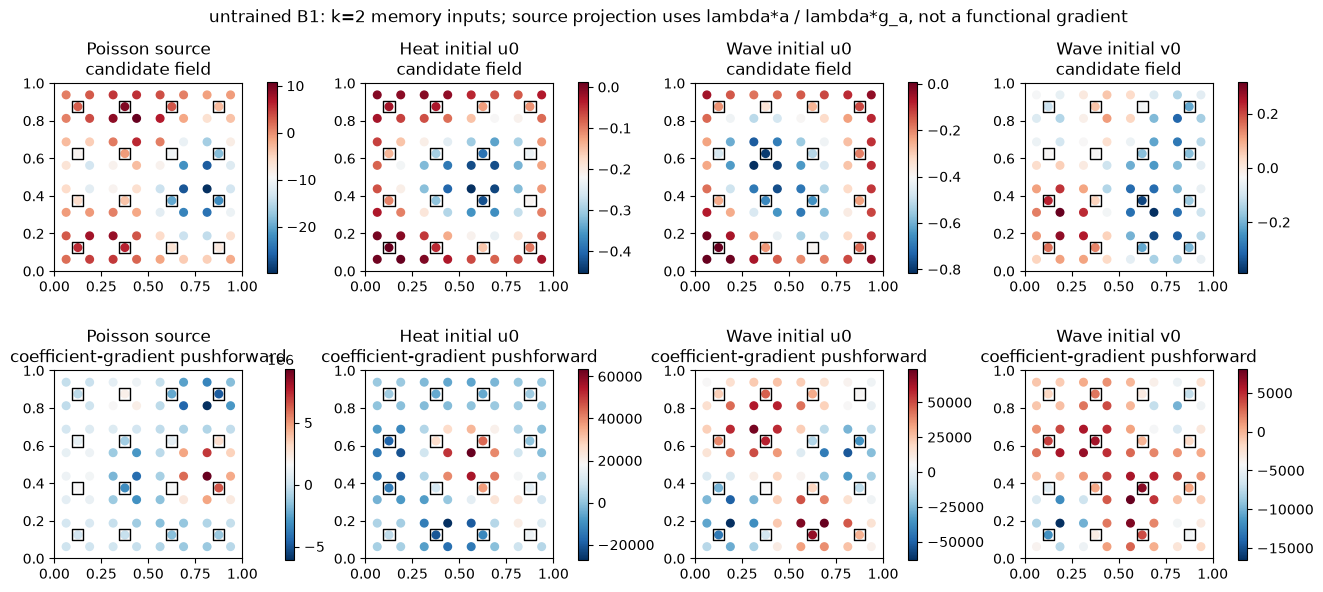

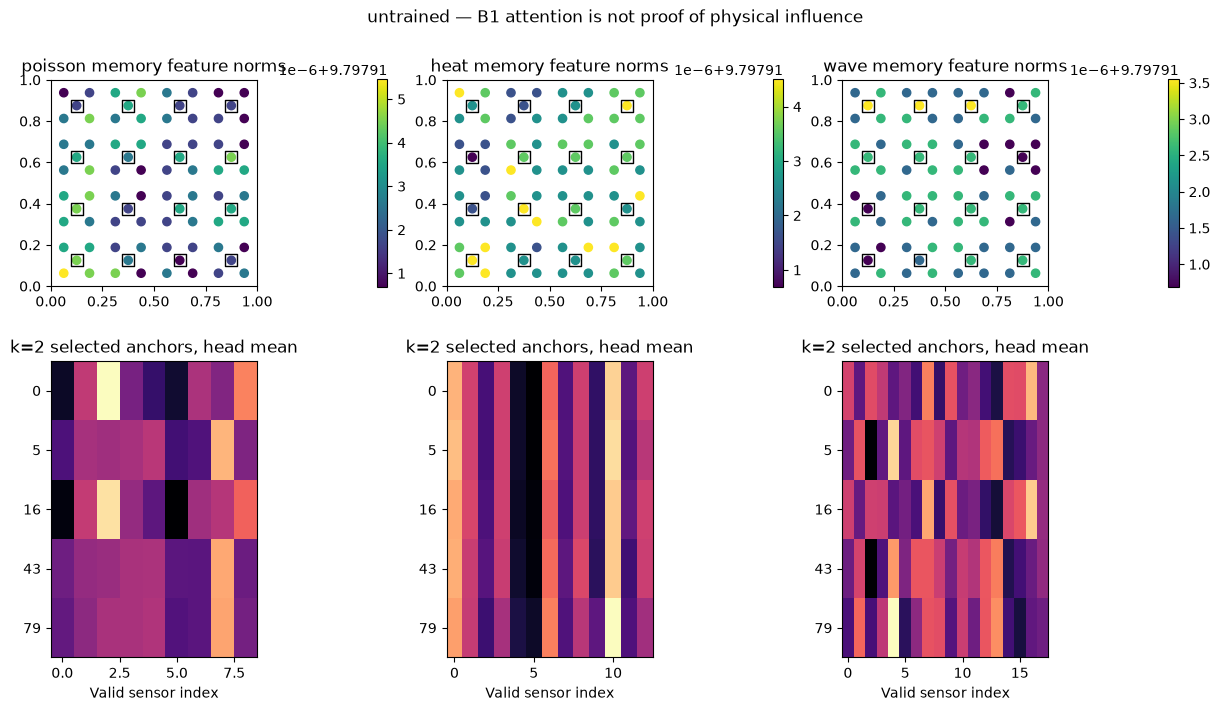

legacy-c2e34e17: completed; detailed output saved to reports/notebook_legacy/13899bca08f8d78462aebbce8ba5a4d255172b2ac9d113861ba0a897187d6370/legacy-c2e34e17.txt
Section 09 accepted | source 13899bca08f8 | active configuration identities {'CONFIG': {'owner': 'pdeep-06', 'identity': '74e91dcccf787d28570975ff97a25bed227e606de04b6dc64b4bc0319a1047ce'}, 'NORMALIZERS': {'owner': 'pdeep-15', 'identity': 'b08242e6946c4612b24523bf27dc087f2f4e38d0de758555d1775b8b0bc377a2'}, 'TRAIN_CONFIGS': {'owner': '98c696c3', 'identity': 'd7d6f9d6827a2d9cb529d61266d7e5f197954f70b06b931e1cb6cfbe9f361ae9'}}


In [21]:
with NOTEBOOK_LEDGER.cell('c2e34e17',globals()):
    with legacy_output("legacy-c2e34e17"):
        assert_sources_current()
        B_CHECKS=architecture_b_checks(NORMALIZERS,device=CONFIG.device)
        require(B_CHECKS["passed"],"B bounded verification failed")
        with torch.no_grad():
            B_RESULTS={name:model.infer_unknowns(model.prepare_context(B_BATCH.specs,B_BATCH.observations),return_diagnostics=True) for name,model in B_MODELS.items()}
        print(json.dumps({"checks":B_CHECKS["checks"],"variants":B_CHECKS["variants"],"D_controls":B_CHECKS["D_controls"],"fixed_objectives":B_CHECKS["fixed_control_objectives"]},indent=2))
        save_B(B_coefficients(B_RESULTS,B_BATCH,status="untrained"),"coefficients_untrained.png")
        save_B(B_sensors(B_RESULTS,B_BATCH,status="untrained"),"sensor_iterations_untrained.png")
        save_B(B_objectives(B_RESULTS,status="untrained"),"objectives_untrained.png")
        if "B1" in B_MODELS:
            save_B(B_spatial_fields(B_MODELS["B1"],B_RESULTS["B1"],status="untrained"),"spatial_fields_untrained.png")
            save_B(B_attention(B_MODELS["B1"],B_RESULTS["B1"],status="untrained"),"spatial_attention_untrained.png")
print("Section 09 accepted | source",SOURCE_ID[:12],"| active configuration identities",NOTEBOOK_LEDGER.snapshot()["bindings"])


## 10. A objective and gradient checks

Required state: passing A forward checks; training-only targets remain outside
PreparedContext. $E_{bq}=\operatorname{mean}_{valid,q}((\hat u-u)/s_q)^2$,
$L_{field}=\operatorname{mean}_b\operatorname{mean}_{available\ q} E_{bq}$;
$L_\xi=\operatorname{mean}_b\operatorname{mean}_{active\ j}((\hat\xi_j-\xi_j)/s_{\xi,j})^2$.
$L_A=L_{field}+0.1L_\xi$. This explicit Stage 4 quantity-balanced reduction
clarifies the canonical field objective. No PDE, spectral, likelihood or regional
penalty is added. Empty query cases contribute zero field loss.

Field loss → scalar heads/trunk → Gaussian retrieval → local/global mixing →
sensor cross-attention → observation and typed graph encoders. Xi loss reaches
its auxiliary head and context. With coefficient weight zero, field predictions
and their gradient paths remain available; the coefficient head is unused by
field-only backward. Unequal microbatches weight losses by case count/effective
batch, including the smaller final microbatch. AdamW lr=3e-4, decay=1e-4,
gradient clip=1. No mixed precision.


In [22]:
with NOTEBOOK_LEDGER.cell('8b2eb55e',globals()):
    with legacy_output("legacy-8b2eb55e"):
        from pdeep.a_training import objective, gradient_report, ATrainingConfig, run_bounded, observation_agreement
        assert_sources_current()
        A.train();A.zero_grad(set_to_none=True)
        A_OUTPUT=A(A_BATCH.specs,A_BATCH.observations,A_BATCH.queries)
        A_LOSSES=objective(A_OUTPUT,A_BATCH)
        A_LOSSES["total"].backward()
        print("Actual objective components:",{k:float(v.detach()) for k,v in A_LOSSES.items() if v.ndim==0})
        print("Per-module intended objective gradients:",json.dumps(gradient_report(A),indent=2))
        print("Independent field-only path checks:",json.dumps(A_CHECKS["field_only_gradients"],indent=2))
        print("Expected field-only disconnection: coefficient_head; no field-to-solver path exists.")
        print("Sensor agreement diagnostics:",json.dumps(observation_agreement(A,A_OUTPUT.context,A_BATCH.observations),indent=2))
        A.zero_grad(set_to_none=True);A.eval()


legacy-8b2eb55e: completed; detailed output saved to reports/notebook_legacy/13899bca08f8d78462aebbce8ba5a4d255172b2ac9d113861ba0a897187d6370/legacy-8b2eb55e.txt


### C family-specific weak and initial objectives

Use tensor Gauss-Legendre16×16 space, with interval factors and total area1.
Dynamic time is eight physical Gauss nodes with unequal weights summing to1.
Values/derivatives are evaluated once per chunk, then contracted against all nine
$\phi_j$ and $\nabla\phi_j$. Assemble full spatial integrals before squaring.

$R_{Pj}=\int(\nabla\hat u\cdot\nabla\phi_j-\hat f\phi_j)$,
$\hat f=\sum\lambda_j\hat a_j\phi_j$;
$R_{Hj}(t)=\int(\hat u_t\phi_j+\alpha\nabla\hat u\cdot\nabla\phi_j)$;
$R_{W1j}=\int(\hat u_t-\hat v)\phi_j$,
$R_{W2j}=\int(\hat v_t\phi_j+c^2\nabla\hat u\cdot\nabla\phi_j)$.
Scales are respectively $\lambda_j\tau_j$, $\alpha\lambda_j\tau_j$,
$\omega_j\tau_j$ and $\omega_j^2\tau_j$, fixed by training prior/known physics.
Use mean squared normalized modes and weighted temporal integration; wave averages
its two equations. Known alpha/c are read from ProblemSpec.

Initial t=0 consistency is separately integrated in space, comparing the neural
field against inferred modal u0/v0, without detaching xi. Exact training-prior
initial RMS is $s_{u0}^2=\sum(\mu_{a,j}^2+\tau_j^2)$ and similarly for b.
It is distinct from dynamic quantity RMS. Heat matches u; wave averages u/v;
Poisson has no physical time or initial objective.

$L_C=L_{field}+.1L_\xi+.1L_{weak}+.1L_{initial}$ with equal available-quantity
weight per case and equal case weight. Physical/normalized diagnostics and each
weighted term are separate. Weak/initial weights0,.1,1 are configurable ablations.
No strong, region, spectral, energy or likelihood penalty is added. Observation
Gaussian likelihood is a valid-sensor case-level sum, diagnostic only.


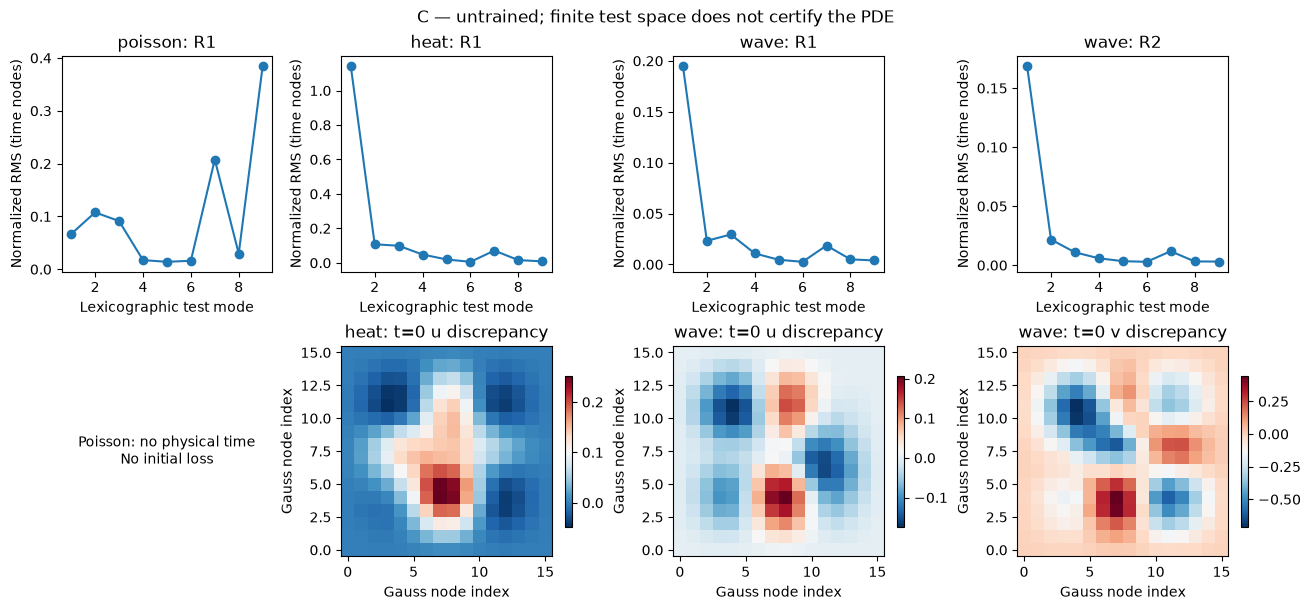

legacy-5c130ba0: completed; detailed output saved to reports/notebook_legacy/13899bca08f8d78462aebbce8ba5a4d255172b2ac9d113861ba0a897187d6370/legacy-5c130ba0.txt


In [23]:
with NOTEBOOK_LEDGER.cell('5c130ba0',globals()):
    with legacy_output("legacy-5c130ba0"):
        from pdeep.c_training import objective as C_objective, sensor_diagnostics as C_sensor_diagnostics
        from pdeep.constraints import physical_losses,prior_initial_scales
        assert_sources_current()
        C.train();C.zero_grad(set_to_none=True)
        C_OUT=C(C_BATCH.specs,C_BATCH.observations,C_BATCH.queries)
        C_LOSSES=C_objective(C,C_OUT,C_BATCH)
        C_LOSSES["total"].backward()
        print("Normalized and weighted loss terms:",{k:float(v.detach()) for k,v in C_LOSSES.items() if isinstance(v,torch.Tensor)})
        print("Physical-term reports:",json.dumps(C_CHECKS["physical_values"],indent=2))
        print("Five objective gradient tests:",json.dumps(C_CHECKS["gradient_paths"],indent=2))
        print("Expected: field-only does not train xi head; coefficient-only does not train coordinate field.")
        print("Supplied-sensor diagnostics:",json.dumps(C_sensor_diagnostics(C,C_OUT.context,C_BATCH.observations),indent=2))
        print("Training-prior initial RMS:",{s.name:prior_initial_scales(s) for s in SPECS if s.name!="poisson"})
        C.zero_grad(set_to_none=True);C.eval()
        save_C(C_constraints(C,NORMALIZERS,status="untrained"),"constraints_untrained.png")


### B objective, stability and optional diagnostic ablations

$\Phi(\xi)=\frac12\|R^{-1/2}(H\xi-y)\|^2+
\frac12\|S^{-1}(\xi-m_0)\|^2$,
$g=H^TR^{-1}(H\xi-y)+S^{-2}(\xi-m_0)$.
Learned $D=S^2d$, $.25<d<1.75$, and
$\eta=f/(1.75L)$, $.05<f<.95$, with
$L=\lambda_{max}(I+(R^{-1/2}HS)^T R^{-1/2}HS)$.
This explicit curvature bound stabilizes the quadratic update; positivity alone
would not guarantee descent. We still record each physical Phi and residual.

Training loss is ONLY final active standardized coefficient MSE, averaged equally
per case. Initial error, Phi, field/sensor error and preconditioner statistics are
diagnostics. No B1-specific extra penalty. Gradients pass through all three
physical-gradient/update steps to initializer, token refiner and B1 spatial path.

B1 projects Poisson source as sum lambda*a*phi and displays gradient pushforward
sum lambda*g_a*phi. This is not the source-amplitude covector g_a/lambda or an
arbitrary functional gradient. Heat/wave project inferred initial a/b separately.
Large raw gradient features use asinh; the actual physical gradient is unchanged.


In [24]:
with NOTEBOOK_LEDGER.cell('5bd38782',globals()):
    with legacy_output("legacy-5bd38782"):
        from pdeep.b_training import coefficient_loss
        assert_sources_current()
        for name,model in B_MODELS.items():
            model.zero_grad(set_to_none=True)
            result=model.infer_unknowns(model.prepare_context(B_BATCH.specs,B_BATCH.observations),return_diagnostics=True)
            loss=coefficient_loss(result,B_BATCH.unknowns);loss.backward()
            print(name,"coefficient-only loss",float(loss.detach()),"gradients",json.dumps(gradient_report(model),indent=2))
            print("Per-iteration physical objective:",result.objectives.detach().tolist())
            print("Step size min/max:",float(result.steps.detach().min()),float(result.steps.detach().max()))
            active_D=result.diagonal.masked_select(result.xi_active[:,None].expand_as(result.diagonal))
            print("Physical diagonal min/max:",float(active_D.detach().min()),float(active_D.detach().max()))
            model.zero_grad(set_to_none=True)
        B_RUN_OPTIONAL_ABLATIONS=False
        if B_RUN_OPTIONAL_ABLATIONS and "B1" in B_MODELS:
            model=B_MODELS["B1"]
            for label,flags in (("no_spatial",BAblation(spatial=False)),("no_spatial_attention",BAblation(spatial_attention=False)),("no_physical_projections",BAblation(physical_projections=False))):
                result=model.infer_unknowns(model.prepare_context(B_BATCH.specs,B_BATCH.observations),ablation=flags)
                print(label,estimate_summary(model,result,B_BATCH))
            print("B1 no-spatial is pathway-comparable to B0, not identical weights/parameters.")
        else:
            print("Optional scientific ablation comparisons disabled; only bounded mask/path checks above ran.")
print("Section 10 accepted | source",SOURCE_ID[:12],"| active configuration identities",NOTEBOOK_LEDGER.snapshot()["bindings"])


legacy-5bd38782: completed; detailed output saved to reports/notebook_legacy/13899bca08f8d78462aebbce8ba5a4d255172b2ac9d113861ba0a897187d6370/legacy-5bd38782.txt
Section 10 accepted | source 13899bca08f8 | active configuration identities {'CONFIG': {'owner': 'pdeep-06', 'identity': '74e91dcccf787d28570975ff97a25bed227e606de04b6dc64b4bc0319a1047ce'}, 'NORMALIZERS': {'owner': 'pdeep-15', 'identity': 'b08242e6946c4612b24523bf27dc087f2f4e38d0de758555d1775b8b0bc377a2'}, 'TRAIN_CONFIGS': {'owner': '98c696c3', 'identity': 'd7d6f9d6827a2d9cb529d61266d7e5f197954f70b06b931e1cb6cfbe9f361ae9'}}


### Shared loss/update, validation and failure semantics

Adapters call the verified objective functions unchanged: A=field+.1xi;
C=field+.1xi+.1weak+.1initial (initial absent for Poisson); B0/B1=final active
standardized coefficient MSE. Phi remains a refinement diagnostic. No raw-loss
comparison ranks these different objectives.

For a microbatch of b cases in an E-case window, backward uses(b/E)*L. The final
smaller microbatch is weighted by cases, clipping occurs once, then AdamW and the
successful-update scheduler advance. Attempted/skipped/failed are separate. A
nonfinite component/gradient, OOM or unsupported operation writes a reproducible
failure bundle and stops; no batch/quadrature reduction or partial device fallback.

Validation uses a named immutable validation manifest, same case/O/query IDs at
every check, quantity-separated field/xi/sensor metrics and architecture-specific
diagnostics. C explicitly enables coordinate autograd without optimizer backward;
all module modes restore in finally. Tests verify validation preserves parameters,
optimizer state, existing gradients, training RNG and sampler ordering.


## 11. Optional tiny fixed-case overfit

Required state: passing A objective/gradients. **Disabled by default.** Explicitly
set TINY_OVERFIT=True to use the same complete A and objective on 16 fixed
training cases for at most 100 updates. No test data; no smaller substitute model.
A fixed-query error and sensitivity are reported before/after. Decrease is
measured, never assumed. This is a diagnostic, not comparative research evidence.


In [25]:
with NOTEBOOK_LEDGER.cell('430c939e',globals()):
    with legacy_output("legacy-430c939e"):
        TINY_OVERFIT = False
        TINY_UPDATES = 50
        if TINY_OVERFIT:
            from pdeep.a_training import make_training_batch
            FIXED_A=make_training_batch(DATASET,NORMALIZERS,0,count=16,device=CONFIG.device,fixed=True)
            with torch.no_grad():
                BEFORE_TINY=float(objective(A(FIXED_A.specs,FIXED_A.observations,FIXED_A.queries),FIXED_A)["field"])
            TINY_CONFIG=ATrainingConfig(preset="tiny_overfit",tiny_overfit=True,updates=TINY_UPDATES)
            TINY_REPORT,A_OPTIMIZER=run_bounded(A,DATASET,NORMALIZERS,TINY_CONFIG)
            with torch.no_grad():
                AFTER_TINY=float(objective(A(FIXED_A.specs,FIXED_A.observations,FIXED_A.queries),FIXED_A)["field"])
                from dataclasses import replace
                original=A(FIXED_A.specs,FIXED_A.observations,FIXED_A.queries).predicted_value
                changed=A(FIXED_A.specs,replace(FIXED_A.observations,value=FIXED_A.observations.value+.5),FIXED_A.queries).predicted_value
            print({"fixed_query_field_before":BEFORE_TINY,"after":AFTER_TINY,"error_ratio":AFTER_TINY/BEFORE_TINY,
                   "sensor_value_prediction_change":float((original-changed).abs().max())})
            from pdeep.a_plotting import fixed_query_comparison
            save_A(fixed_query_comparison(A,FIXED_A,status="tiny-overfit diagnostic"),"tiny_fixed_queries.png")
            save_A(training_curve(TINY_REPORT),"tiny_overfit_curve.png")
            save_A(field_examples(A,NORMALIZERS,status="tiny-overfit diagnostic"),"fields_tiny_overfit.png")
        else:
            print("Tiny overfit disabled; no updates here.")


legacy-430c939e: completed; detailed output saved to reports/notebook_legacy/13899bca08f8d78462aebbce8ba5a4d255172b2ac9d113861ba0a897187d6370/legacy-430c939e.txt


### Optional C tiny fixed-case overfit — disabled

Explicit opt-in only. Same model, objective, full16×16×8 quadrature, three fixed
training cases and microbatch1. Logs field/xi/weak/initial terms and gradients;
reports fixed-query errors, sensor agreement and independent strong diagnostics.
A smaller weak loss alone does not establish reconstruction. No test split.


In [26]:
with NOTEBOOK_LEDGER.cell('48e0662e',globals()):
    with legacy_output("legacy-48e0662e"):
        C_TINY_OVERFIT=False
        C_TINY_UPDATES=50
        if C_TINY_OVERFIT:
            from pdeep.c_training import CTrainingConfig,make_training_batch as C_training_batch,run_bounded as C_run
            from pdeep.constraints import strong_diagnostics
            from pdeep.c_checks import independent_diagnostic_queries,serializable_strong
            C_FIXED=C_training_batch(DATASET,NORMALIZERS,0,device=CONFIG.device,fixed=True)
            with torch.no_grad():
                C_BEFORE=float(objective(C(C_FIXED.specs,C_FIXED.observations,C_FIXED.queries),C_FIXED)["field"])
            C_TINY_CONFIG=CTrainingConfig(preset="tiny_overfit",tiny_overfit=True,updates=C_TINY_UPDATES)
            C_TINY_REPORT,C_OPTIMIZER=C_run(C,DATASET,NORMALIZERS,C_TINY_CONFIG)
            with torch.no_grad():
                C_AFTER=float(objective(C(C_FIXED.specs,C_FIXED.observations,C_FIXED.queries),C_FIXED)["field"])
            C_FIXED_CONTEXT=C.prepare_context(C_FIXED.specs,C_FIXED.observations)
            print({"fixed_query_field_before":C_BEFORE,"after":C_AFTER,"ratio":C_AFTER/C_BEFORE})
            print("Sensor agreement:",C_sensor_diagnostics(C,C_FIXED_CONTEXT,C_FIXED.observations))
            print("Independent strong residuals:",serializable_strong(strong_diagnostics(C,C_FIXED_CONTEXT,independent_diagnostic_queries(C_FIXED))))
            from pdeep.c_plotting import training_curve as C_curve
            from pdeep.c_plotting import fixed_query_comparison as C_fixed_scatter
            save_C(C_fixed_scatter(C,C_FIXED,status="C tiny-overfit fixed queries"),"tiny_fixed_queries.png")
            save_C(C_curve(C_TINY_REPORT),"tiny_overfit_losses.png")
            save_C(C_fields(C,NORMALIZERS,status="tiny-overfit diagnostic"),"tiny_fields.png")
        else:
            print("C tiny overfit disabled; no updates here.")


legacy-48e0662e: completed; detailed output saved to reports/notebook_legacy/13899bca08f8d78462aebbce8ba5a4d255172b2ac9d113861ba0a897187d6370/legacy-48e0662e.txt


### B optional tiny fixed-dataset overfit — off

Select variants explicitly, use three fixed TRAIN cases and the same coefficient
loss, full three-step mechanisms, physical operators and optimizer protocol.
At most100 updates when enabled. Compare coefficient/field/sensor error and Phi;
lower Phi alone does not establish accurate reconstruction. No test data.


In [27]:
with NOTEBOOK_LEDGER.cell('9e890fc3',globals()):
    with legacy_output("legacy-9e890fc3"):
        B_TINY_OVERFIT=False
        B_TINY_UPDATES=50
        if B_TINY_OVERFIT:
            from pdeep.b_training import BTrainingConfig,run_bounded as B_run
            B_TINY_REPORTS={};B_OPTIMIZERS={}
            for name,model in B_MODELS.items():
                cfg=BTrainingConfig(approach=name,root_seed=CONFIG.root_seed,preset="tiny_overfit",tiny_overfit=True,updates=B_TINY_UPDATES)
                B_TINY_REPORTS[name],B_OPTIMIZERS[name]=B_run(model,DATASET,NORMALIZERS,cfg)
            save_B(B_training_curves(B_TINY_REPORTS),"tiny_overfit_histories.png")
            save_B(B_fields(B_MODELS,NORMALIZERS,status="tiny-overfit diagnostic"),"tiny_fields.png")
        else:
            print("B0/B1 tiny overfit disabled; no optimizer updates here.")
print("Section 11 accepted | source",SOURCE_ID[:12],"| active configuration identities",NOTEBOOK_LEDGER.snapshot()["bindings"])


legacy-9e890fc3: completed; detailed output saved to reports/notebook_legacy/13899bca08f8d78462aebbce8ba5a4d255172b2ac9d113861ba0a897187d6370/legacy-9e890fc3.txt
Section 11 accepted | source 13899bca08f8 | active configuration identities {'CONFIG': {'owner': 'pdeep-06', 'identity': '74e91dcccf787d28570975ff97a25bed227e606de04b6dc64b4bc0319a1047ce'}, 'NORMALIZERS': {'owner': 'pdeep-15', 'identity': 'b08242e6946c4612b24523bf27dc087f2f4e38d0de758555d1775b8b0bc377a2'}, 'TRAIN_CONFIGS': {'owner': '98c696c3', 'identity': 'd7d6f9d6827a2d9cb529d61266d7e5f197954f70b06b931e1cb6cfbe9f361ae9'}}


## 12. Bounded A preflight and inference export

Required state: checks above. In Stage 5, RUN_A_SMOKE=False reloads the prior A inference export; the new C preflight below is the automatic three-update run. Historical Stage 4 budget: exactly **three successful
optimizer updates**, microbatch=8, accumulation=2, 16 physical cases/update,
uniform PDE-family sampling. The actual family counts are logged. Training-only
queries retain the reference risk distribution. Constant lr is used for smoke;
research warmup/cosine scheduling is not implemented. Counters, objectives,
rolling loss, module gradients, clipping, timings, process peak RSS and available
device allocation are reported. CPU RSS includes libraries/calibration. MPS API
exposes current allocation rather than an isolated peak.

Plots are labeled smoke-tested: three updates establish execution only. An
immutable inference export saves weights, graph vocabulary, training normalizers,
source/config/dataset identities and checksums. Reload predictions are checked.
It is explicitly **not a resumable optimizer checkpoint**. Stop after this stage.


In [28]:
with NOTEBOOK_LEDGER.cell('b89772a8',globals()):
    with legacy_output("legacy-b89772a8"):
        # Stage 5 preserves A. Its historical three-update preflight is opt-in here.
        RUN_A_SMOKE = False
        if RUN_A_SMOKE or TINY_OVERFIT:
            from dataclasses import asdict
            from pdeep.a_artifacts import save_inference,load_inference
            assert_sources_current()
            require(CONFIG.identity == A_CONFIG_ID,"stale A configuration")
            if not TINY_OVERFIT:
                A_TRAIN_CONFIG=ATrainingConfig(updates=3)
                A_TRAIN_REPORT,A_OPTIMIZER=run_bounded(A,DATASET,NORMALIZERS,A_TRAIN_CONFIG)
            else:
                A_TRAIN_CONFIG=TINY_CONFIG
                A_TRAIN_REPORT=TINY_REPORT
            A_STATUS=A_TRAIN_REPORT["status"]
            save_A(training_curve(A_TRAIN_REPORT),"training_curve.png")
            save_A(field_examples(A,NORMALIZERS,status=A_STATUS),"fields_smoke.png")
            save_A(memory_summary(A,NORMALIZERS,status=A_STATUS),"memory_smoke.png")
            A_EXPORT=save_inference(A,ROOT/"artifacts/A_inference",source=SOURCE_ID,config=asdict(A_TRAIN_CONFIG),status=A_STATUS,dataset_id=DATASET.identity)
            A_RELOADED,A_EXPORT_META=load_inference(A_EXPORT,device=CONFIG.device)
            with torch.no_grad():
                A_RELOAD_ERROR=float((A(A_BATCH.specs,A_BATCH.observations,A_BATCH.queries).predicted_value-
                                      A_RELOADED(A_BATCH.specs,A_BATCH.observations,A_BATCH.queries).predicted_value).abs().max())
            require(A_RELOAD_ERROR<=2e-5,"inference reload mismatch")
            A_REPORT={"run_id":A_RUN_ID,"source_sha256":SOURCE_ID,"config_sha256":CONFIG_ID,"config":asdict(A_TRAIN_CONFIG),
                      "normalizer_id":NORMALIZERS.identity,"dataset_id":DATASET.identity,"checks":A_CHECKS,
                      "training":A_TRAIN_REPORT,"reload_max_abs_error":A_RELOAD_ERROR,"plots":A_PLOTS,
                      "inference_manifest":str(A_EXPORT.relative_to(ROOT))}
            (A_RUN_DIR/"verification.json").write_text(json.dumps(A_REPORT,indent=2,allow_nan=False)+"\n")
            (ROOT/"reports/latest_architecture_A.json").write_text(json.dumps({"run_id":A_RUN_ID,"directory":str(A_RUN_DIR.relative_to(ROOT)),"report":str((A_RUN_DIR/"verification.json").relative_to(ROOT))},indent=2)+"\n")
            print(json.dumps({"status":A_STATUS,"counters":A_TRAIN_REPORT["counters"],"updates":A_TRAIN_REPORT["updates"],
                              "memory":A_TRAIN_REPORT["memory"],"device":A_TRAIN_REPORT["device"],"precision":"float32",
                              "prediction_statistics":A_TRAIN_REPORT["prediction_statistics"],"reload_error":A_RELOAD_ERROR},indent=2))
            print("STOP: Stage 4 complete. No B, flow matching, posterior sampling or large training.")
            print("Diagnostic bundle:",A_RUN_DIR)
        
        else:
            from pdeep.a_artifacts import load_inference as load_A_inference
            A_PRIOR_RECORDS=[json.loads(path.read_text()) for path in (ROOT/"reports/architecture_A").glob("*/verification.json")]
            A_PRIOR_RECORD=next((record for record in A_PRIOR_RECORDS if record.get("training") and record.get("inference_manifest")),None)
            require(A_PRIOR_RECORD is not None,"A smoke export missing; explicitly enable RUN_A_SMOKE to recreate Stage 4")
            A,A_PRIOR_METADATA=load_A_inference(ROOT/A_PRIOR_RECORD["inference_manifest"],device=CONFIG.device)
            print("A preserved: prior verified smoke export reloaded; no A optimizer updates in Stage 5.")


legacy-b89772a8: completed; detailed output saved to reports/notebook_legacy/13899bca08f8d78462aebbce8ba5a4d255172b2ac9d113861ba0a897187d6370/legacy-b89772a8.txt


### C historical bounded preflight — opt-in in Stage6

Stage6 default RUN_C_SMOKE=False reloads the previous verified C export. Required state: C1–C10 and all five objective gradient paths pass. Explicit smoke
configuration: microbatch1, effective batch3, accumulation3, one case/family per
update from uniform stratified sampling. This smaller case budget is for bounded
preflight; network, losses and quadrature are unchanged. AdamW lr3e-4, decay1e-4,
clip1, float32, no AMP. All eight physical time nodes are used for every dynamic
case; no temporal subsampling. Research scheduling/resume remain unimplemented.
The inference export saves training normalizers, initial RMS, vocabulary, rule
orders and checksummed state. It is not an optimizer-resume checkpoint.


In [29]:
with NOTEBOOK_LEDGER.cell('2b44d25f',globals()):
    with legacy_output("legacy-2b44d25f"):
        # Stage6 preserves C; its previous optimizer preflight is opt-in here.
        RUN_C_SMOKE=False
        if RUN_C_SMOKE or C_TINY_OVERFIT:
            from pdeep.c_training import CTrainingConfig,run_bounded as C_run
            from pdeep.c_plotting import training_curve as C_curve
            from pdeep.c_artifacts import save_inference as save_C_inference,load_inference as load_C_inference
            assert_sources_current()
            if not C_TINY_OVERFIT:
                C_TRAIN_CONFIG=CTrainingConfig(updates=3,microbatch=1,effective_batch=3)
                C_TRAIN_REPORT,C_OPTIMIZER=C_run(C,DATASET,NORMALIZERS,C_TRAIN_CONFIG)
            else:
                C_TRAIN_CONFIG=C_TINY_CONFIG;C_TRAIN_REPORT=C_TINY_REPORT
            C_STATUS=C_TRAIN_REPORT["status"]
            save_C(C_curve(C_TRAIN_REPORT),"training_curve.png")
            save_C(C_fields(C,NORMALIZERS,status=C_STATUS),"fields_smoke.png")
            save_C(C_strong_maps(C,NORMALIZERS,status=C_STATUS),"strong_smoke.png")
            save_C(C_constraints(C,NORMALIZERS,status=C_STATUS),"constraints_smoke.png")
            C_EXPORT=save_C_inference(C,ROOT/"artifacts/C_inference",source=SOURCE_ID,config=asdict(C_TRAIN_CONFIG),status=C_STATUS,dataset_id=DATASET.identity)
            C_RELOADED,C_META=load_C_inference(C_EXPORT,device=CONFIG.device)
            with torch.no_grad():
                C_RELOAD_ERROR=float((C(C_BATCH.specs,C_BATCH.observations,C_BATCH.queries).predicted_value-C_RELOADED(C_BATCH.specs,C_BATCH.observations,C_BATCH.queries).predicted_value).abs().max())
            require(C_RELOAD_ERROR<=3e-5,"C inference reload mismatch")
            C_SMOKE_CONTEXT=C.prepare_context(C_BATCH.specs,C_BATCH.observations)
            from pdeep.c_checks import independent_diagnostic_queries,serializable_strong
            from pdeep.constraints import strong_diagnostics
            C_STRONG_SMOKE=serializable_strong(strong_diagnostics(C,C_SMOKE_CONTEXT,independent_diagnostic_queries(C_BATCH)))
            C_REPORT={"run_id":C_RUN_ID,"source_sha256":SOURCE_ID,"config_sha256":CONFIG_ID,"mathematics":C_MATH,"checks":C_CHECKS,
                      "training":C_TRAIN_REPORT,"config":asdict(C_TRAIN_CONFIG),"normalizer_id":NORMALIZERS.identity,"dataset_id":DATASET.identity,
                      "strong_smoke":C_STRONG_SMOKE,"sensor_diagnostics":C_sensor_diagnostics(C,C_SMOKE_CONTEXT,C_BATCH.observations),
                      "reload_max_abs_error":C_RELOAD_ERROR,"inference_manifest":str(C_EXPORT.relative_to(ROOT)),"plots":C_PLOTS}
            (C_RUN_DIR/"verification.json").write_text(json.dumps(C_REPORT,indent=2,allow_nan=False)+"\n")
            (ROOT/"reports/latest_architecture_C.json").write_text(json.dumps({"run_id":C_RUN_ID,"directory":str(C_RUN_DIR.relative_to(ROOT)),"report":str((C_RUN_DIR/"verification.json").relative_to(ROOT))},indent=2)+"\n")
            print(json.dumps({"status":C_STATUS,"training":C_TRAIN_REPORT,"reload_error":C_RELOAD_ERROR,"strong":C_STRONG_SMOKE},indent=2))
            print("STOP: Stage 5 complete; no B, flow matching, T2 or large training.")
            print("C diagnostic bundle:",C_RUN_DIR)
        
        else:
            from pdeep.c_artifacts import load_inference as load_prior_C
            C_PRIOR_RECORDS=[json.loads(path.read_text()) for path in (ROOT/"reports/architecture_C").glob("*/verification.json")]
            C_PRIOR_RECORD=next((r for r in C_PRIOR_RECORDS if r.get("training") and r.get("inference_manifest")),None)
            require(C_PRIOR_RECORD is not None,"C smoke export missing; explicitly enable RUN_C_SMOKE to recreate Stage5")
            C,C_PRIOR_META=load_prior_C(ROOT/C_PRIOR_RECORD["inference_manifest"],device=CONFIG.device)
            print("C preserved: previous verified smoke export reloaded; no C optimizer updates in Stage6.")


legacy-2b44d25f: completed; detailed output saved to reports/notebook_legacy/13899bca08f8d78462aebbce8ba5a4d255172b2ac9d113861ba0a897187d6370/legacy-2b44d25f.txt


### B0/B1 matched bounded preflight and COMPLETE checkpoints

Exactly three updates per selected variant; explicit microbatch1/effective3,
accumulation3, one training case/family/update. Identical sampler keys, sensor sets,
queries, loss, lr3e-4, weight decay1e-4 and clip1. No AMP/research schedule.
Different initialization and B1's additional parameters/cost are intentional.
Later research comparisons need BOTH successful-update and wall-clock matching.

Each variant gets its own complete optimizer-boundary checkpoint containing every
encoder/refiner/spatial component, Adam moments, constant schedule, counters,
stateless sampler root/next step, CPU RNG snapshot, normalizers/priors/vocabulary
and source/config IDs. Incompatible variants fail. Per-case recurrence is reset,
not persisted across independent samples. This resumes the implemented bounded
protocol; distributed/AMP/research scheduling is unsupported.


In [30]:
with NOTEBOOK_LEDGER.cell('db89beec',globals()):
    with legacy_output("legacy-db89beec"):
        # Historical Stage6 training is separate; Stage7A budget belongs to shared engine.
        RUN_LEGACY_B_SMOKE=False
        if RUN_LEGACY_B_SMOKE or B_TINY_OVERFIT:
            from pdeep.b_training import BTrainingConfig,run_bounded as B_run
            from pdeep.b_artifacts import save_checkpoint as save_B_checkpoint,load_checkpoint as load_B_checkpoint,tree_identity,tree_cpu
            assert_sources_current()
            B_TRAIN_REPORTS={};B_CHECKPOINTS={};B_CONFIGS={};B_OPTIMIZERS=globals().get("B_OPTIMIZERS",{})
            for name,model in B_MODELS.items():
                cfg=BTrainingConfig(approach=name,root_seed=CONFIG.root_seed,updates=3)
                if B_TINY_OVERFIT:
                    cfg=BTrainingConfig(approach=name,root_seed=CONFIG.root_seed,preset="tiny_overfit",tiny_overfit=True,updates=B_TINY_UPDATES)
                    B_TRAIN_REPORTS[name]=B_TINY_REPORTS[name]
                else:
                    B_TRAIN_REPORTS[name],B_OPTIMIZERS[name]=B_run(model,DATASET,NORMALIZERS,cfg)
                B_CONFIGS[name]=asdict(cfg)
                path=save_B_checkpoint(model,B_OPTIMIZERS[name],cfg,ROOT/"artifacts/B_checkpoints",source=SOURCE_ID,dataset_id=DATASET.identity,
                                       next_step=B_TRAIN_REPORTS[name]["next_step"],counters=B_TRAIN_REPORTS[name]["counters"])
                restored,optimizer_restored,_,sampler,_=load_B_checkpoint(path,expected_approach=name,device=CONFIG.device)
                with torch.no_grad():
                    original=model.infer_unknowns(model.prepare_context(B_BATCH.specs,B_BATCH.observations))
                    reloaded=restored.infer_unknowns(restored.prepare_context(B_BATCH.specs,B_BATCH.observations))
                reload_error=float((original.xi_hat-reloaded.xi_hat).abs().max())
                require(reload_error<=1e-12,"B checkpoint inference mismatch")
                require(tree_identity(tree_cpu(B_OPTIMIZERS[name].state_dict()))==tree_identity(tree_cpu(optimizer_restored.state_dict())),"B Adam-state reload mismatch")
                B_CHECKPOINTS[name]={"manifest":str(path.relative_to(ROOT)),"reload_max_abs_error":reload_error,"next_step":sampler["next_step"],"optimizer_state_identical":True}
            if len(B_TRAIN_REPORTS)==2:
                require([l["case_ids"] for l in B_TRAIN_REPORTS["B0"]["updates"]]==[l["case_ids"] for l in B_TRAIN_REPORTS["B1"]["updates"]],"B0/B1 training cases differ")
            with torch.no_grad():
                B_RESULTS={name:model.infer_unknowns(model.prepare_context(B_BATCH.specs,B_BATCH.observations),return_diagnostics=True) for name,model in B_MODELS.items()}
            B_SUMMARY={name:estimate_summary(B_MODELS[name],result,B_BATCH) for name,result in B_RESULTS.items()}
            save_B(B_training_curves(B_TRAIN_REPORTS),"training_histories.png")
            save_B(B_coefficients(B_RESULTS,B_BATCH,status="smoke-tested"),"coefficients_smoke.png")
            save_B(B_sensors(B_RESULTS,B_BATCH,status="smoke-tested"),"sensors_smoke.png")
            save_B(B_objectives(B_RESULTS,status="smoke-tested"),"objectives_smoke.png")
            save_B(B_fields(B_MODELS,NORMALIZERS,status="smoke-tested"),"fields_smoke.png")
            if "B1" in B_MODELS:
                save_B(B_spatial_fields(B_MODELS["B1"],B_RESULTS["B1"],status="smoke-tested"),"spatial_fields_smoke.png")
                save_B(B_attention(B_MODELS["B1"],B_RESULTS["B1"],status="smoke-tested"),"spatial_attention_smoke.png")
            B_REPORT={"run_id":B_RUN_ID,"source_sha256":SOURCE_ID,"config_sha256":CONFIG_ID,"configs":B_CONFIGS,
                      "dataset_id":DATASET.identity,"normalizer_id":NORMALIZERS.identity,"mathematics":B_MATH,"checks":B_CHECKS,
                      "training":B_TRAIN_REPORTS,"checkpoints":B_CHECKPOINTS,"summary":B_SUMMARY,"plots":B_PLOTS}
            (B_RUN_DIR/"verification.json").write_text(json.dumps(B_REPORT,indent=2,allow_nan=False)+"\n")
            (ROOT/"reports/latest_architecture_B.json").write_text(json.dumps({"run_id":B_RUN_ID,"directory":str(B_RUN_DIR.relative_to(ROOT)),"report":str((B_RUN_DIR/"verification.json").relative_to(ROOT))},indent=2)+"\n")
            print("Compact side-by-side B0/B1 diagnostics:",json.dumps(B_SUMMARY,indent=2))
            print("Training/memory/gradient evidence:",json.dumps(B_TRAIN_REPORTS,indent=2))
            print("Complete checkpoint reloads:",json.dumps(B_CHECKPOINTS,indent=2))
            print("STOP: no substantial training, flow matching, T2 or additional PDE families.")
        
        else:
            print("Legacy B0/B1 optimizer preflights disabled; shared engine runs below.")


legacy-db89beec: completed; detailed output saved to reports/notebook_legacy/13899bca08f8d78462aebbce8ba5a4d255172b2ac9d113861ba0a897187d6370/legacy-db89beec.txt


### Stage7A shared preflight — reload during Stage7B

`RUN_SHARED_TRAINING_PREFLIGHT=False` is saved. Run All reloads immutable existing checkpoints without training. The original three-update preflight remains available behind an explicit opt-in; its objectives are unchanged.

In [31]:
with NOTEBOOK_LEDGER.cell('f0e5f0e4',globals()):
    RUN_SHARED_TRAINING_PREFLIGHT=False  # Stage 7B never launches training by default.
    if RUN_SHARED_TRAINING_PREFLIGHT:
        assert_sources_current()
        from pdeep.train_validation import validate_D
        from pdeep.train_checkpoint import load_checkpoint as load_engine_checkpoint
        from pdeep.b_artifacts import tree_identity,tree_cpu
        ENGINE_MONITOR=LiveMonitor(notebook=True,suite_budgets={k:v.updates for k,v in TRAIN_CONFIGS.items()})
        ENGINES={};ENGINE_RECORDS={}
        for name,cfg in TRAIN_CONFIGS.items():
            engine=TrainingEngine(cfg,NORMALIZERS,ROOT/"artifacts/training_runs",monitor=ENGINE_MONITOR)
            steps=engine.run()
            require(engine.state.successful==3 and engine.state.failed==engine.state.skipped==0,"shared preflight did not complete3 successful updates")
            restored=load_engine_checkpoint(engine.state.last_checkpoint,expected_architecture=name,probe=False)
            require(tree_identity(tree_cpu(engine.model.state_dict()))==tree_identity(tree_cpu(restored.model.state_dict())),"model checkpoint reload mismatch")
            require(tree_identity(tree_cpu(engine.optimizer.state_dict()))==tree_identity(tree_cpu(restored.optimizer.state_dict())),"optimizer reload mismatch")
            require(engine.scheduler.state_dict()==restored.scheduler.state_dict() and engine.state.sampler_cursor==restored.state.sampler_cursor,"scheduler/sampler reload mismatch")
            ENGINES[name]=engine
            ENGINE_RECORDS[name]={"config":asdict(cfg),"state":asdict(engine.state),"steps":[asdict(s) for s in steps],
                                   "capability":engine.capability,"validation":asdict(engine.latest_validation),"checkpoint":engine.state.last_checkpoint,
                                   "checkpoint_reload_identical":True,"monitor":engine.monitor.latest}
        manifest=next(iter(ENGINES.values())).manifest
        require(all(e.manifest.identity==manifest.identity for e in ENGINES.values()),"validation manifests differ across selected variants")
        D_ENGINE_VALIDATION=validate_D(manifest,NORMALIZERS)
        ENGINE_RECORDS["D_evaluation_only"]=asdict(D_ENGINE_VALIDATION)
        ENGINE_BUNDLE=ROOT/"reports/training_engine"/RUN_LABEL
        ENGINE_BUNDLE.mkdir(parents=True,exist_ok=True)
        (ENGINE_BUNDLE/"verification.json").write_text(json.dumps({"source_sha256":SOURCE_ID,"selection":list(TRAIN_APPROACHES),"records":ENGINE_RECORDS},indent=2,allow_nan=False)+"\n")
        (ROOT/"reports/latest_training_engine.json").write_text(json.dumps({"directory":str(ENGINE_BUNDLE.relative_to(ROOT)),"report":str((ENGINE_BUNDLE/"verification.json").relative_to(ROOT))},indent=2)+"\n")
        display(Markdown("| Variant | Successful / attempted | Cases / queries | Update-loop seconds | Fixed validation normalized field MSE | Checkpoint reload |\n|---|---|---|---|---|---|\n"+
            "\n".join(f"| {name} | {e.state.successful}/{e.state.attempted} | {e.state.cases_processed}/{e.state.queries_processed} | {sum(sum(s['timings'].values()) for s in e.state.recent_steps):.3f} | {e.latest_validation.metrics['common']['field_normalized_MSE']:.5g} | identical |" for name,e in ENGINES.items())))
        print("Raw losses are architecture-specific; use common fixed-validation reconstruction metrics for comparison.")
        print("No expensive training. Tiny overfit and legacy optimizer preflights remained disabled.")
        print("Copyable diagnostic bundle:",ENGINE_BUNDLE)
    else:
        from pdeep.train_checkpoint import load_checkpoint as load_engine_checkpoint
        pointer=json.loads((ROOT/"reports/latest_training_engine.json").read_text())
        saved=json.loads((ROOT/pointer["report"]).read_text())
        ENGINE_RECORDS=saved["records"]; ENGINES={}
        for name in TRAIN_APPROACHES:
            ENGINES[name]=load_engine_checkpoint(ENGINE_RECORDS[name]["checkpoint"],expected_architecture=name,probe=False)
        ENGINE_BUNDLE=ROOT/pointer["directory"]
        ENGINE_MONITOR=LiveMonitor(notebook=True)
        print("Reloaded existing Stage7A smoke checkpoints; zero new optimizer updates.")
        display(Markdown("| Architecture | Status | Successful updates | Training cases |\n|---|---|---:|---:|\n"+
            "\n".join(f"| {name} | {e.config.preset} | {e.state.successful} | {e.state.cases_processed} |" for name,e in ENGINES.items())))
print("Section 12 accepted | source",SOURCE_ID[:12],"| active configuration identities",NOTEBOOK_LEDGER.snapshot()["bindings"])


Reloaded existing Stage7A smoke checkpoints; zero new optimizer updates.


| Architecture | Status | Successful updates | Training cases |
|---|---|---:|---:|
| A | smoke | 3 | 9 |
| C | smoke | 3 | 9 |
| B0 | smoke | 3 | 9 |
| B1 | smoke | 3 | 9 |

Section 12 accepted | source 13899bca08f8 | active configuration identities {'CONFIG': {'owner': 'pdeep-06', 'identity': '74e91dcccf787d28570975ff97a25bed227e606de04b6dc64b4bc0319a1047ce'}, 'NORMALIZERS': {'owner': 'pdeep-15', 'identity': 'b08242e6946c4612b24523bf27dc087f2f4e38d0de758555d1775b8b0bc377a2'}, 'TRAIN_CONFIGS': {'owner': '98c696c3', 'identity': 'd7d6f9d6827a2d9cb529d61266d7e5f197954f70b06b931e1cb6cfbe9f361ae9'}}


## 13. Explicitly enabled full research training

Required state: passing forward/gradient/preflight checks and a reviewed resolved
configuration. Saved defaults below are FALSE. Both controls must be deliberately
set; there is no blocking input()/confirmation prompt. Research AdamW uses250
warmup successful updates then cosine to0.1 initial LR,10000 successful updates,
fixed held-out validation and checkpoint every250. Default batches target16
physical cases (A/B0/B1 micro8×2; C micro1×16). Do not increase them automatically.

**Stage7A did not run research training.** This is infrastructure, not Stage7B
extensive evaluation. D is evaluation-only and cannot enter the neural trainer.


In [32]:
with NOTEBOOK_LEDGER.cell('a9b48fef',globals()):
    # Two deliberate controls, saved FALSE. Suite preview always precedes launch.
    FULL_TRAINING_ENABLED=False
    LAUNCH_FULL_TRAINING=False
    FULL_TRAIN_APPROACHES=("A",)
    FULL_TRAIN_ACTION="fresh"  # Explicitly choose fresh OR resume; never inferred.
    FULL_RESUME_CHECKPOINTS={}  # Required per architecture for resume.
    from pdeep.experiment_suite import SuiteEntry,preview_suite,execute_suite
    from pdeep.artifact_drive import PersistencePolicy
    FULL_PERSISTENCE=PersistencePolicy()  # Local authoritative; Drive disabled.
    FULL_ENTRIES=[]
    for name in FULL_TRAIN_APPROACHES:
        require(name in {"A","C","B0","B1"},"full training selects exact neural identities; D uses inference suites")
        if FULL_TRAIN_ACTION=="fresh":
            research=ResolvedTrainConfig(name,preset="research",device=CONFIG.device,root_seed=CONFIG.root_seed,source_id=SOURCE_ID,
                run_tag=RUN_LABEL+"-research",full_training_enabled=FULL_TRAINING_ENABLED)
            FULL_ENTRIES.append(SuiteEntry(name,"fresh",str(ROOT/"artifacts/training_runs"),config=research,persistence=FULL_PERSISTENCE))
        else:
            require(FULL_TRAIN_ACTION=="resume" and name in FULL_RESUME_CHECKPOINTS,"resume requires explicit compatible checkpoint paths")
            FULL_ENTRIES.append(SuiteEntry(name,"resume",str(ROOT/"artifacts/training_runs"),checkpoint=FULL_RESUME_CHECKPOINTS[name],persistence=FULL_PERSISTENCE))
    FULL_PREVIEW=preview_suite(tuple(FULL_ENTRIES))
    display(Markdown("```json\n"+json.dumps(FULL_PREVIEW,indent=2)+"\n```"))
    FULL_RUNS={}
    def _start_reviewed_archival_training():
        global FULL_RUNS
        FULL_RUNS=execute_suite(tuple(FULL_ENTRIES),NORMALIZERS,execute_training=True,launch_full=True,expected_preview_identity=FULL_PREVIEW["identity"])
    if FULL_TRAINING_ENABLED and LAUNCH_FULL_TRAINING:
        from pdeep.notebook_launch import offer_launch
        ARCHIVAL_LAUNCH=offer_launch(_start_reviewed_archival_training,description="Start reviewed archival training")
    else:
        print("Full research training disabled. Explicit suite fresh/resume choices and both launch guards are required.")
print("Section 13 accepted | source",SOURCE_ID[:12],"| active configuration identities",NOTEBOOK_LEDGER.snapshot()["bindings"])


```json
{
  "version": "explicit-suite-v2",
  "execution_order": [
    "A"
  ],
  "entries": [
    {
      "order": 0,
      "architecture": "A",
      "action": "fresh",
      "requires_training": true,
      "resolved_config": {
        "architecture": "A",
        "preset": "research",
        "pdes": [
          "poisson",
          "heat",
          "wave"
        ],
        "probabilities": [
          0.3333333333333333,
          0.3333333333333333,
          0.3333333333333333
        ],
        "benchmark": "unit_square_modal_v1",
        "inverse_track": "T1",
        "capacity": "canonical_v1",
        "device": "cpu",
        "precision": "float32",
        "microbatch": 8,
        "accumulation": 2,
        "effective_batch": 16,
        "query_count": 128,
        "training_case_ids": null,
        "learning_rate": 0.0003,
        "weight_decay": 0.0001,
        "grad_clip_norm": 1.0,
        "scheduler": "warmup_then_cosine",
        "warmup_updates": 250,
        "minimum_lr_fraction": 0.1,
        "updates": 10000,
        "validation_every": 250,
        "checkpoint_every": 250,
        "validation_cases_per_pde": 128,
        "validation_query_count": 128,
        "validation_name": "validation-v1",
        "root_seed": 20261108,
        "verbosity": "normal",
        "rolling_window": 50,
        "source_id": "13899bca08f8d78462aebbce8ba5a4d255172b2ac9d113861ba0a897187d6370",
        "run_tag": "stage7A-c9cc54ef1a-research",
        "full_training_enabled": false,
        "overwrite_checkpoint": false
      },
      "config_identity": "9e42259fada15ac9d6e402d9abc2a8935721a091b54a07271ee3b441cd256472",
      "training_budget": 10000,
      "completed_successful_updates": 0,
      "origin_declared_training_budget": 10000,
      "remaining_successful_updates": 10000,
      "validation_budget": {
        "cases_per_PDE": 128,
        "queries_per_case": 128,
        "cadence": 250
      },
      "microbatch": 8,
      "accumulation": 2,
      "effective_batch": 16,
      "device": "cpu",
      "precision": "float32; explicit CPU64 B physics",
      "checkpoint_dependency": null,
      "compatible_artifact_id": null,
      "normalizer_identity": null,
      "existing_compatible_checkpoint": null,
      "outputs": {
        "run_directory": "/Users/nicolasackermann/Documents/ChatGPT/PDEep/artifacts/training_runs/A/A-9e42259fada15ac9d6e402d9",
        "checkpoints": "/Users/nicolasackermann/Documents/ChatGPT/PDEep/artifacts/training_runs/A/A-9e42259fada15ac9d6e402d9/checkpoints",
        "inference": "/Users/nicolasackermann/Documents/ChatGPT/PDEep/artifacts/training_runs/A/A-9e42259fada15ac9d6e402d9/inference"
      },
      "Drive_enabled": false,
      "persistence_policy": {
        "drive_enabled": false,
        "drive_mount": null,
        "drive_explicitly_mounted": false,
        "backend": "colab_drive",
        "retention": "keep_all",
        "keep_last": 5
      }
    }
  ],
  "identity": "c6d1067d3f0cd7cfbe3d68747dcfc0c30f286e6f4dd8fa212557d18c6902dfbf",
  "policy": "no auto retrain; exact architecture + explicit fresh/resume choice; full training requires both guards"
}
```

Full research training disabled. Explicit suite fresh/resume choices and both launch guards are required.
Section 13 accepted | source 13899bca08f8 | active configuration identities {'CONFIG': {'owner': 'pdeep-06', 'identity': '74e91dcccf787d28570975ff97a25bed227e606de04b6dc64b4bc0319a1047ce'}, 'NORMALIZERS': {'owner': 'pdeep-15', 'identity': 'b08242e6946c4612b24523bf27dc087f2f4e38d0de758555d1775b8b0bc377a2'}, 'TRAIN_CONFIGS': {'owner': '98c696c3', 'identity': 'd7d6f9d6827a2d9cb529d61266d7e5f197954f70b06b931e1cb6cfbe9f361ae9'}}


## 14. Matched evaluation and comparison

A frozen versioned plan fixes the physical cases, independently keyed conditioning/held-out observations, 64×64 grid, continuous reference times, quantity identities, training RMS, source and configuration. Poisson has no physical time; wave u/v remain separate. Every method receives the same raw records (explicit float32 neural copy; CPU64 physical references).

For valid field error $e=\hat u-u$, report $\mathrm{MSE}=\langle e^2\rangle$, $\mathrm{RMSE}=\sqrt{\mathrm{MSE}}$, $\mathrm{MAE}=\langle|e|\rangle$ and $\langle(e/s_q)^2\rangle$. Reduce points → equal quantities/case → equal cases/PDE → equal PDE macro. Hidden field/coefficients are scoring-only. D point estimates are posterior means; latent variance excludes measurement noise and future noisy variance adds $\sigma^2$.

Independent interior strong AD residuals, initial/boundary diagnostics and C's separate weak residuals accompany field metrics. B trajectories include every $\xi_k$, $\Phi_k$, sensor residual and update norm; disabled B1 paths use fresh contexts. D uncertainty includes 50/90/95% intervals, correlated held-out predictive scores and coherent sample chunks. Neural posterior uncertainty is unavailable.

This default run evaluates one fixed validation case per PDE with existing **three-update smoke checkpoints** and controls; no new optimization. It is descriptive. Case-cluster coverage intervals are conservative; paired case-bootstrap confidence intervals cannot be estimated with one case/PDE. Later protocols support matched successful updates or matched walltime and ≥3 seeds; they do not launch training.

In [33]:
with NOTEBOOK_LEDGER.cell('bd11965a',globals()):
    from pdeep.evaluation_plan import make_plan,EvaluationPlan
    from pdeep.evaluation import EvaluationConfig,evaluate as evaluate_matched
    from pdeep.evaluation_inference import available_methods
    from pdeep.evaluation_diagnostics import ComparisonProtocol
    from pdeep.evaluation_plotting import comparison_table,create_plots,write_report
    assert_sources_current()
    EVAL_CONFIG=EvaluationConfig(chunk=1024)
    EVAL_METHODS,EVAL_NORMALIZERS=available_methods(ROOT,device=CONFIG.device)
    require(EVAL_NORMALIZERS.identity==NORMALIZERS.identity,"normalizers changed")
    EVAL_PLAN=make_plan(EVAL_NORMALIZERS,source_id=SOURCE_ID,config_id=EVAL_CONFIG.identity,case_ids=(0,))
    EVAL_PLAN_PATH=EVAL_PLAN.save(ROOT/"reports/matched_evaluation"/EVAL_PLAN.identity)
    require(EvaluationPlan.load(EVAL_PLAN_PATH)==EVAL_PLAN,"evaluation plan reload mismatch")
    LATER_UPDATE_PROTOCOL=ComparisonProtocol().validate(serious=True)
    LATER_TIME_PROTOCOL=ComparisonProtocol(protocol="matched_wall_clock",successful_updates=None,wall_clock_seconds=3600).validate(serious=True)
    print("Plan",EVAL_PLAN.identity,"| split",EVAL_PLAN.split,"| cases",[c.physical_id for c in EVAL_PLAN.cases])
    print("Grid 64x64; dynamic times",EVAL_PLAN.dynamic_times,"| stationary physical time absent")
    print("Protocols configured only; no training, no test evaluation.")


Plan 9aeb3a779a071091341dcf8552cc841fb84f3762519bbad3fd1f2a0ab3cc5050 | split validation | cases ['poisson/12000', 'heat/12000', 'wave/12000']
Grid 64x64; dynamic times (0.0, 0.02, 0.05, 0.1, 0.2, 0.35, 0.5, 0.75, 1.0) | stationary physical time absent
Protocols configured only; no training, no test evaluation.


In [34]:
with NOTEBOOK_LEDGER.cell('67643dbb',globals()):
    assert_sources_current()
    MATCHED_RESULT=evaluate_matched(EVAL_PLAN,EVAL_METHODS,EVAL_NORMALIZERS,config=EVAL_CONFIG,output=ROOT/"reports/matched_evaluation")
    display(Markdown(comparison_table(MATCHED_RESULT)))
    print("Wave u/v and each PDE remain separate in JSON. Tiny smoke results do not establish architecture superiority.")
    print("Inference receives known specs and measured inputs only; hidden truth used only for scoring.")


| Method | Status | Updates | Macro standardized MSE | Median full inference, ms |
|---|---|---:|---:|---:|
| A | smoke | 3 | 0.500073 | 253.246 |
| C | smoke | 3 | 0.505393 | 126.339 |
| B0 | smoke | 3 | 0.316693 | 43.799 |
| B1 | smoke | 3 | 0.33625 | 55.504 |
| D | exact; no training | 0 | 0.000352154 | 29.533 |
| B1-no-spatial | smoke | 3 | 0.343853 | 42.654 |
| B1-no-attention | smoke | 3 | 0.33715 | 46.751 |
| Fixed | exact; no training | 0 | 0.244627 | 28.999 |
| Prior | exact; no training | 0 | 0.495251 | 27.676 |

Wave u/v and each PDE remain separate in JSON. Tiny smoke results do not establish architecture superiority.
Inference receives known specs and measured inputs only; hidden truth used only for scoring.


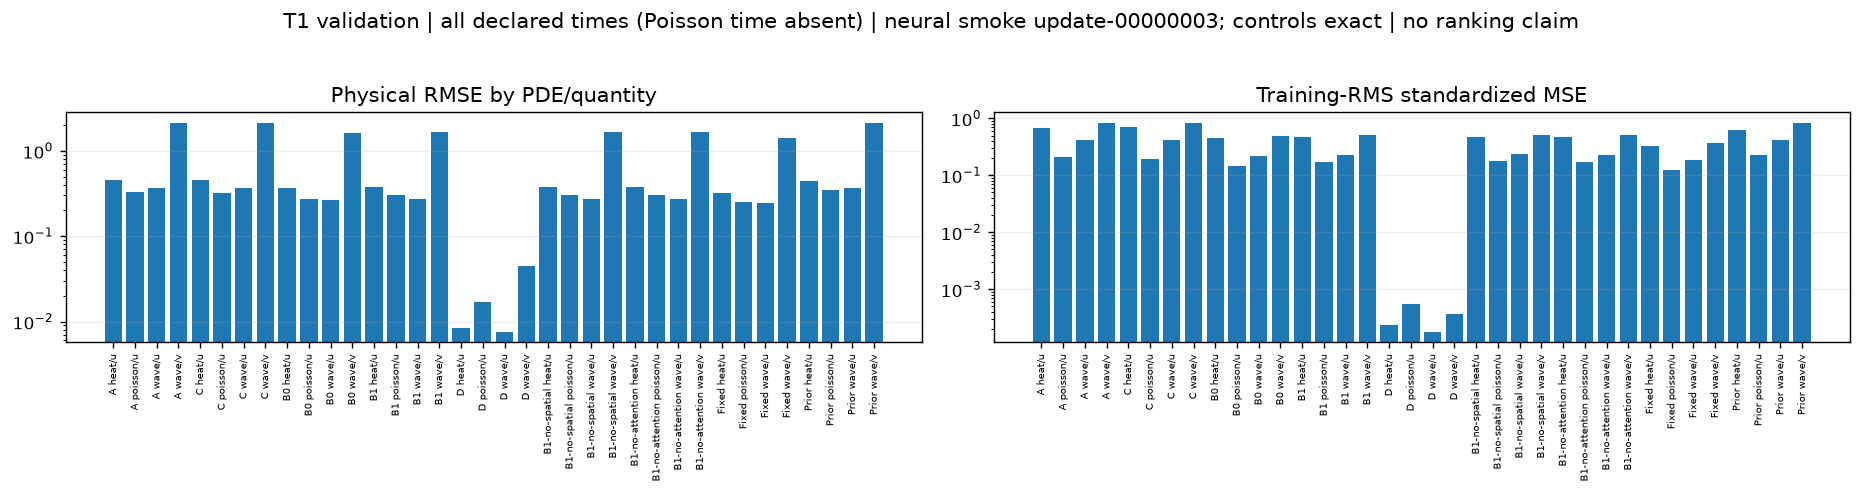

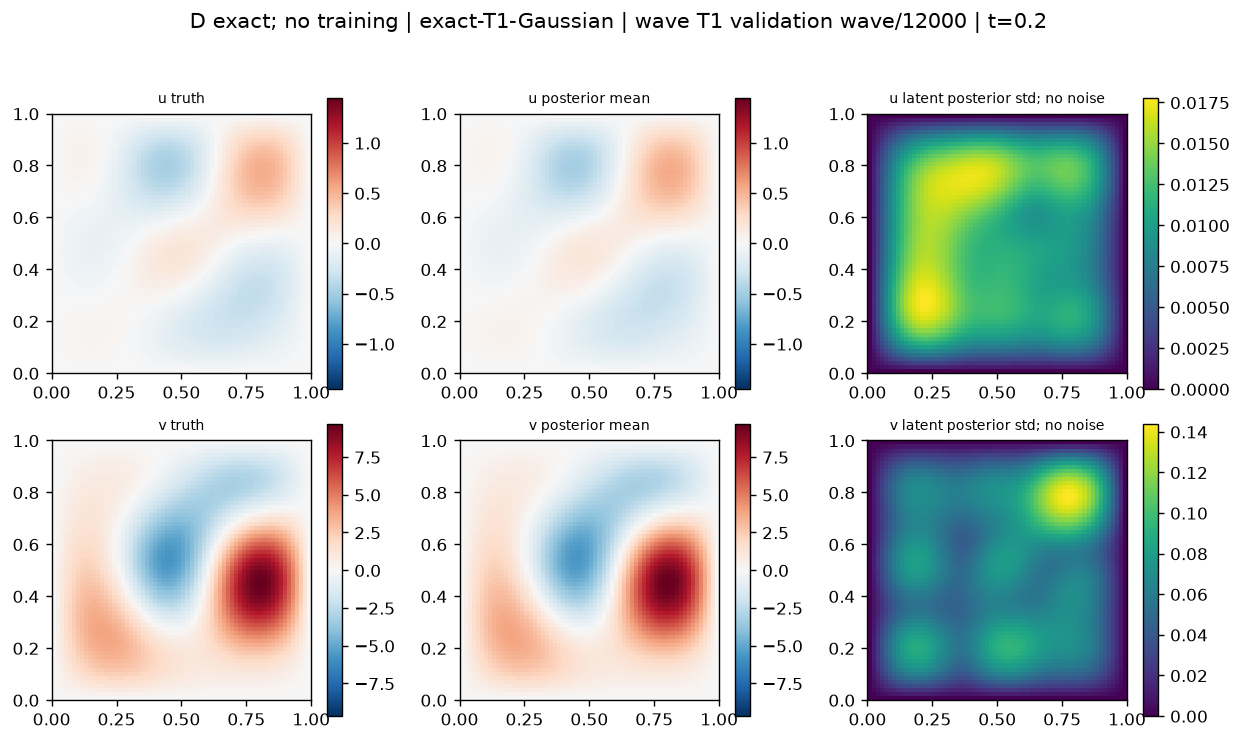

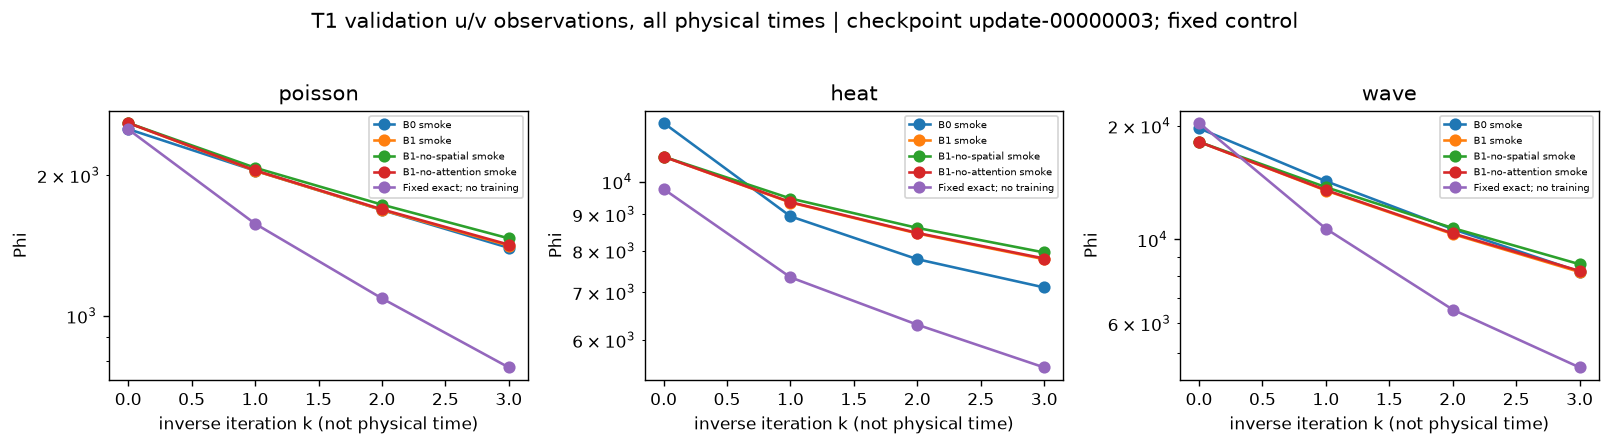

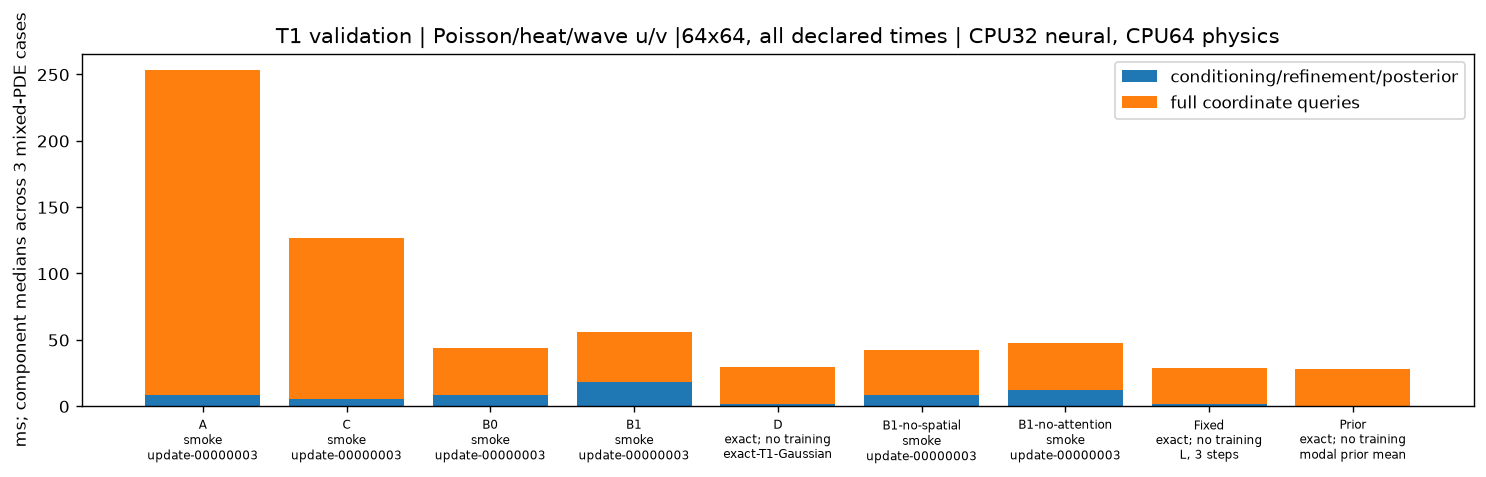

Copyable diagnostic: /Users/nicolasackermann/Documents/ChatGPT/PDEep/reports/matched_evaluation/9aeb3a779a071091341dcf8552cc841fb84f3762519bbad3fd1f2a0ab3cc5050/diagnostic.md
Scientific identity b778d89ed1ac142a5044ef65a0f229b12635a281dec21ea884221d29e2084ee8 | all weights unchanged | new optimizer updates=0 | STOP before Stage7C.
Section 14 accepted | source 13899bca08f8 | active configuration identities {'CONFIG': {'owner': 'pdeep-06', 'identity': '74e91dcccf787d28570975ff97a25bed227e606de04b6dc64b4bc0319a1047ce'}, 'NORMALIZERS': {'owner': 'pdeep-15', 'identity': 'b08242e6946c4612b24523bf27dc087f2f4e38d0de758555d1775b8b0bc377a2'}, 'TRAIN_CONFIGS': {'owner': '98c696c3', 'identity': 'd7d6f9d6827a2d9cb529d61266d7e5f197954f70b06b931e1cb6cfbe9f361ae9'}, 'EVAL_CONFIG': {'owner': 'bd11965a', 'identity': 'e00416a1366932bd63ef42eb28284277c72ac90628cd37bb27b80d66373b2d69'}, 'EVAL_PLAN': {'owner': 'bd11965a', 'identity': '9aeb3a779a071091341dcf8552cc841fb84f3762519bbad3fd1f2a0ab3cc5050'}}


In [35]:
with NOTEBOOK_LEDGER.cell('d34a0139',globals()):
    MATCHED_PLOTS=create_plots(MATCHED_RESULT,EVAL_PLAN)
    MATCHED_REPORT=write_report(MATCHED_RESULT,EVAL_PLAN,MATCHED_PLOTS)
    (ROOT/"reports/latest_evaluation.json").write_text(json.dumps({"directory":str(Path(MATCHED_RESULT["directory"]).relative_to(ROOT)),"report":str(MATCHED_REPORT.relative_to(ROOT)),"plan_identity":EVAL_PLAN.identity,"scientific_identity":MATCHED_RESULT["identity"]},indent=2)+"\n")
    from IPython.display import Image
    for name in ("quantity_errors.png","D_uncertainty_wave.png","refinement.png","cost.png"):
        display(Image(filename=str(Path(MATCHED_RESULT["directory"])/name),width=1000))
    print("Copyable diagnostic:",MATCHED_REPORT)
    print("Scientific identity",MATCHED_RESULT["identity"],"| all weights unchanged | new optimizer updates=0 | STOP before Stage7C.")
print("Section 14 accepted | source",SOURCE_ID[:12],"| active configuration identities",NOTEBOOK_LEDGER.snapshot()["bindings"])


## 15. Artifact save, independent reload and reproducible resume

Required state: completed sections01–14 with the current source/configuration/normalization identities. The visible cell ledger rejects stale configuration and out-of-order execution; rerunning a cell invalidates its downstream stamps. Every section emits a compact acceptance/configuration summary.

Three noninterchangeable artifact kinds use readable `pdeep-artifact-v2` manifests: complete optimizer-boundary training checkpoints, standalone inference exports and diagnostic bundles. Manifests contain source/scientific/runtime identity, every component/geometry/normalizer/prior/solver dependency, split/observation policies, histories and checksums. Payloads are temporary-written, fsynced, reopened and verified before publication; `last` and common-metric `best_validation` pointers refer only to verified commits. Existing experiments are never overwritten/deleted.

The explicit CLI verification uses the actual objectives and full quadrature: each neural architecture has8 uninterrupted updates versus4 updates + process exit + fresh-process reload +4 updates, with a two-update E2E checkpoint/export/diagnostic demonstration reused inside that same interrupted run. It compares weights, Adam moments, scheduler/LR, data/observation identities, RNG continuation markers, predictions and losses. Inference exports for all five architectures reload in separate processes without importing training modules. D recomputes its exact posterior.

**Safe rerun:** `RUN_PERSISTENCE_PREFLIGHT=False` reloads compatible verified evidence. It never retrains existing models. If source/configuration changed, explicitly rerun `.venv/bin/python scripts/check_persistence.py --fresh` (bounded64 real updates total) or opt into that preflight here. Full research training remains disabled. No test cases are used. Drive is optional and disabled; filesystem mock transaction tests do not claim real Drive testing. CPU resume equality does not imply cross-hardware bitwise equality.

In [ ]:
with NOTEBOOK_LEDGER.cell('625a3343',globals()):
    RUN_PERSISTENCE_PREFLIGHT=False
    from pdeep.persistence_checks import run_persistence_checks,PROTOCOL
    from pdeep.artifact_io import read_manifest,read_payload
    from pdeep.artifact_tensors import state_identity
    assert_sources_current()
    from pdeep.notebook_workflows import preserved_verification
    PERSISTENCE_REPORT=preserved_verification(ROOT,fresh=RUN_PERSISTENCE_PREFLIGHT)
    require(PERSISTENCE_REPORT["passed"] and PERSISTENCE_REPORT["verified_against_source_identity"]==SOURCE_ID,"persistence verification is stale")
    require(not PERSISTENCE_REPORT["full_research_training_launched"] and not PERSISTENCE_REPORT["test_split_used"],"unexpected verification scope")
    display(Markdown("| Architecture | Controlled CPU updates | Model / Adam / scheduler / predictions max error | Fresh-process inference |\n|---|---:|---:|---|\n"+
        "\n".join(f"| {name} | 8 versus4+4 | {max(row['max_discrepancies'].values()):.3g} | passed |" for name,row in PERSISTENCE_REPORT["neural_checks"].items())))
    print("Verification",PERSISTENCE_REPORT["run_id"],"| protocol",PROTOCOL)
    print("Proof creation source:",PERSISTENCE_REPORT["proof_creation_source_identity"],"| retained numerical proof; no retraining.")
    print("Current persistence revalidation scope:",PERSISTENCE_REPORT["persistence_revalidation_scope"])
    print("New successful optimizer updates in this RunAll:",64 if RUN_PERSISTENCE_PREFLIGHT else 0)
    print("RNG restores Python/NumPy/torch CPU and available supported device states; project data streams are keyed by preserved cursor.")
    print("Actual Drive tested:",PERSISTENCE_REPORT["Drive"]["real_Drive_tested"],"| local artifacts authoritative.")


In [37]:
with NOTEBOOK_LEDGER.cell('6a35df7d',globals()):
    SUITE_ARCHITECTURES=("A","C","B0","B1","D")
    ARTIFACT_SUITE=[]
    for name in SUITE_ARCHITECTURES:
        path=PERSISTENCE_REPORT["D"]["export"] if name=="D" else PERSISTENCE_REPORT["neural_checks"][name]["end_to_end"]["inference_export"]
        ARTIFACT_SUITE.append(SuiteEntry(name,"inference",str(ROOT/"artifacts/persistence_runs"),checkpoint=path,device="cpu" if name=="D" else CONFIG.device))
    ARTIFACT_PREVIEW=preview_suite(tuple(ARTIFACT_SUITE))
    from pdeep.artifact_io import atomic_json
    PREVIEW_PATH=ROOT/"reports/persistence"/PERSISTENCE_REPORT["run_id"]/"notebook-suite-preview.json"
    atomic_json(PREVIEW_PATH,ARTIFACT_PREVIEW)
    display(Markdown("| Order | ID | Action | Train / remaining | Micro / accum / E | Device / precision | Drive | Compatible artifact |\n|---|---|---|---|---|---|---|---|\n"+
        "\n".join(f"| {r['order']} | {r['architecture']} | {r['action']} | {r['training_budget']}/{r['remaining_successful_updates']} | {r['microbatch']}/{r['accumulation']}/{r['effective_batch']} | {r['device']} / {r['precision']} | {r['Drive_enabled']} | {r['compatible_artifact_id'][:12]} |" for r in ARTIFACT_PREVIEW["entries"])))
    print("Fully resolved configs, validation budgets, dependencies and destinations:",PREVIEW_PATH)
    LOADED_ARTIFACT_SUITE=execute_suite(tuple(ARTIFACT_SUITE),NORMALIZERS,execute_training=False,expected_preview_identity=ARTIFACT_PREVIEW["identity"])
    from pdeep.inference_artifacts import verify_inference_examples
    for name,loaded in LOADED_ARTIFACT_SUITE.items():
        checks=verify_inference_examples(loaded)
        print(name,"complete inference reload passed | examples",len(checks["cases"]),"| max field error",max(r["prediction_max_error"] for r in checks["cases"]))
    require(not ({p.data_ptr() for p in LOADED_ARTIFACT_SUITE["B0"].model.parameters()} & {p.data_ptr() for p in LOADED_ARTIFACT_SUITE["B1"].model.parameters()}),"B0/B1 weights unexpectedly shared")
    print("Independent subprocess reload PIDs and complete component inventories are in the structured verification report; this cell is an additional local demonstration.")


| Order | ID | Action | Train / remaining | Micro / accum / E | Device / precision | Drive | Compatible artifact |
|---|---|---|---|---|---|---|---|
| 0 | A | inference | 0/0 | 2/2/3 | cpu / float32; explicit CPU64 B physics | False | e28922f1cca1 |
| 1 | C | inference | 0/0 | 1/3/3 | cpu / float32; explicit CPU64 B physics | False | 73efce08aab2 |
| 2 | B0 | inference | 0/0 | 2/2/3 | cpu / float32; explicit CPU64 B physics | False | ea5594345cf5 |
| 3 | B1 | inference | 0/0 | 2/2/3 | cpu / float32; explicit CPU64 B physics | False | 5a41fa63c654 |
| 4 | D | inference | 0/0 | None/None/None | cpu / CPU float64 | False | 8e87895db262 |

Fully resolved configs, validation budgets, dependencies and destinations: /Users/nicolasackermann/Documents/ChatGPT/PDEep/reports/persistence/stage7C-4d62b868c2-70da31eb/notebook-suite-preview.json


A complete inference reload passed | examples 3 | max field error 0.0
C complete inference reload passed | examples 3 | max field error 0.0
B0 complete inference reload passed | examples 3 | max field error 0.0
B1 complete inference reload passed | examples 3 | max field error 0.0
D complete inference reload passed | examples 1 | max field error 0.0
Independent subprocess reload PIDs and complete component inventories are in the structured verification report; this cell is an additional local demonstration.


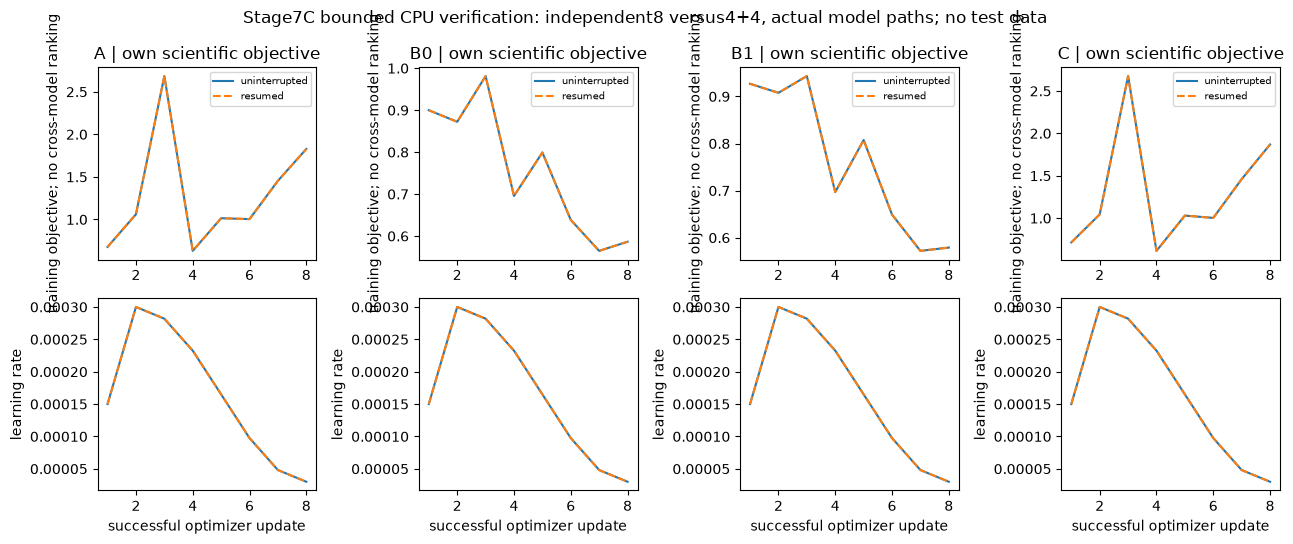

B1 diagnostic preserves ['coefficient_memory', 'equation_nodes', 'gradients', 'objectives', 'observation_tokens', 'preconditioner', 'predicted_field', 'residuals', 'sensor_predictions', 'spatial_memory', 'steps', 'trajectory'] | no full tensors printed.
Artifacts: three distinct kinds; every required module strict-loaded; D posterior summaries independently reproduced.
Acceptance: full notebook complete; source/config guards active; no automatic retraining or substantial research launch. STOP.
Section 15 accepted | source 13899bca08f8 | active configuration identities {'CONFIG': {'owner': 'pdeep-06', 'identity': '74e91dcccf787d28570975ff97a25bed227e606de04b6dc64b4bc0319a1047ce'}, 'NORMALIZERS': {'owner': 'pdeep-15', 'identity': 'b08242e6946c4612b24523bf27dc087f2f4e38d0de758555d1775b8b0bc377a2'}, 'TRAIN_CONFIGS': {'owner': '98c696c3', 'identity': 'd7d6f9d6827a2d9cb529d61266d7e5f197954f70b06b931e1cb6cfbe9f361ae9'}, 'EVAL_CONFIG': {'owner': 'bd11965a', 'identity': 'e00416a1366932bd63ef42e

In [38]:
with NOTEBOOK_LEDGER.cell('d8a7cf1b',globals()):
    import matplotlib.pyplot as plt
    fig,axes=plt.subplots(2,4,figsize=(13,5.5))
    for column,(name,row) in enumerate(PERSISTENCE_REPORT["neural_checks"].items()):
        for lane,style in (("uninterrupted","-"),("resumed","--")):
            directory=Path(row["processes"][lane]["run_directory"])
            trace=[json.loads(line) for line in (directory/"continuation_trace.jsonl").read_text().splitlines()]
            steps=[v["successful"] for v in trace]
            axes[0,column].plot(steps,[v["loss"] for v in trace],style,label=lane)
            axes[1,column].plot(steps,[v["learning_rate"] for v in trace],style,label=lane)
        axes[0,column].set_title(name+" | own scientific objective")
        axes[0,column].set_ylabel("training objective; no cross-model ranking")
        axes[1,column].set(xlabel="successful optimizer update",ylabel="learning rate")
        axes[0,column].legend(fontsize=7)
    fig.suptitle("Stage7C bounded CPU verification: independent8 versus4+4, actual model paths; no test data")
    fig.tight_layout()
    HISTORY_PLOT=PREVIEW_PATH.parent/"resume_histories.png"
    fig.savefig(HISTORY_PLOT,dpi=125,bbox_inches="tight");display(fig);plt.close(fig)
    B1_DIAGNOSTIC=read_payload(PERSISTENCE_REPORT["neural_checks"]["B1"]["end_to_end"]["diagnostic_bundle"],kind="diagnostic_bundle")[0]
    print("B1 diagnostic preserves",list(B1_DIAGNOSTIC["diagnostic_summary"]["intermediates"]),"| no full tensors printed.")
    print("Artifacts: three distinct kinds; every required module strict-loaded; D posterior summaries independently reproduced.")
    print("Acceptance: full notebook complete; source/config guards active; no automatic retraining or substantial research launch. STOP.")
print("Section 15 accepted | source",SOURCE_ID[:12],"| active configuration identities",NOTEBOOK_LEDGER.snapshot()["bindings"])
